## Import

In [46]:
import gc, io, os, re, sys, time, warnings, random, itertools, math, json, inspect
import h5py, kaolin, pywt, optuna
from contextlib import nullcontext as _null
import multiprocessing as mp
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import matplotlib.animation as animation
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from contextlib import redirect_stderr
from pathlib import Path
from typing import Dict, List, Optional
from collections import OrderedDict
from dataclasses import dataclass
from tqdm import tqdm
from rdkit import Chem
from rdkit.Chem import Draw, rdFingerprintGenerator, rdMolDescriptors, rdPartialCharges, rdmolops
from rdkit.Chem.Draw import rdMolDraw2D
from scipy.stats import kendalltau, spearmanr, rankdata, skew, kurtosis, boxcox, ks_2samp, pearsonr, qmc
from scipy.spatial.distance import pdist, squareform, cdist
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, KFold, RepeatedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, roc_auc_score, accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor, RidgeCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, RationalQuadratic, WhiteKernel
from torch.utils.data import Dataset, DataLoader, random_split, Subset, TensorDataset, IterableDataset
from torch.utils.tensorboard import SummaryWriter
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR, ReduceLROnPlateau, LambdaLR
from torch.amp import GradScaler, autocast

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

plt.rcParams.update({
    "figure.dpi": 200, "font.family": "serif", "font.size": 12,
    "axes.labelsize": 14, "axes.titlesize": 13, "xtick.labelsize": 11,
    "ytick.labelsize": 11, "figure.titlesize": 16
})

SEED = 42
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
np.random.seed(SEED); random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [2]:
def read_sheet(path, cols):
    return pd.read_excel(path, sheet_name=0, header=None, skiprows=1) \
             .iloc[:, :len(cols)].set_axis(cols, axis=1)

def parse_std(s):
    s = str(s).replace(',', '.').strip()
    m = re.search(r'([\d.]+)\s*±\s*([\d.]+)', s)
    if m: return float(m.group(1)), float(m.group(2))
    try: return float(s), float(s) * 0.07
    except: return np.nan, np.nan

def load_and_prepare(data_dir='data'):
    c6 = ['Round','ML','Rank','No.','ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm','Fa_max','Fa_ave','d','Q']
    c5 = ['No.','ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm','Fa_max','Fa_ave','d','Q','G','Tanδ','k']
    cc = ['ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm']

    df = pd.concat([
        read_sheet(f'{data_dir}/41586_2025_9269_MOESM5_ESM.xlsx', c5),
        read_sheet(f'{data_dir}/41586_2025_9269_MOESM6_ESM.xlsx', c6)
    ], ignore_index=True)[cc + ['Fa_max','Fa_ave']]

    for c in cc + ['Fa_max']:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')

    df = df.dropna(subset=cc)
    df = df[~df[cc].round(4).duplicated()].reset_index(drop=True)

    df[cc] = df[cc].div(df[cc].sum(axis=1), axis=0)

    parsed = df['Fa_ave'].apply(parse_std)
    df['Fa_mean'] = parsed.apply(lambda x: x[0])
    df['Fa_std']  = parsed.apply(lambda x: x[1])

    mask = df['Fa_mean'].isna() & df['Fa_max'].notna()
    df.loc[mask, 'Fa_mean'] = df.loc[mask, 'Fa_max']
    df.loc[mask, 'Fa_std']  = df.loc[mask, 'Fa_mean'] * 0.05

    df = df[df['Fa_mean'] > 0].copy()
    return df.reset_index(drop=True), cc

mon_cols = ['ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm']
df, comp_cols = load_and_prepare()

#import data 
adhesion = df['Fa_mean'].values  
fractions_base_line = df.iloc[:, 0:6].to_numpy()

In [3]:
df

,ΦHEA,ΦBA,ΦCBEA,ΦATAC,ΦPEA,ΦAAm,Fa_max,Fa_ave,Fa_mean,Fa_std
0,0.518703,0.199302,0.094768,0.187226,0.000000,0.0,22.36,19.89±1.76,19.89,1.76
1,0.421787,0.406214,0.171999,0.000000,0.000000,0.0,12.57,11.06±1.94,11.06,1.94
2,0.536864,0.108375,0.184067,0.170693,0.000000,0.0,10.93,10.13±0.79,10.13,0.79
3,0.216356,0.199474,0.088142,0.174303,0.321725,0.0,126.82,109.57±12.43,109.57,12.43
4,0.119821,0.410078,0.191813,0.187167,0.091121,0.0,109.27,94.89±10.59,94.89,10.59
...,...,...,...,...,...,...,...,...,...,...
342,0.000000,0.640000,0.000000,0.070000,0.290000,0.0,235.47,219.32±19.58,219.32,19.58
343,0.000000,0.600000,0.000000,0.070000,0.330000,0.0,225.39,198.48±21.60,198.48,21.60
344,0.000000,0.606000,0.000000,0.081000,0.313000,0.0,229.75,216.26±12.41,216.26,12.41
345,0.000000,0.666000,0.000000,0.081000,0.253000,0.0,232.07,215.24±17.31,215.24,17.31


## Data update

### Make FFP and 2D

In [4]:
monomers = {
    'HEA': 'C=CC(=O)OCCO',                            # 2-Hydroxyethyl acrylate
    'BA': 'C=CC(=O)OCCCC',                            # Butyl acrylate
    'CBEA': 'C=CC(=O)OCCC(=O)O',                      # Carboxyethyl acrylate
    'ATAC': 'C=CC(=O)OCC[N+](C)(C)C',                 # [2-(Acryloyloxy)ethyl]trimethylammonium
    'PEA': 'C=CC(=O)OCCOc1ccccc1',                    # 2-Phenoxyethyl acrylate
    'AAm': 'C=CC(=O)N'                                # Acrylamide
}
mon_names = list(monomers.keys())
mon_smiles = list(monomers.values())
mon_mols = [Chem.MolFromSmiles(s) for s in mon_smiles]

In [5]:
def custom_2d_autocorr_for_metrics(mol, lags=8):
    if mol is None or mol.GetNumAtoms() < 2:
        return np.zeros(3 * lags, dtype=np.float32)
    mol_calc = Chem.Mol(mol)
    rdPartialCharges.ComputeGasteigerCharges(mol_calc)
    dm = rdmolops.GetDistanceMatrix(mol_calc)
    contribs = rdMolDescriptors._CalcCrippenContribs(mol_calc)
    logp_arr = np.array([c[0] for c in contribs], dtype=np.float32)
    charge_arr = np.array([float(a.GetProp('_GasteigerCharge')) if a.HasProp('_GasteigerCharge') else 0.0 for a in mol_calc.GetAtoms()], dtype=np.float32)
    arom_arr = np.array([1.0 if atom.GetIsAromatic() or atom.GetHybridization() == Chem.HybridizationType.SP2 else 0.0 for atom in mol_calc.GetAtoms()], dtype=np.float32)
    prop_arrays = [logp_arr, charge_arr, arom_arr]
    autocorr_vec = []
    for prop_arr in prop_arrays:
        for lag in range(1, lags + 1):
            mask = (dm == lag)
            upper_mask = np.triu(mask, k=1)
            i_idx, j_idx = np.where(upper_mask)
            if len(i_idx) == 0:
                autocorr_vec.append(0.0)
            else:
                autocorr_vec.append(np.sum(prop_arr[i_idx] * prop_arr[j_idx]) / len(i_idx))
    return np.array(autocorr_vec, dtype=np.float32)

sizes = [2048, 16384, 1024, 512, 256, 128]
fps_data = []
for s in sizes:
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=s, atomInvariantsGenerator=rdFingerprintGenerator.GetMorganFeatureAtomInvGen())
    bin_arr = np.array([list(gen.GetFingerprint(mol)) for mol in mon_mols], dtype=np.int8)
    cnt_arr = np.array([gen.GetCountFingerprintAsNumPy(mol) for mol in mon_mols], dtype=np.uint16)
    fps_data.append((bin_arr, cnt_arr))
(ffp_arrays, cffp_arrays), (ffp_array, cffp_array), (ffp_arrays1, cffp_arrays1), (ffp_arrays2, cffp_arrays2), (ffp_arrays3, cffp_arrays3), (ffp_arrays4, cffp_arrays4) = fps_data

custom_feats = [custom_2d_autocorr_for_metrics(mol, lags=8) for mol in mon_mols]
rdkit_feats = [rdMolDescriptors.CalcAUTOCORR2D(mol) for mol in mon_mols]
merged = [np.concatenate([c, r]) for c, r in zip(custom_feats, rdkit_feats)]
autocorr_2d_arrays = np.array(merged, dtype=np.float32)


val_df = pd.DataFrame({
    'autocorr': list(autocorr_2d_arrays),
    'cffp_256': list(cffp_arrays3),
}, index=list(monomers.keys()))

In [6]:
val_df

,autocorr,cffp_256
HEA,"[0.022371456, 0.008917488, 0.0069393865, 0.012...","[5, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
BA,"[0.008565082, -0.0035981897, -0.016295668, -0....","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
CBEA,"[0.012207642, 0.0016877461, 0.004259186, 0.012...","[5, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
ATAC,"[0.037416205, 0.024702458, 0.01881262, 0.01488...","[8, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
PEA,"[0.016208153, 0.0073456024, -0.008653098, -0.0...","[5, 0, 3, 0, 6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
AAm,"[0.07673699, -0.017345022, -0.09085759, 0.0, 0...","[3, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [7]:

col_to_mon = {'ΦHEA': 'HEA', 'ΦBA': 'BA', 'ΦCBEA': 'CBEA', 'ΦATAC': 'ATAC', 'ΦPEA': 'PEA', 'ΦAAm': 'AAm'}
name_to_idx = {name: i for i, name in enumerate(val_df.index)}
mon_indices = np.array([name_to_idx[col_to_mon[col]] for col in mon_cols], dtype=np.int32)
features_source = {
    'autocorr': (autocorr_2d_arrays, np.float32),
    'cffp_256': (cffp_arrays3, np.uint16)
}

In [8]:
comp = df[mon_cols].values.astype(np.float64)
row_sums = comp.sum(axis=1, keepdims=True)
comp = np.where(row_sums > 1.5, comp / 100.0, comp)
row_sums = comp.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1.0
comp /= row_sums
valid_mask = comp.sum(axis=1) > 0
valid_comps = comp[valid_mask]
n_poly_valid = int(valid_mask.sum())

np.random.seed(42)
N_mon, batch_size = 1000, 256

def flush_batch(datasets, buffers, count, size):
    for name in datasets:
        datasets[name][count:count+size] = buffers[name][:size]

with h5py.File('./data/DL/small_poly_datasets.h5', 'w') as f:
    hdf_datasets, buffers = {}, {}
    for name, (src, dtype) in features_source.items():
        shape_3d = (n_poly_valid, N_mon, src.shape[1])
        chunk_shape = (min(batch_size, n_poly_valid), N_mon, src.shape[1])
        hdf_datasets[name] = f.create_dataset(
            name, shape=shape_3d, dtype=dtype,
            compression="gzip", compression_opts=4,
            chunks=chunk_shape, shuffle=True
        )
        buffers[name] = np.empty((batch_size, N_mon, src.shape[1]), dtype=dtype)

    buf_idx = saved_count = 0
    for fracs in valid_comps:
        exact = fracs * N_mon
        counts = np.floor(exact).astype(np.int32)
        diff = N_mon - counts.sum()
        if diff > 0:
            rem_indices = np.argsort(exact % 1)[::-1]
            counts[rem_indices[:diff]] += 1
        global_chain = np.repeat(mon_indices, counts)
        np.random.shuffle(global_chain)
        for name, (src, _) in features_source.items():
            buffers[name][buf_idx] = src[global_chain]
        buf_idx += 1
        if buf_idx == batch_size:
            flush_batch(hdf_datasets, buffers, saved_count, batch_size)
            saved_count += batch_size
            buf_idx = 0
            sys.stdout.write(f"typed:{saved_count}/{n_poly_valid}...\r")
            sys.stdout.flush()
    if buf_idx > 0:
        flush_batch(hdf_datasets, buffers, saved_count, buf_idx)
        saved_count += buf_idx
        sys.stdout.write(f"typed: {saved_count}/{n_poly_valid}...\r")
        sys.stdout.flush()

print(f"\n N:{n_poly_valid} in 'small_poly_datasets.h5'!")

typed: 347/347...
 N:347 in 'small_poly_datasets.h5'!


In [9]:
with h5py.File('./data/DL/small_poly_datasets.h5', 'r') as f:
    print(f"{'Name':<20} | {'Shape':<20} | {'Type':<10}")
    print("-" * 60)
    for key in f:
        obj = f[key]
        print(f"{key:<20} | {str(obj.shape):<20} | {str(obj.dtype):<10}" if isinstance(obj, h5py.Dataset) else f"{key:<20}")

Name                 | Shape                | Type      
------------------------------------------------------------
autocorr             | (347, 1000, 216)     | float32   
cffp_256             | (347, 1000, 256)     | uint16    


### New_poly_base

In [10]:
dfb = pd.read_csv('./data/poly_base.csv', sep=',')

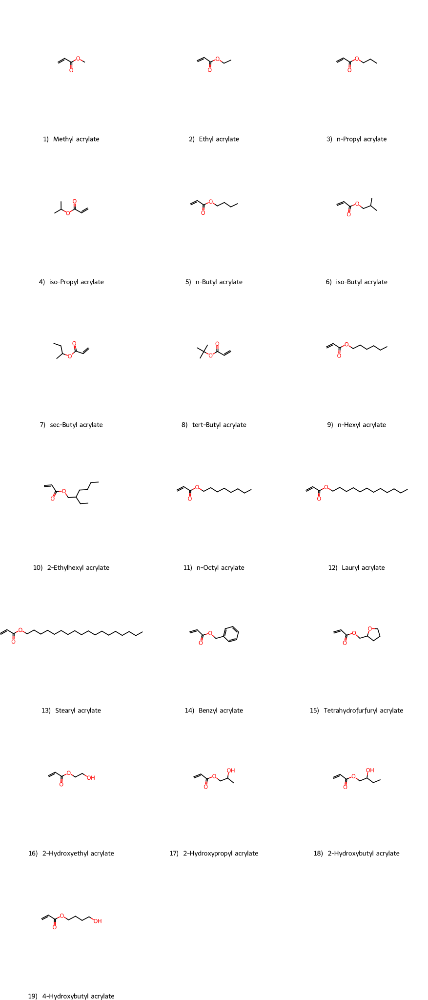

In [11]:
mols = [Chem.MolFromSmiles(s) for s in dfb['smiles']][:19]
leg = [f"{r['number']})  {r['name']}"for _, r in dfb.iterrows()][:19]
d=rdMolDraw2D.MolDrawOptions()
d.bondLineWidth=2
d.minFontSize=14
d.padding=0.0
Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(350, 350), legends=leg, useSVG = True, drawOptions=d)

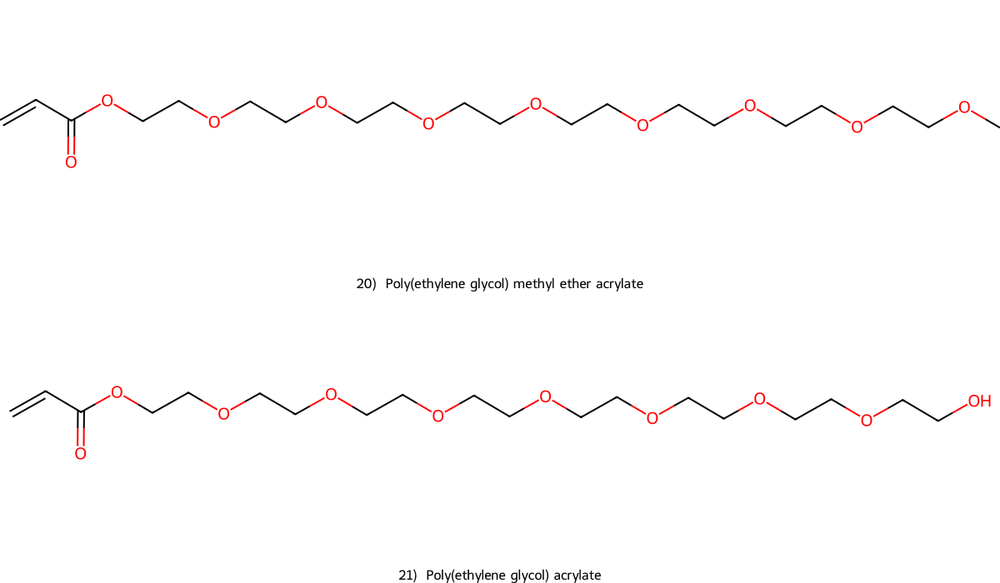

In [12]:
mols = [Chem.MolFromSmiles(s) for s in dfb['smiles']][:21][19:]
leg = [f"{r['number']})  {r['name']}"for _, r in dfb.iterrows()][:21][19:]
d=rdMolDraw2D.MolDrawOptions()
d.bondLineWidth=2
d.minFontSize=14
d.padding=0.0
Draw.MolsToGridImage(mols, molsPerRow=1, subImgSize=(1200, 350), legends=leg, useSVG = True, drawOptions=d)

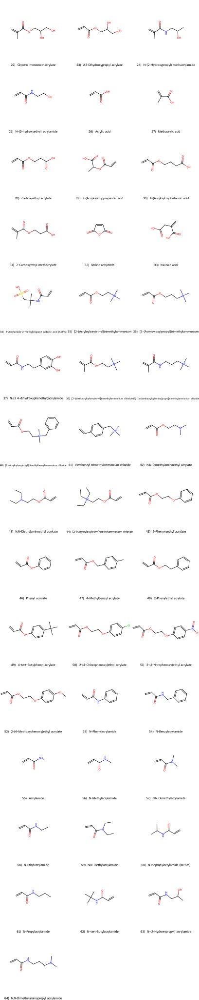

In [13]:
mols = [Chem.MolFromSmiles(s) for s in dfb['smiles']][21:]
leg = [f"{r['number']})  {r['name']}"for _, r in dfb.iterrows()][21:]
d=rdMolDraw2D.MolDrawOptions()
d.bondLineWidth=2
d.minFontSize=14
d.padding=0.0
Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(350, 350), legends=leg, useSVG = True, drawOptions=d)

In [14]:
dfb

,number,name,family,smiles
0,1,Methyl acrylate,Alkyl Acrylates,C=CC(=O)OC
1,2,Ethyl acrylate,Alkyl Acrylates,C=CC(=O)OCC
2,3,n-Propyl acrylate,Alkyl Acrylates,C=CC(=O)OCCC
3,4,iso-Propyl acrylate,Alkyl Acrylates,C=CC(=O)OC(C)C
4,5,n-Butyl acrylate,Alkyl Acrylates,C=CC(=O)OCCCC
...,...,...,...,...
59,60,N-Isopropylacrylamide (NIPAM),Acrylamides,C=CC(=O)NC(C)C
60,61,N-Propylacrylamide,Acrylamides,C=CC(=O)NCCC
61,62,N-tert-Butylacrylamide,Acrylamides,C=CC(=O)NC(C)(C)C
62,63,N-(2-Hydroxypropyl) acrylamide,Acrylamides,C=CC(=O)NCC(C)O


In [15]:
smiles_list = dfb['smiles']

In [16]:
mon_mols = []
valid_indices = []
for i, smi in enumerate(smiles_list):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        mon_mols.append(mol)
        valid_indices.append(i)
    else:
        print(f"Warning: invalid SMILES at row {i}: {smi}")

custom_feats = [custom_2d_autocorr_for_metrics(mol) for mol in mon_mols]
rdkit_feats = [rdMolDescriptors.CalcAUTOCORR2D(mol) for mol in mon_mols]
autocorr_2d_arrays = np.array([np.concatenate([c, r]) for c, r in zip(custom_feats, rdkit_feats)], dtype=np.float32)

def _gen_fps(size):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=size, atomInvariantsGenerator=rdFingerprintGenerator.GetMorganFeatureAtomInvGen())
    return (np.array([list(gen.GetFingerprint(mol)) for mol in mon_mols], dtype=np.int8),
            np.array([gen.GetCountFingerprintAsNumPy(mol) for mol in mon_mols], dtype=np.uint16))

(ffp_arrays3, cffp_arrays3) = _gen_fps(256)

valid_df = dfb.iloc[valid_indices].reset_index(drop=True)
valid_df['autocorr'] = list(autocorr_2d_arrays)
valid_df['cffp_256'] = list(cffp_arrays3)

In [17]:
valid_df

,number,name,family,smiles,autocorr,cffp_256
0,1,Methyl acrylate,Alkyl Acrylates,C=CC(=O)OC,"[0.011263078, -0.0020739068, -0.008696463, -0....","[4, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,2,Ethyl acrylate,Alkyl Acrylates,C=CC(=O)OCC,"[0.0044985064, -0.0033709956, -0.0149777755, -...","[5, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,3,n-Propyl acrylate,Alkyl Acrylates,C=CC(=O)OCCC,"[0.0068222643, -0.007078618, -0.014124219, -0....","[6, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,4,iso-Propyl acrylate,Alkyl Acrylates,C=CC(=O)OC(C)C,"[-0.00038357027, -0.0011090415, -0.019165983, ...","[6, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,5,n-Butyl acrylate,Alkyl Acrylates,C=CC(=O)OCCCC,"[0.008565082, -0.0035981897, -0.016295668, -0....","[7, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...,...,...,...
59,60,N-Isopropylacrylamide (NIPAM),Acrylamides,C=CC(=O)NC(C)C,"[0.043895867, -0.024408646, -0.035741005, -0.0...","[6, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, ..."
60,61,N-Propylacrylamide,Acrylamides,C=CC(=O)NCCC,"[0.05095514, -0.020507175, -0.046098724, -0.01...","[6, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, ..."
61,62,N-tert-Butylacrylamide,Acrylamides,C=CC(=O)NC(C)(C)C,"[0.03471452, -0.023272084, -0.03636415, -0.004...","[7, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, ..."
62,63,N-(2-Hydroxypropyl) acrylamide,Acrylamides,C=CC(=O)NCC(C)O,"[0.054595485, 0.013491831, 0.0036967525, 0.001...","[6, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, ..."


In [18]:
valid_df.to_csv('./data/DL/monomers_with_descriptors.csv', index=False)

In [19]:
ffp_list = valid_df['cffp_256'].tolist()
auto_list = valid_df['autocorr'].tolist()
mono_feat = np.concatenate([np.array(ffp_list, dtype=np.float32),
                            np.array(auto_list, dtype=np.float32)], axis=1)  # shape (64, 472)
mono_feat_tensor = torch.tensor(mono_feat, dtype=torch.float32, device=device)
ffp_arr_64 = np.array(valid_df['cffp_256'].tolist(), dtype=np.float32)
auto_arr_64 = np.array(valid_df['autocorr'].tolist(), dtype=np.float32)
mono_feat_tensor = torch.tensor(np.concatenate([ffp_arr_64, auto_arr_64], axis=1), device=device)
mon_indices_64 = np.arange(64)
features_source_64 = {
    'autocorr': (auto_arr_64, np.float32),
    'cffp_256': (ffp_arr_64, np.float32)
}
num_monomers = len(ffp_list)
ffp_len, auto_len = len(ffp_list[0]), len(auto_list[0])

## Data analyze 

In [20]:
#### Distribution

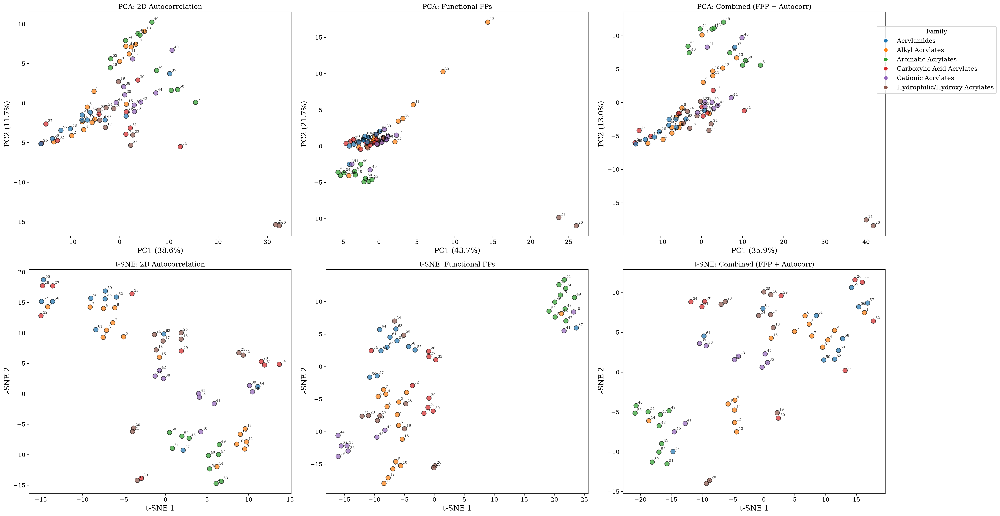

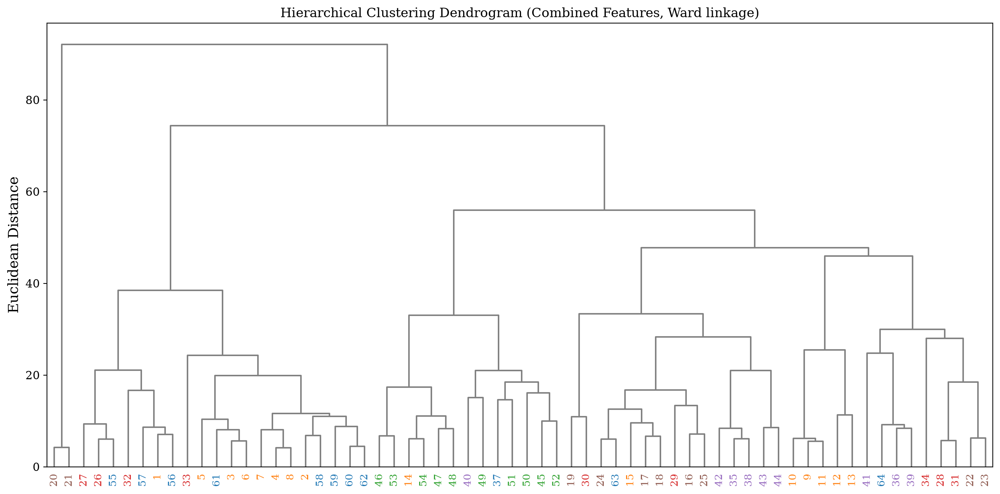

In [21]:
scaler = StandardScaler()
X_autocorr = scaler.fit_transform(autocorr_2d_arrays)
X_ffp = cffp_arrays3.astype(np.float32)
X_combined = np.concatenate([X_ffp, X_autocorr], axis=1)

families = valid_df['family'].values
numbers = valid_df['number'].values

unique_families = np.unique(families)
palette = sns.color_palette('tab10', len(unique_families))
fam2col = dict(zip(unique_families, palette))
colors = [fam2col[f] for f in families]

def plot_pca_tsne_grid(X_list, titles, numbers, colors, families, fam2col):
    fig, axes = plt.subplots(2, 3, figsize=(24,14))
    for col, (X, ttl) in enumerate(zip(X_list, titles)):
        for row, (transform, name) in enumerate(zip(
            [PCA(n_components=2, random_state=42), TSNE(n_components=2, random_state=42, perplexity=10)],
            ['PCA', 't-SNE'])):
            X_2d = transform.fit_transform(X)
            ax = axes[row, col]
            ax.scatter(X_2d[:,0], X_2d[:,1], c=colors, edgecolors='k', s=80, alpha=0.7)
            for i, num in enumerate(numbers):
                ax.annotate(str(num), (X_2d[i,0], X_2d[i,1]), textcoords="offset points", xytext=(4,4), fontsize=7, alpha=0.8)
            ax.set_title(f'{name}: {ttl}')
            if row == 0:
                ax.set_xlabel(f'PC1 ({transform.explained_variance_ratio_[0]:.1%})')
                ax.set_ylabel(f'PC2 ({transform.explained_variance_ratio_[1]:.1%})')
            else:
                ax.set_xlabel('t-SNE 1')
                ax.set_ylabel('t-SNE 2')
    handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=fam2col[f], markersize=8, label=f) for f in unique_families]
    fig.legend(handles=handles, title='Family', loc='upper right', bbox_to_anchor=(1.12,0.95))
    plt.tight_layout()
    plt.show()

X_list = [X_autocorr, X_ffp, X_combined]
titles = ['2D Autocorrelation', 'Functional FPs', 'Combined (FFP + Autocorr)']
plot_pca_tsne_grid(X_list, titles, numbers, colors, families, fam2col)

dist_combined = pdist(X_combined, metric='euclidean')
Z = linkage(dist_combined, method='ward')
plt.figure(figsize=(14,7))
dendrogram(Z, labels=[str(n) for n in numbers], leaf_rotation=90, leaf_font_size=10,
           color_threshold=0, above_threshold_color='gray', link_color_func=lambda k: 'gray')
ax = plt.gca()
for lbl in ax.get_xmajorticklabels():
    idx = np.where(numbers == int(lbl.get_text()))[0][0]
    lbl.set_color(fam2col[families[idx]])
plt.title('Hierarchical Clustering Dendrogram (Combined Features, Ward linkage)')
plt.ylabel('Euclidean Distance')
plt.tight_layout()
plt.show()

In [22]:
#### orig + sinthetic 

Small shape: (347, 216), Deep shape: (20000, 216)
Mean KS p-value: 0.0000


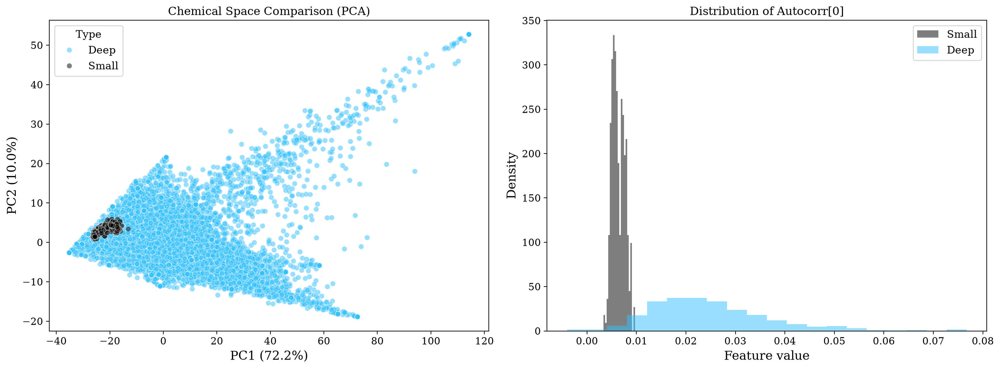

In [23]:
def compare_stream_vs_experimental(n_synthetic=20000):
    small_3d = []
    for fracs in valid_comps:
        exact = fracs * 1000
        counts = np.floor(exact).astype(np.int32)
        diff = 1000 - counts.sum()
        if diff > 0:
            rem_indices = np.argsort(exact % 1)[::-1]
            counts[rem_indices[:diff]] += 1
        global_chain = np.repeat(mon_indices, counts)
        np.random.shuffle(global_chain)
        small_3d.append(autocorr_2d_arrays[global_chain])
    small_feat = np.mean(np.array(small_3d), axis=1)

    deep_feats = []
    for _ in range(n_synthetic):
        k = random.randint(1, 7)
        idxs = random.sample(range(num_monomers), k)
        r = np.random.dirichlet(np.ones(k))
        exact = r * 1000
        cnt = np.floor(exact).astype(np.int64)
        d = 1000 - int(cnt.sum())
        if d > 0:
            cnt[np.argsort(-(exact - cnt))[:d]] += 1
        chain = np.repeat(np.array(idxs), cnt)
        np.random.shuffle(chain)
        deep_feats.append(autocorr_2d_arrays[chain].mean(axis=0))
    deep_feat = np.array(deep_feats)

    print(f"Small shape: {small_feat.shape}, Deep shape: {deep_feat.shape}")

    # KS-test
    ks_p = [ks_2samp(small_feat[:, i], deep_feat[:, i])[1] for i in range(min(24, small_feat.shape[1]))]
    print(f"Mean KS p-value: {np.mean(ks_p):.4f}")

    # PCA
    combined = np.vstack([small_feat, deep_feat])
    labels = ['Small'] * len(small_feat) + ['Deep'] * len(deep_feat)
    pca = PCA(n_components=2, random_state=42)
    pca_res = pca.fit_transform(combined)

    df_plot = pd.DataFrame(pca_res, columns=['PC1', 'PC2'])
    df_plot['Type'] = labels
    df_plot = pd.concat([df_plot[df_plot['Type'] == 'Deep'], df_plot[df_plot['Type'] == 'Small']])

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.scatterplot(data=df_plot, x='PC1', y='PC2', hue='Type', alpha=0.5,
                    palette={'Small': '#000000', 'Deep': '#33C1FF'}, ax=axes[0])
    axes[0].set_title('Chemical Space Comparison (PCA)')
    axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

    axes[1].hist(small_feat[:, 0], bins=20, alpha=0.5, label='Small', color='#000000', density=True)
    axes[1].hist(deep_feat[:, 0], bins=20, alpha=0.5, label='Deep', color='#33C1FF', density=True)
    axes[1].set_title('Distribution of Autocorr[0]')
    axes[1].set_xlabel('Feature value')
    axes[1].set_ylabel('Density')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

compare_stream_vs_experimental()

In [24]:
#### poisson check

In [25]:
def gen_chain(n_m, seq_len=1000):
    k = random.randint(1, 7)
    idxs = random.sample(range(n_m), k)
    exact = np.random.dirichlet(np.ones(k)) * seq_len
    cnt = np.floor(exact).astype(int)
    if (d := seq_len - cnt.sum()) > 0: cnt[np.argsort(-(exact - cnt))[:d]] += 1
    ch = np.repeat(idxs, cnt); np.random.shuffle(ch); return ch

random.seed(42); np.random.seed(42)
cffp_mono  = cffp_arrays3.astype(np.float64)
cffp_chain = np.concatenate([cffp_arrays3[gen_chain(num_monomers)] for _ in range(5000)]).astype(np.float64)

def poisson_check(X, name, lo=0.7, hi=1.5):
    m, v = X.mean(0), X.var(0, ddof=1)
    disp = v[m > 1e-3] / m[m > 1e-3]
    ex   = (X == 0).mean(0) - np.exp(-m)
    adq  = np.mean((disp >= lo) & (disp <= hi))
    ok   = (np.median(disp) < 1.2) and (np.mean(disp > hi) < 0.25) and (np.abs(ex.mean()) < 0.02)
    print(f"[{name:7s}] N={X.shape[0]:>8} | disp med={np.median(disp):.3f} IQR=({np.percentile(disp,25):.2f},{np.percentile(disp,75):.2f}) | adequate={adq:.1%} | overdisp={np.mean(disp > hi):.1%} | zero-ex={ex.mean():+.4f} | -> {'Poisson OK' if ok else 'use NB'}")

poisson_check(cffp_mono, "monomer")
poisson_check(cffp_chain, "chain")

[monomer] N=      64 | disp med=1.000 IQR=(0.97,1.00) | adequate=78.6% | overdisp=16.4% | zero-ex=+0.0044 | -> Poisson OK
[chain  ] N= 5000000 | disp med=0.983 IQR=(0.95,0.99) | adequate=78.6% | overdisp=16.4% | zero-ex=+0.0043 | -> Poisson OK


In [26]:
ffp_std  = cffp_arrays3.astype(np.float32).std()
auto_std = autocorr_2d_arrays.std()  
print(ffp_std, auto_std)

0.71256906 3.9656937


In [44]:
def _gen_chain(n_m, L=1000):
    k = random.randint(1, 7); ix = random.sample(range(n_m), k)
    ex = np.random.dirichlet(np.ones(k)) * L; c = np.floor(ex).astype(int)
    if (d := L - c.sum()) > 0: c[np.argsort(-(ex - c))[:d]] += 1
    ch = np.repeat(ix, c); np.random.shuffle(ch); return ch
@torch.no_grad()
def _Ls(m, lt, n=64):
    random.seed(42); np.random.seed(42)
    ch = np.stack([_gen_chain(num_monomers) for _ in range(n)])
    f = torch.from_numpy(cffp_arrays3[ch]).float().to(device)
    a = torch.from_numpy(autocorr_2d_arrays[ch]).float().to(device)
    m.eval(); rf, ra, _, _ = m(f, a)
    if lt == 'cls':
        return (F.poisson_nll_loss(rf, f, log_input=False, full=True, reduction='mean').item(), 
                F.mse_loss(ra, a).item())
    return (chamfer_distance(rf, f).item(), 
            chamfer_distance(ra, a).item())

def _eval_with_seed(cls, lt, s):
    torch.manual_seed(s)
    return _Ls(cls(**model_config).to(device), lt)
for name, cls, lt in [('CLS', TransformerVAE_CLS, 'cls'), ('SET', TransformerVAE_SET, 'set'), ('DS', VAE_DeepSets, 'set')]:
    Ls = [_eval_with_seed(cls, lt, s) for s in (0, 1, 2)]
    w_ffp_raw = np.mean([a / b for b, a in Ls]) # L_auto / L_ffp
    if lt == 'set':
        w_ffp_norm = w_ffp_raw * (0.7**2) / (4**2)
        print(f"{name}: w_ffp_raw = {w_ffp_raw:.2f} | w_ffp_norm ( std) = {w_ffp_norm:.3f}, w_auto = 1.00")
    else:
        print(f"{name}: w_ffp = {w_ffp_raw:.2f},  w_auto = 1.00")

CLS: w_ffp = 19.25,  w_auto = 1.00
SET: w_ffp_raw = 11.22 | w_ffp_norm ( std) = 0.344, w_auto = 1.00
DS: w_ffp_raw = 13.03 | w_ffp_norm ( std) = 0.399, w_auto = 1.00


# DeepLearning Part

#### Model 

In [27]:
class RotaryPositionalEmbeddings(nn.Module):
    def __init__(self, dim, max_seq_len=1024, base=10000):
        super().__init__()
        self.dim = dim
        self.base = base
        self.max_seq_len = max_seq_len
        self.rope_init()

    def rope_init(self):
        theta = 1.0 / (self.base ** (torch.arange(0, self.dim, 2).float() / self.dim))
        self.register_buffer("theta", theta, persistent=False)
        self.build_rope_cache(self.max_seq_len)

    def build_rope_cache(self, max_seq_len):
        seq_idx = torch.arange(max_seq_len, dtype=self.theta.dtype, device=self.theta.device)
        idx_theta = torch.einsum("i, j -> ij", seq_idx, self.theta).float()
        cache = torch.stack([torch.cos(idx_theta), torch.sin(idx_theta)], dim=-1)
        self.register_buffer("cache", cache, persistent=False)

    def forward(self, x, input_pos=None):
        seq_len = x.size(1)
        if input_pos is None:
            input_pos = torch.arange(seq_len, device=x.device)
        input_pos = input_pos.to(device=self.cache.device, dtype=torch.long)
        cache = self.cache[input_pos]
        if cache.dim() == 3:
            cache = cache.unsqueeze(0)
        cache = cache.unsqueeze(2)
        xshaped = x.float().reshape(*x.shape[:-1], -1, 2)
        x_out = torch.stack([
            xshaped[..., 0] * cache[..., 0] - xshaped[..., 1] * cache[..., 1],
            xshaped[..., 0] * cache[..., 1] + xshaped[..., 1] * cache[..., 0],
        ], dim=-1)
        return x_out.flatten(-2).type_as(x)


class RoPEAttention(nn.Module):
    def __init__(self, d_model, nhead, dropout=0.1, max_seq_len=1024, base=10000):
        super().__init__()
        assert d_model % nhead == 0
        assert (d_model // nhead) % 2 == 0, "RoPE requires even head_dim"
        self.nhead = nhead
        self.head_dim = d_model // nhead
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryPositionalEmbeddings(dim=self.head_dim, max_seq_len=max_seq_len, base=base)

    def forward(self, x, mask=None, input_pos=None):
        b, n, _ = x.shape
        q, k, v = self.qkv(x).reshape(b, n, 3, self.nhead, self.head_dim).unbind(dim=2)
        q = self.rope(q, input_pos)
        k = self.rope(k, input_pos)
        q, k, v = q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2)
        attn = (q @ k.transpose(-2, -1)) * (self.head_dim ** -0.5)
        if mask is not None:
            if mask.dim() == 3:
                mask = mask[:, None, :, :]
            if mask.dtype == torch.bool:
                attn = attn.masked_fill(~mask, torch.finfo(attn.dtype).min)
            else:
                attn = attn + mask
        attn = self.drop(F.softmax(attn, dim=-1))
        return self.out((attn @ v).transpose(1, 2).reshape(b, n, -1))


class RoPEEncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward, dropout, max_seq_len):
        super().__init__()
        self.attn = RoPEAttention(d_model, nhead, dropout, max_seq_len)
        self.ff = nn.Sequential(nn.Linear(d_model, dim_feedforward), nn.Mish(), nn.Dropout(dropout),
                                nn.Linear(dim_feedforward, d_model), nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x, mask=None):
        x = x + self.attn(self.norm1(x), mask)
        return x + self.ff(self.norm2(x))


class RoPEEncoder(nn.Module):
    def __init__(self, d_model, nhead, num_layers, dim_feedforward, dropout, max_seq_len):
        super().__init__()
        self.layers = nn.ModuleList([RoPEEncoderLayer(d_model, nhead, dim_feedforward, dropout, max_seq_len)
                                     for _ in range(num_layers)])

    def forward(self, x, mask=None):
        for layer in self.layers:
            x = layer(x, mask)
        return x


class RoPEDecoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward, dropout, max_seq_len):
        super().__init__()
        self.self_attn = RoPEAttention(d_model, nhead, dropout, max_seq_len)
        self.cross_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, dim_feedforward), nn.Mish(), nn.Dropout(dropout),
                                nn.Linear(dim_feedforward, d_model), nn.Dropout(dropout))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, tgt, memory, input_pos=None, tgt_mask=None):
        tgt = tgt + self.self_attn(self.norm1(tgt), tgt_mask, input_pos)
        tgt = tgt + self.cross_attn(self.norm2(tgt), memory, memory)[0]
        return tgt + self.ff(self.norm3(tgt))


class RoPEDecoder(nn.Module):
    def __init__(self, d_model, nhead, num_layers, dim_feedforward, dropout, max_seq_len):
        super().__init__()
        self.layers = nn.ModuleList([RoPEDecoderLayer(d_model, nhead, dim_feedforward, dropout, max_seq_len)
                                     for _ in range(num_layers)])

    def forward(self, tgt, memory, input_pos=None, tgt_mask=None):
        for layer in self.layers:
            tgt = layer(tgt, memory, input_pos, tgt_mask)
        return tgt

In [28]:
class TransformerVAE_CLS(nn.Module):
    def __init__(self, ffp_dim=256, auto_dim=216, seq_len=1000, d_model=128, nhead=4, num_layers=3, latent_dim=64, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.d_model = d_model
        self.ffp_projection = nn.Linear(ffp_dim, d_model//2)
        self.auto_projection = nn.Linear(auto_dim, d_model//2)
        self.feature_fusion = nn.Linear(d_model, d_model)
        self.ffp_norm = nn.LayerNorm(d_model//2)
        self.auto_norm = nn.LayerNorm(d_model//2)
        self.feature_norm = nn.LayerNorm(d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        self.transformer_encoder = RoPEEncoder(d_model, nhead, num_layers, d_model*4, dropout, seq_len+1)
        self.fc_mu = nn.Linear(d_model, latent_dim)
        self.fc_logvar = nn.Linear(d_model, latent_dim)
        self.fc_decoder_input = nn.Linear(latent_dim, d_model)
        self.decoder_queries = nn.Parameter(torch.randn(1, seq_len, d_model))
        self.transformer_decoder = RoPEDecoder(d_model, nhead, num_layers, d_model*4, dropout, seq_len+1)
        self.output_ffp = nn.Sequential(nn.Linear(d_model, ffp_dim), nn.Softplus())
        self.output_auto = nn.Linear(d_model, auto_dim)
    
    def encode(self, ffp, auto):
        b = ffp.size(0)
        h_ffp = F.mish(self.ffp_norm(self.ffp_projection(ffp)))
        h_auto = F.mish(self.auto_norm(self.auto_projection(auto)))
        x = self.feature_norm(self.feature_fusion(torch.cat([h_ffp, h_auto], dim=-1)))
        x = torch.cat([self.cls_token.expand(b, -1, -1), x], dim=1)
        x = self.transformer_encoder(x)
        cls_out = x[:, 0, :]
        return self.fc_mu(cls_out), self.fc_logvar(cls_out)

    def reparameterize(self, mu, logvar):
        if not self.training:
            return mu
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps*std

    def decode(self, z):
        b = z.size(0)
        memory = self.fc_decoder_input(z).unsqueeze(1)
        tgt = self.decoder_queries.expand(b, -1, -1)
        input_pos = torch.arange(1, self.seq_len + 1, device=z.device)
        out = self.transformer_decoder(tgt, memory, input_pos=input_pos)
        return self.output_ffp(out), self.output_auto(out)

    def forward(self, ffp, auto):
        mu, logvar = self.encode(ffp, auto)
        z = self.reparameterize(mu, logvar)
        recon_ffp, recon_auto = self.decode(z)
        return recon_ffp, recon_auto, mu, logvar

In [29]:
class TransformerVAE_SET(nn.Module):
    def __init__(self, ffp_dim=256, auto_dim=216, seq_len=1000, d_model=128, nhead=4, num_layers=3, latent_dim=64, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.d_model = d_model
        self.ffp_projection = nn.Linear(ffp_dim, d_model//2)
        self.auto_projection = nn.Linear(auto_dim, d_model//2)
        self.feature_fusion = nn.Linear(d_model, d_model)
        self.ffp_norm = nn.LayerNorm(d_model//2)
        self.auto_norm = nn.LayerNorm(d_model//2)
        self.feature_norm = nn.LayerNorm(d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=d_model*4, dropout=dropout, batch_first=True, norm_first=True, activation=F.mish)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_mu = nn.Linear(d_model, latent_dim)
        self.fc_logvar = nn.Linear(d_model, latent_dim)
        self.fc_decoder_input = nn.Linear(latent_dim, d_model)
        self.decoder_queries = nn.Parameter(torch.randn(1, seq_len, d_model))
        decoder_layer = nn.TransformerDecoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=d_model*4, dropout=dropout, batch_first=True, norm_first=True, activation=F.mish)
        self.transformer_decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        self.output_ffp = nn.Sequential(nn.Linear(d_model, ffp_dim), nn.Softplus())
        self.output_auto = nn.Linear(d_model, auto_dim)

    def encode(self, ffp, auto):
        b = ffp.size(0)
        h_ffp = F.mish(self.ffp_norm(self.ffp_projection(ffp)))
        h_auto = F.mish(self.auto_norm(self.auto_projection(auto)))
        x = self.feature_fusion(torch.cat([h_ffp, h_auto], dim=-1))
        x = self.feature_norm(x)
        x = torch.cat([self.cls_token.expand(b, -1, -1), x], dim=1)
        x = self.transformer_encoder(x)
        cls_out = x[:, 0, :]
        return self.fc_mu(cls_out), self.fc_logvar(cls_out)

    def reparameterize(self, mu, logvar):
        if not self.training:
            return mu
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps*std

    def decode(self, z):
        b = z.size(0)
        memory = self.fc_decoder_input(z).unsqueeze(1)
        tgt = self.decoder_queries.expand(b, -1, -1)
        out = self.transformer_decoder(tgt=tgt, memory=memory)
        return self.output_ffp(out), self.output_auto(out)

    def forward(self, ffp, auto):
        mu, logvar = self.encode(ffp, auto)
        z = self.reparameterize(mu, logvar)
        recon_ffp, recon_auto = self.decode(z)
        return recon_ffp, recon_auto, mu, logvar

In [30]:
class VAE_DeepSets(nn.Module):
    def __init__(self, ffp_dim=256, auto_dim=216, seq_len=1000,
                 d_model=128, nhead=4, num_layers=3, latent_dim=64, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.latent_dim = latent_dim
        self.ffp_dim = ffp_dim
        self.auto_dim = auto_dim
        in_features = ffp_dim + auto_dim
        self.element_net = nn.Sequential(nn.Linear(in_features, d_model),nn.LayerNorm(d_model), nn.Mish(), nn.Linear(d_model, d_model), nn.LayerNorm(d_model))
        self.global_net = nn.Sequential(nn.Linear(d_model, d_model),nn.LayerNorm(d_model), nn.Mish(), nn.Linear(d_model, latent_dim * 2))
        self.slots = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.2)
        self.shared_decoder = nn.Sequential(nn.Linear(latent_dim + d_model, d_model),nn.LayerNorm(d_model),nn.Mish(),nn.Linear(d_model, ffp_dim + auto_dim))

    def encode(self, ffp, auto):
        x = torch.cat([ffp, auto], dim=-1)          
        x = self.element_net(x)                     
        x_pool = x.mean(dim=1)                       
        out = self.global_net(x_pool)               
        mu, logvar = out.chunk(2, dim=-1)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        if not self.training:
            return mu
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        b = z.size(0)
        z_exp = z.unsqueeze(1).expand(-1, self.seq_len, -1)   
        slots = self.slots.expand(b, -1, -1)                
        combined = torch.cat([z_exp, slots], dim=-1)        
        out = self.shared_decoder(combined)                  
        recon_ffp = F.softplus(out[..., :self.ffp_dim])
        recon_auto = out[..., self.ffp_dim:]
        return recon_ffp, recon_auto

    def forward(self, ffp, auto):
        mu, logvar = self.encode(ffp, auto)
        z = self.reparameterize(mu, logvar)
        recon_ffp, recon_auto = self.decode(z)
        return recon_ffp, recon_auto, mu, logvar

#### loss

In [31]:
def chamfer_distance(source, target):
    dist = torch.cdist(source, target, p=2, compute_mode="use_mm_for_euclid_dist_if_necessary").pow(2)
    src_to_tgt_min, _ = torch.min(dist, dim=-1)
    tgt_to_src_min, _ = torch.min(dist, dim=-2)
    chamfer_loss = torch.mean(src_to_tgt_min) + torch.mean(tgt_to_src_min)
    
    return chamfer_loss


def loss_function_set(recon_ffp, ffp_true, recon_auto, auto_true, mu, logvar, beta=1.0):
    ffp_loss = chamfer_distance(recon_ffp/0.7, ffp_true/0.7)
    auto_loss = chamfer_distance(recon_auto/4, auto_true/4)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / mu.numel()
    total = 0.4*ffp_loss + auto_loss + beta * kl
    return total, ffp_loss, auto_loss, kl

def loss_function_cls(recon_ffp, ffp_true, recon_auto, auto_true, mu, logvar, beta=1.0):
    ffp_loss = F.poisson_nll_loss(recon_ffp, ffp_true.float(), log_input=False, full=True, reduction='mean')
    auto_loss = F.mse_loss(recon_auto, auto_true.float())
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / mu.numel()
    total = 19*ffp_loss + auto_loss + beta * kl_loss
    return total, ffp_loss, auto_loss, kl_loss

## Train

In [32]:
class PolymerStreamDataset(IterableDataset):
    def __init__(self, ffp, auto, samples_per_epoch, seq_len=1000,
                 seed=42, batch_size=1):
        super().__init__()
        self.ffp = torch.as_tensor(ffp, dtype=torch.float32)
        self.auto = torch.as_tensor(auto, dtype=torch.float32)
        self.n_monomers = self.ffp.shape[0]
        self.seq_len = int(seq_len)
        self.seed = int(seed)
        self.batch_size = int(batch_size)
        self.samples_per_epoch = int(samples_per_epoch)
        self._epoch = mp.Value('i', 0)

    def set_epoch(self, epoch: int) -> None:
        self._epoch.value = int(epoch)

    def _effective_samples(self, nw: int) -> int:
        unit = nw * self.batch_size
        return max(unit, (self.samples_per_epoch // unit) * unit)

    def __iter__(self):
        wi = torch.utils.data.get_worker_info()
        nw = wi.num_workers if wi is not None else 1
        wid = wi.id if wi is not None else 0

        per_worker = self._effective_samples(nw) // nw
        rng = np.random.default_rng(
            self.seed + 1_000_003 * self._epoch.value + wid
        )
        for _ in range(per_worker):
            yield self._sample(rng)

    def _sample(self, rng):
        k = int(rng.integers(1, 8))
        idxs = rng.choice(self.n_monomers, size=k, replace=False)
        r = rng.dirichlet(np.ones(k))
        exact = r * self.seq_len
        cnt = np.floor(exact).astype(np.int64)
        d = self.seq_len - int(cnt.sum())
        if d > 0:
            order = np.argsort(-(exact - cnt))
            cnt[order[:d]] += 1
        chain = np.repeat(idxs, cnt)
        rng.shuffle(chain)
        return self.ffp[chain], self.auto[chain]

In [33]:
def build_stream_loaders(ffp, auto, cfg):
    train_ds = PolymerStreamDataset(
        ffp, auto,
        samples_per_epoch=cfg.samples_per_epoch_train,
        seq_len=cfg.seq_len, seed=cfg.seed,
        batch_size=cfg.bs,
    )
    val_ds = PolymerStreamDataset(
        ffp, auto,
        samples_per_epoch=cfg.samples_per_epoch_val,
        seq_len=cfg.seq_len, seed=cfg.seed + 7,
        batch_size=cfg.bs,
    )

    def _dl(ds, nw, bs, drop_last):
        return DataLoader(
            ds, batch_size=bs, num_workers=nw,
            pin_memory=True, drop_last=drop_last,
            persistent_workers=(nw > 0),
            prefetch_factor=cfg.pf if nw > 0 else None,
        )

    return (_dl(train_ds, cfg.nw, cfg.bs, True),
            _dl(val_ds, max(1, cfg.nw // 2), cfg.bs, False),
            train_ds, val_ds)

In [34]:
def train_stream(model, train_loader, val_loader, train_ds,
                 epochs, lr, beta, device, model_name, loss_fn,
                 warmup_epochs=50, start_beta=0.0, patience=15,
                 weight_decay=0.01, scheduler_type="plateau",
                 use_amp=True, grad_clip=1.0,
                 ckpt_dir="./data/DL/models", log_dir="runs",
                 grad_hist_every=5):
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr,
                                  weight_decay=weight_decay)

    if scheduler_type == "plateau":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="min", factor=0.5, patience=5)
        sched_metric = True
    else:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=epochs, eta_min=1e-6)
        sched_metric = False

    use_amp = bool(use_amp and device.type == "cuda")
    scaler = GradScaler("cuda", enabled=use_amp)
    amp_ctx = lambda: autocast("cuda", enabled=use_amp)

    writer = SummaryWriter(log_dir=f"{log_dir}/{model_name}_VAE")
    best_val, no_improve = float("inf"), 0
    history = {k: [] for k in (
        "train_loss", "val_loss", "val_geom",
        "val_geom_ffp", "val_geom_auto",
        "val_ffp", "val_auto", "val_kl", "beta", "lr")}

    for epoch in range(1, epochs + 1):
        current_beta = (start_beta + (beta - start_beta) * (epoch - 1)
                        / max(1, warmup_epochs - 1)
                        if epoch <= warmup_epochs else beta)

        # --- TRAIN ---
        train_ds.set_epoch(epoch)
        model.train()
        tr = {k: torch.zeros((), device=device) for k in
              ("loss", "ffp", "auto", "kl")}
        n_tr = torch.zeros((), device=device)

        for ffp, auto in train_loader:
            ffp = ffp.to(device, non_blocking=True)
            auto = auto.to(device, non_blocking=True)
            bs = ffp.size(0)

            optimizer.zero_grad(set_to_none=True)
            with amp_ctx():
                recon_ffp, recon_auto, mu, logvar = model(ffp, auto)
                loss, f_loss, a_loss, kl_loss = loss_fn(
                    recon_ffp, ffp, recon_auto, auto, mu, logvar, current_beta)

            scaler.scale(loss).backward()
            if grad_clip:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

            tr["loss"] += loss.detach() * bs
            tr["ffp"]  += f_loss.detach() * bs
            tr["auto"] += a_loss.detach() * bs
            tr["kl"]   += kl_loss.detach() * bs
            n_tr += float(bs)

        # --- VALIDATION ---
        model.eval()
        va = {k: torch.zeros((), device=device) for k in
              ("loss", "ffp", "auto", "kl", "geom_ffp", "geom_auto")}
        n_va = torch.zeros((), device=device)

        with torch.inference_mode(), amp_ctx():
            for ffp, auto in val_loader:
                ffp = ffp.to(device, non_blocking=True)
                auto = auto.to(device, non_blocking=True)
                bs = ffp.size(0)

                recon_ffp, recon_auto, mu, logvar = model(ffp, auto)
                loss, f_loss, a_loss, kl_loss = loss_fn(
                    recon_ffp, ffp, recon_auto, auto, mu, logvar, beta)

                va["loss"] += loss.detach() * bs
                va["ffp"]  += f_loss.detach() * bs
                va["auto"] += a_loss.detach() * bs
                va["kl"]   += kl_loss.detach() * bs
                va["geom_ffp"]  += chamfer_distance(
                    recon_ffp.float(), ffp.float()).detach() * bs
                va["geom_auto"] += chamfer_distance(
                    recon_auto.float(), auto.float()).detach() * bs
                n_va += float(bs)

        avg = lambda s: (s / n_va.clamp(min=1.0)).item()
        avg_tr = lambda s: (s / n_tr.clamp(min=1.0)).item()

        val_loss = avg(va["loss"])
        val_geom = avg(va["geom_ffp"]) + avg(va["geom_auto"])

        # --- HISTORY ---
        history["train_loss"].append(avg_tr(tr["loss"]))
        history["val_loss"].append(val_loss)
        history["val_geom"].append(val_geom)
        history["val_geom_ffp"].append(avg(va["geom_ffp"]))
        history["val_geom_auto"].append(avg(va["geom_auto"]))
        history["val_ffp"].append(avg(va["ffp"]))
        history["val_auto"].append(avg(va["auto"]))
        history["val_kl"].append(avg(va["kl"]))
        history["beta"].append(current_beta)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        # --- SCHEDULER ---
        if sched_metric:
            scheduler.step(val_loss)
        else:
            scheduler.step()

        # --- LOGGING ---
        for k, v in history.items():
            writer.add_scalar(f"Metrics/{k}", v[-1], epoch)
            
        writer.add_scalars("Loss/Total", 
                           {"Train": history["train_loss"][-1], 
                            "Val": history["val_loss"][-1]}, epoch)

        print(f"{model_name} | Ep {epoch:3d} | β {current_beta:.3f} | "
              f"Tr {history['train_loss'][-1]:.4f} | Val {val_loss:.4f} | "
              f"Geom {val_geom:.2f} | FFP {history['val_ffp'][-1]:.4f} | "
              f"Auto {history['val_auto'][-1]:.4f} | KL {history['val_kl'][-1]:.4f}")

        # --- CHECKPOINT ---
        if epoch > warmup_epochs:
            if val_loss < best_val - 1e-6:
                best_val, no_improve = val_loss, 0
                Path(ckpt_dir).mkdir(parents=True, exist_ok=True)
                torch.save({
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "best_val": best_val,
                }, f"{ckpt_dir}/{model_name}_VAE.pt")
            else:
                no_improve += 1
            if no_improve >= patience:
                print(f"Early stop @ {epoch}")
                break

    writer.close()
    return history

In [35]:
model_config = {
    'ffp_dim': 256, 'auto_dim': 216, 'seq_len': 1000,
    'd_model': 128, 'nhead': 4, 'num_layers': 3,
    'latent_dim': 64,
    'dropout': 0.12,
}

train_config = {
    'epochs': 7,#*
    'lr': 1e-4,
    'weight_decay': 0.01,
    'beta': 1,
    'warmup_epochs': 4,#*
    'start_beta': 0.0,
    'patience': 20,
    'scheduler_type': 'plateau',
    'grad_clip': 1.0,
}

stream_config = {
    'samples_per_epoch_train': 100_000,
    'samples_per_epoch_val': 5_000,#*
    'bs': 16,
    'nw': 8,
    'pf': 4,
    'seed': 42,
    'ckpt_dir': './data/DL/models',
    'log_dir': 'runs',
}

In [36]:
@dataclass
class StreamCfg:
    seq_len: int = model_config['seq_len']
    samples_per_epoch_train: int = stream_config['samples_per_epoch_train']
    samples_per_epoch_val: int = stream_config['samples_per_epoch_val']
    bs: int = stream_config['bs']
    nw: int = stream_config['nw']
    pf: int = stream_config['pf']
    epochs: int = train_config['epochs']
    lr: float = train_config['lr']
    weight_decay: float = train_config['weight_decay']
    beta: float = train_config['beta']
    warmup_epochs: int = train_config['warmup_epochs']
    start_beta: float = train_config['start_beta']
    patience: int = train_config['patience']
    seed: int = stream_config['seed']
    scheduler_type: str = train_config['scheduler_type']
    grad_clip: float = train_config['grad_clip']
    ckpt_dir: str = stream_config['ckpt_dir']
    log_dir: str = stream_config['log_dir']

In [45]:
cfg = StreamCfg()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(cfg.seed)
np.random.seed(cfg.seed)

train_loader, val_loader, train_ds, val_ds = build_stream_loaders(
    ffp_arr_64, auto_arr_64, cfg)

model_factories = {
    'CLS': lambda: TransformerVAE_CLS(**model_config),
    'SET': lambda: TransformerVAE_SET(**model_config),
    'DS':  lambda: VAE_DeepSets(**model_config),
}
loss_fns = {
    'CLS': loss_function_cls,
    'SET': loss_function_set,
    'DS':  loss_function_set,
}

histories = {}
for name, create_model in model_factories.items():
    print(f"\n{'='*50}\nTraining {name}\n{'='*50}")
    model = create_model().to(device)
    train_ds.set_epoch(0)

    histories[name] = train_stream(
        model, train_loader, val_loader, train_ds,
        epochs=cfg.epochs, lr=cfg.lr, beta=cfg.beta,
        device=device, model_name=name, loss_fn=loss_fns[name],
        warmup_epochs=cfg.warmup_epochs,
        start_beta=cfg.start_beta, patience=cfg.patience,
        weight_decay=cfg.weight_decay,
        scheduler_type=cfg.scheduler_type,
        grad_clip=cfg.grad_clip,
    )

    del model
    torch.cuda.empty_cache()
    gc.collect()


Training CLS
CLS | Ep   1 | β 0.000 | Tr 5.6160 | Val 9.8810 | Geom 743.02
CLS | Ep   2 | β 0.333 | Tr 5.3346 | Val 5.4034 | Geom 733.38
CLS | Ep   3 | β 0.667 | Tr 5.2994 | Val 5.2450 | Geom 738.87
CLS | Ep   4 | β 1.000 | Tr 5.3426 | Val 5.1879 | Geom 740.66
CLS | Ep   5 | β 1.000 | Tr 5.3424 | Val 5.1565 | Geom 731.73
CLS | Ep   6 | β 1.000 | Tr 5.3053 | Val 5.1492 | Geom 736.51
CLS | Ep   7 | β 1.000 | Tr 5.2975 | Val 5.1623 | Geom 745.17

Training SET
SET | Ep   1 | β 0.000 | Tr 33.7448 | Val 34.2125 | Geom 207.27
SET | Ep   2 | β 0.333 | Tr 10.1739 | Val 22.6279 | Geom 82.90
SET | Ep   3 | β 0.667 | Tr 7.2474 | Val 19.8602 | Geom 64.51
SET | Ep   4 | β 1.000 | Tr 6.0161 | Val 18.8749 | Geom 60.13
SET | Ep   5 | β 1.000 | Tr 5.1740 | Val 21.9125 | Geom 105.94
SET | Ep   6 | β 1.000 | Tr 4.5671 | Val 21.7094 | Geom 104.81
SET | Ep   7 | β 1.000 | Tr 4.1038 | Val 22.4222 | Geom 112.77

Training DS
DS | Ep   1 | β 0.000 | Tr 110.1877 | Val 41.2094 | Geom 433.98
DS | Ep   2 | β 0.333

In [37]:
def load_pretrained_vae(model_type, checkpoint_path, device):
    model_config = {
        'ffp_dim': 256,
        'auto_dim': 216,
        'seq_len': 1000,
        'd_model': 128,
        'nhead': 4,
        'num_layers': 3,
        'latent_dim': 64,
        'dropout': 0.12,
    }

    models = {
        "CLS": TransformerVAE_CLS,
        "SET": TransformerVAE_SET,
        "DS": VAE_DeepSets,
    }

    vae = models[model_type](**model_config)
    checkpoint = torch.load(checkpoint_path, map_location=device)
    state_dict = checkpoint['model'] if 'model' in checkpoint else checkpoint
    vae.load_state_dict(state_dict)
    vae.to(device)
    vae.eval()

    return vae

## New Datasets

In [27]:
class H5LatentDataset(Dataset):
    def __init__(self, h5_path):
        self.file = h5py.File(h5_path, 'r')
        self.ffp = self.file['cffp_256']
        self.auto = self.file['autocorr']

    def __len__(self):
        return self.ffp.shape[0]

    def __getitem__(self, idx):
        return (
            torch.from_numpy(self.ffp[idx]).float(),
            torch.from_numpy(self.auto[idx]).float()
        )

    def close(self):
        self.file.close()

def save_latent_vectors_npy(
    model_type,        # "CLS", "SET", "DS"
    checkpoint_path,   # .pt 
    h5_input_path,     # HDF5
    output_npy_path,   # latent_vectors.npy
    device,
    batch_size=32
):
    vae = load_pretrained_vae(model_type, checkpoint_path, device)
    vae.eval()

    dataset = H5LatentDataset(h5_input_path)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    all_mu = []
    with torch.no_grad():
        for ffp, auto in loader:
            ffp, auto = ffp.to(device), auto.to(device)
            mu, _ = vae.encode(ffp, auto)
            all_mu.append(mu.cpu().numpy())

    all_mu = np.concatenate(all_mu, axis=0)
    np.save(output_npy_path, all_mu)
    print(f" {len(all_mu)} --- {output_npy_path}")
    dataset.close()
    return all_mu

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
save_latent_vectors_npy(
    model_type="CLS",
    checkpoint_path="./data/DL/models/CLS_VAE.pt",
    h5_input_path="./data/DL/small_poly_datasets.h5",
    output_npy_path="./data/ML/npys/CLS_no_compressed.npy",
    device=device,
    batch_size=32
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
save_latent_vectors_npy(
    model_type="SET",
    checkpoint_path="./data/DL/models/SET_VAE.pt",
    h5_input_path="./data/DL/small_poly_datasets.h5",
    output_npy_path="./data/ML/npys/SET_no_compressed.npy",
    device=device,
    batch_size=32
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
save_latent_vectors_npy(
    model_type="DS",
    checkpoint_path="./data/DL/models/DS_VAE.pt",
    h5_input_path="./data/DL/small_poly_datasets.h5",
    output_npy_path="./data/ML/npys/DS_no_compressed.npy",
    device=device,
    batch_size=32
)

In [24]:
from __future__ import annotations
def build_architecture_pool(M, kmax, seed):
    total = sum(math.comb(M, k) for k in range(1, kmax + 1))
    idx = np.empty((total, kmax), np.int32); sizes = np.empty(total, np.int8); i = 0
    for k in range(1, kmax + 1):
        for combo in itertools.combinations(range(M), k):
            idx[i, :k] = combo
            if k < kmax: idx[i, k:] = combo[0]
            sizes[i] = k; i += 1
    perm = np.random.default_rng(seed).permutation(total)
    return idx[perm], sizes[perm], total

def build_sobol_bank(kmax, n, seed):
    out = {}
    for k in range(1, kmax + 1):
        d = k - 1
        if d == 0: out[k] = np.zeros((n, 0)); continue
        m = max(1, math.ceil(math.log2(max(n, 1))))
        out[k] = qmc.Sobol(d=d, scramble=True, seed=seed + 1000 + k).random_base2(m)[:n]
    return out

def rotated_dirichlet(u, shift):
    n, d = u.shape
    if d == 0: return np.ones((n, 1), np.float32)
    s = np.sort((u + shift) % 1.0, axis=1)
    e = np.concatenate([np.zeros((n, 1)), s, np.ones((n, 1))], axis=1)
    return np.diff(e, axis=1).astype(np.float32)

def generate_latent_h5_multi(models, device, valid_df, output_h5_path, total_samples, seq_len, *,
                            h5_batch_size=8192, vae_batch_size=512, max_monomers=5, seed=0,
                            compression="lzf"):
    ffp = np.asarray(valid_df["cffp_256"].tolist(), np.float32)
    auto = np.asarray(valid_df["autocorr"].tolist(), np.float32)
    names = valid_df["name"].tolist(); smiles = valid_df["smiles"].tolist()
    numbers = valid_df["number"].to_numpy(np.int32)
    M = ffp.shape[0]; kmax = min(max_monomers, M)
    Path(output_h5_path).parent.mkdir(parents=True, exist_ok=True)
    cuda = device.type == "cuda"
    if cuda:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.backends.cudnn.benchmark = True

    arch_idx, arch_k, total_universe = build_architecture_pool(M, kmax, seed)
    k1 = np.flatnonzero(arch_k == 1).astype(np.int64)
    k2 = np.flatnonzero(arch_k != 1).astype(np.int64)
    N1, N2 = int(k1.size), int(k2.size)
    budget = total_samples - N1
    assert budget >= 0 and (N2 > 0 or budget == 0), "total_samples incompatible with universe"
    r, rem = divmod(budget, N2) if N2 else (0, 0)
    n_repeats = r + (1 if rem else 0)
    print(f"[coverage] universe={total_universe:,} (k=1:{N1}, k>=2:{N2}); "
          f"k=1 x1, k>=2 x{n_repeats} (last {rem}) -> {N1 + r * N2 + rem}")

    sobol = build_sobol_bank(kmax, n_repeats, seed)
    arch_shift = np.random.default_rng(seed + 2).random((total_universe, max(kmax - 1, 1))).astype(np.float32)

    vaes = {mt: torch.compile(load_pretrained_vae(mt, ckpt, device).eval(),
                              mode="max-autotune") for mt, ckpt in models.items()}
    with torch.inference_mode():
        p1 = torch.from_numpy(ffp[:1]).repeat(1, seq_len, 1).to(device)
        p2 = torch.from_numpy(auto[:1]).repeat(1, seq_len, 1).to(device)
        dims = {mt: int(v.encode(p1, p2)[0].shape[1]) for mt, v in vaes.items()}
    del p1, p2
    if cuda: torch.cuda.empty_cache()

    ffp_tbl = torch.from_numpy(ffp).to(device)
    auto_tbl = torch.from_numpy(auto).to(device)
    B = vae_batch_size

    bf = np.zeros((h5_batch_size, M), np.float32)
    bm = {mt: np.zeros((h5_batch_size, dims[mt]), np.float32) for mt in models}
    st = {"bn": 0, "wo": 0}
    rng_chain = np.random.default_rng(seed + 7)
    with h5py.File(output_h5_path, "w", libver="latest") as f:
        ck = (min(h5_batch_size, total_samples), M)
        frac_d = f.create_dataset("fractions", (total_samples, M), np.float32,
                                  chunks=ck, compression=compression)
        mu_d = {mt: f.create_dataset(f"mu_{mt}", (total_samples, dims[mt]), np.float32,
                                     chunks=(ck[0], dims[mt]), compression=compression)
                for mt in models}
        sdt = h5py.string_dtype("utf-8")
        f.attrs.update(
            monomer_names=np.array(names, sdt), monomer_numbers=numbers,
            monomer_smiles=np.array(smiles, sdt), num_monomers=M, seq_len=seq_len,
            seed=seed, total_samples=total_samples, max_monomers=max_monomers,
            total_architectures=total_universe, n_repeats=n_repeats,
            models=np.array(list(models), sdt),
            layout="row i <-> sample i; column j <-> valid_df.iloc[j]",
            sampling="k=1 unique + Cranley-Patterson Sobol fractions + largest-remainder chain assignment",
            **{f"latent_dim_{mt}": dims[mt] for mt in models})

        def flush():
            if st["bn"] == 0: return
            n_, o = st["bn"], st["wo"]
            frac_d[o:o + n_] = bf[:n_]
            for mt in models: mu_d[mt][o:o + n_] = bm[mt][:n_]
            st["wo"] = o + n_; st["bn"] = 0

        def run_batch(a_ids, r_ids):
            mc = int(a_ids.size)
            if st["bn"] + mc > h5_batch_size: flush()
            b = st["bn"]
            sel = arch_idx[a_ids]; ks = arch_k[a_ids]
            frs = np.zeros((mc, kmax), np.float32)
            for k in range(2, kmax + 1):
                rows = np.flatnonzero(ks == k)
                if rows.size == 0: continue
                u = sobol[k][r_ids[rows]]
                frs[rows, :k] = rotated_dirichlet(u, arch_shift[a_ids[rows], :k - 1])
            if np.any(ks == 1): frs[ks == 1, 0] = 1.0
            ri, ci = np.where(np.arange(kmax)[None, :] < ks[:, None])
            bf[b:b + mc].fill(0.0)
            bf[b + ri, sel[ri, ci]] = frs[ri, ci]

            pk_np = np.empty((mc, seq_len), dtype=np.int64)
            for i in range(mc):
                k   = int(ks[i])
                fr  = frs[i, :k]
                idx = sel[i, :k]
                exact = fr * seq_len
                cnt   = np.floor(exact).astype(np.int64)
                d     = seq_len - int(cnt.sum())
                if d > 0:
                    order = np.argsort(-(exact - cnt))
                    cnt[order[:d]] += 1
                chain = np.repeat(idx, cnt)
                rng_chain.shuffle(chain)
                pk_np[i] = chain
            pk = torch.from_numpy(pk_np).to(device, non_blocking=True)
            ft = ffp_tbl[pk]; at = auto_tbl[pk]
            with torch.inference_mode():
                ctx = torch.autocast("cuda", dtype=torch.float16) if cuda else _null()
                with ctx:
                    for mt, v in vaes.items():
                        bm[mt][b:b + mc] = v.encode(ft, at)[0].float().cpu().numpy()
            st["bn"] = b + mc
            if st["bn"] >= h5_batch_size: flush()

        rng = np.random.default_rng(seed + 1)
        pbar = tqdm(total=total_samples, desc="Generating", unit="smp"); t0 = time.time()
        try:
            for s in range(0, N1, B):  # k=1: each once
                e = min(s + B, N1)
                run_batch(k1[s:e], np.zeros(e - s, np.int32)); pbar.update(e - s)
            for ep in range(n_repeats):  # k>=2: n_repeats passes
                perm = rng.permutation(k2); take = N2 if ep < r else rem
                for s in range(0, take, B):
                    e = min(s + B, take)
                    run_batch(perm[s:e], np.full(e - s, ep, np.int32))
                    pbar.update(e - s)
                    if cuda:
                        pbar.set_postfix(smp_s=f"{pbar.n / max(time.time() - t0, 1e-6):.0f}",
                                         gpu=f"{torch.cuda.max_memory_allocated() / 1e9:.1f}GB")
            flush(); f.flush()
        finally:
            pbar.close()
    print(f"Saved {st['wo']} samples -> {output_h5_path}")

In [25]:
generate_latent_h5_multi(
    models={"CLS": "./data/DL/models/CLS_VAE.pt",
            "SET": "./data/DL/models/SET_VAE.pt",
            "DS":  "./data/DL/models/DS_VAE.pt"},
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu"),
    valid_df=valid_df,
    output_h5_path="./data/DL/latent_db.h5",
    total_samples=41517904, seq_len=1000,
    h5_batch_size=8192, vae_batch_size=512, max_monomers=5, seed=SEED,
)

[coverage] universe=8,303,632 (k=1:64, k>=2:8303568); k=1 x1, k>=2 x5 (last 0) -> 41517904


Generating: 100%|█| 41517904/41517904 [17:13:02<00:00, 669.83smp/s, gpu=3.4GB, 


Saved 41517904 samples -> ./data/DL/latent_db.h5


## Metrics

In [38]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#### learning losses of 3 models

In [57]:
def plot_training_history(histories):
    if not histories:
        return
    all_keys = list(histories[list(histories.keys())[0]].keys())
    hp_keys = ['beta', 'lr']
    metric_keys = [k for k in all_keys if k not in hp_keys]
    n_metrics = len(metric_keys)
    fig, axes = plt.subplots(n_metrics, 2, figsize=(14, 3.2 * n_metrics), constrained_layout=True)
    if n_metrics == 1:
        axes = [axes]
    for i, key in enumerate(metric_keys):
        ax1, ax2 = axes[i]
        for name, h in histories.items():
            if key not in h: continue
            v = np.array(h[key])
            v = np.where(np.isfinite(v), v, np.nan) # Убираем inf
            e = np.arange(1, len(v) + 1)
            ax1.plot(e, v, label=name, lw=1.5)
            ax2.plot(e, np.abs(v) + 1e-12, label=name, lw=1.5) 
        ax1.set(title=f'{key} (Linear)', xlabel='Epoch')
        ax1.grid(True, alpha=0.3)
        ax1.legend(fontsize=8)
        ax2.set(title=f'{key} (Log Scale)', xlabel='Epoch', yscale='log')
        ax2.grid(True, alpha=0.3)
        ax2.legend(fontsize=8)
        
    fig2, (ax_beta, ax_lr) = plt.subplots(1, 2, figsize=(14, 3.5), constrained_layout=True)
    for name, h in histories.items():
        if 'beta' in h:
            ax_beta.plot(range(1, len(h['beta']) + 1), h['beta'], label=name, lw=2)
        if 'lr' in h:
            ax_lr.plot(range(1, len(h['lr']) + 1), h['lr'], label=name, lw=2)   
    ax_beta.set(title='Beta Warm-up Schedule', xlabel='Epoch', ylabel='Beta')
    ax_beta.grid(True, alpha=0.3)
    ax_beta.legend()
    ax_lr.set(title='Learning Rate Schedule', xlabel='Epoch', ylabel='LR', yscale='log')
    ax_lr.grid(True, alpha=0.3)
    ax_lr.legend()
    plt.show()

In [ ]:
plot_training_history(histories)

#### Latent space analyze for models

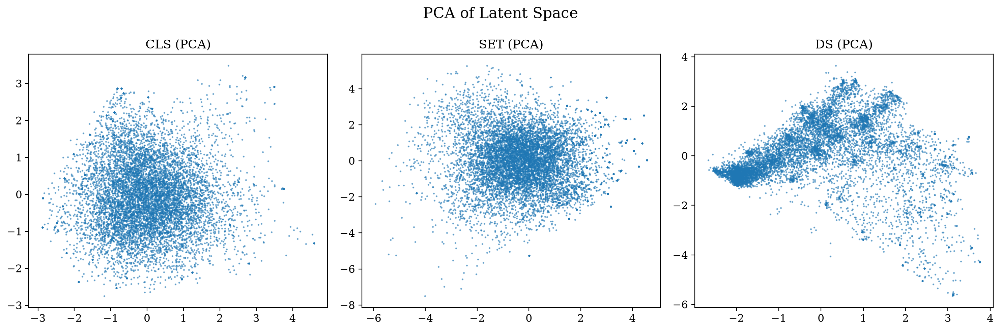

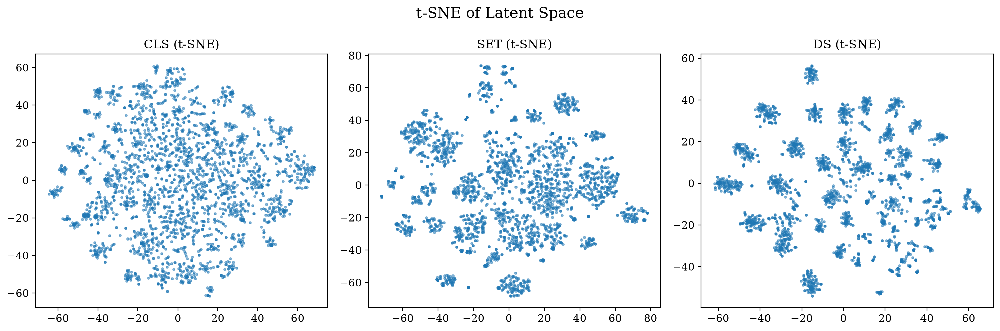

In [39]:
test_ds = PolymerStreamDataset(
    ffp=ffp_arr_64,
    auto=auto_arr_64,
    samples_per_epoch=10_000,
    seq_len=1000,
    seed=999,
    batch_size=64
)
test_ds.set_epoch(1)

test_loader = DataLoader(
    test_ds, 
    batch_size=64, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)
model_cls = load_pretrained_vae('CLS', './data/DL/models/CLS_VAE.pt', device)
model_set = load_pretrained_vae('SET', './data/DL/models/SET_VAE.pt', device)
model_ds  = load_pretrained_vae('DS',  './data/DL/models/DS_VAE.pt',  device)

@torch.no_grad()
def get_latent_stats(model, loader):
    model.eval()
    mus, lvs = [], []
    for ffp, auto in loader:
        ffp, auto = ffp.to(device), auto.to(device)
        mu, logvar = model.encode(ffp, auto)
        mus.append(mu.cpu().numpy())
        lvs.append(logvar.cpu().numpy())
    return np.concatenate(mus, 0), np.concatenate(lvs, 0)


def get_latent_mu(model, loader):
    mu, _ = get_latent_stats(model, loader)
    return mu


def analyze_kl(mu, logvar, threshold=0.01):
    kl_sample = -0.5 * (1.0 + logvar - mu**2 - np.exp(logvar))
    A = kl_sample.mean(axis=0)
    A_sorted = np.sort(A)[::-1]
    cum = np.cumsum(A_sorted) / max(A.sum(), 1e-12)
    return dict(
        A=A,
        threshold=threshold,
        active_units=int((A > threshold).sum()),
        total_kl=float(A.sum()),
        top1=float(A_sorted[0]),
        top5=float(A_sorted[:5].mean()),
        top10=float(A_sorted[:10].mean()),
        n_to_90=int(np.searchsorted(cum, 0.90) + 1),
        n_to_95=int(np.searchsorted(cum, 0.95) + 1),
        kl_per_sample=kl_sample,
    )
z_cls = get_latent_mu(model_cls, test_loader)
z_set = get_latent_mu(model_set, test_loader)
z_ds  = get_latent_mu(model_ds,  test_loader)
def plot_pca(z_dict, title="PCA of Latent Space"):
    pca = PCA(n_components=2)
    fig, axes = plt.subplots(1, len(z_dict), figsize=(5*len(z_dict), 5))
    if len(z_dict) == 1: axes = [axes]
    for ax, (name, z) in zip(axes, z_dict.items()):
        if z is None: continue
        z_2d = pca.fit_transform(z)
        ax.scatter(z_2d[:,0], z_2d[:,1], s=1, alpha=0.5)
        ax.set_title(f'{name} (PCA)')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
plot_pca({'CLS': z_cls, 'SET': z_set, 'DS': z_ds})
def plot_tsne(z_dict, title="t‑SNE of Latent Space", n_samples=3000):
    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    fig, axes = plt.subplots(1, len(z_dict), figsize=(5*len(z_dict), 5))
    if len(z_dict) == 1: axes = [axes]
    for ax, (name, z) in zip(axes, z_dict.items()):
        if z is None: continue
        idx = np.random.choice(len(z), min(n_samples, len(z)), replace=False)
        z_sub = z[idx]
        z_2d = tsne.fit_transform(z_sub)
        ax.scatter(z_2d[:,0], z_2d[:,1], s=5, alpha=0.5)
        ax.set_title(f'{name} (t‑SNE)')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
plot_tsne({'CLS': z_cls, 'SET': z_set, 'DS': z_ds})

#### small set for adhesive prediction

Generated 347 experimental samples in memory, labels shape: (347,)

Cross‑validated R² on experimental set:


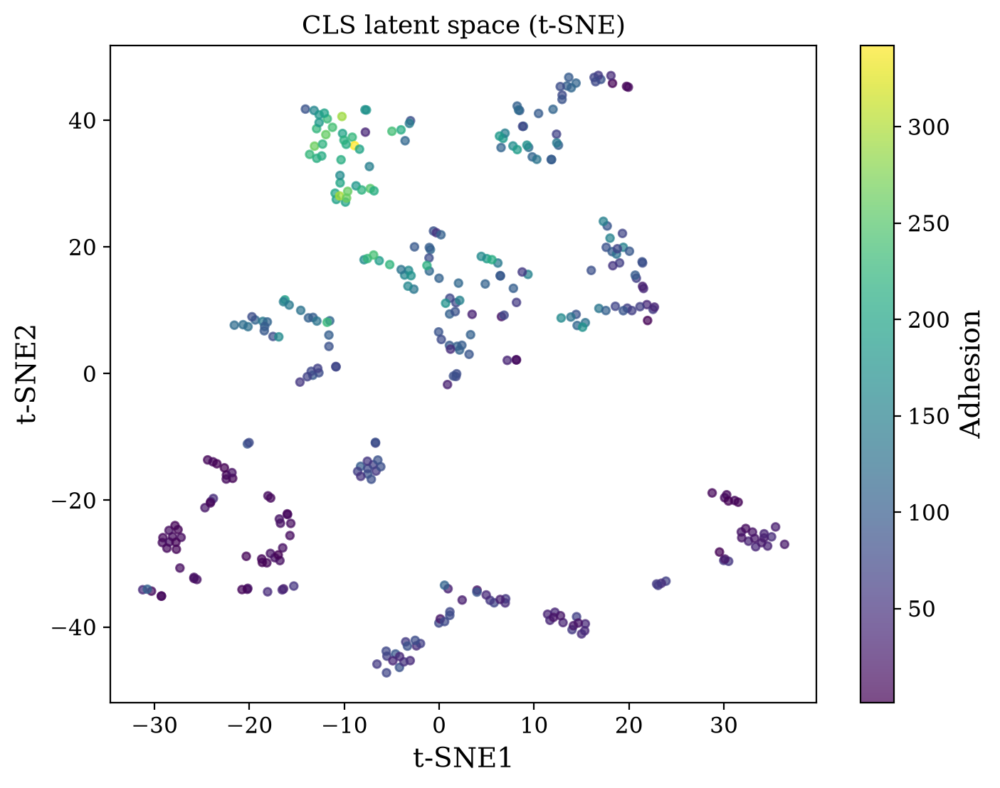

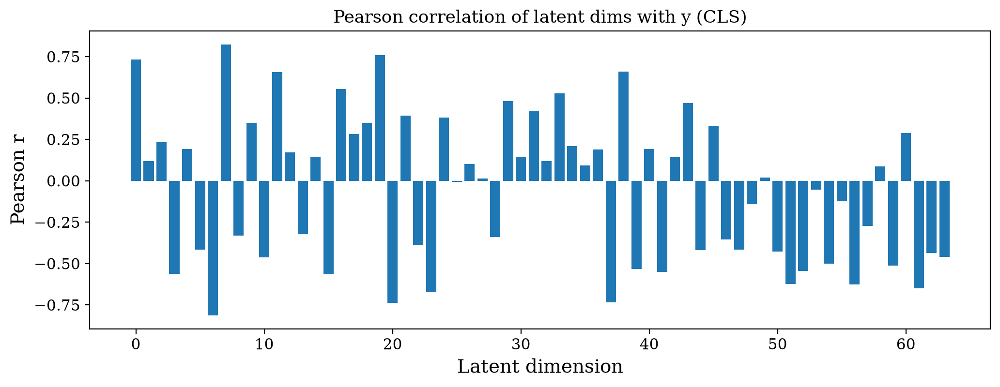

CLS Linear R²: 0.411 ± 0.213
CLS Ridge R²: 0.243 ± 0.472


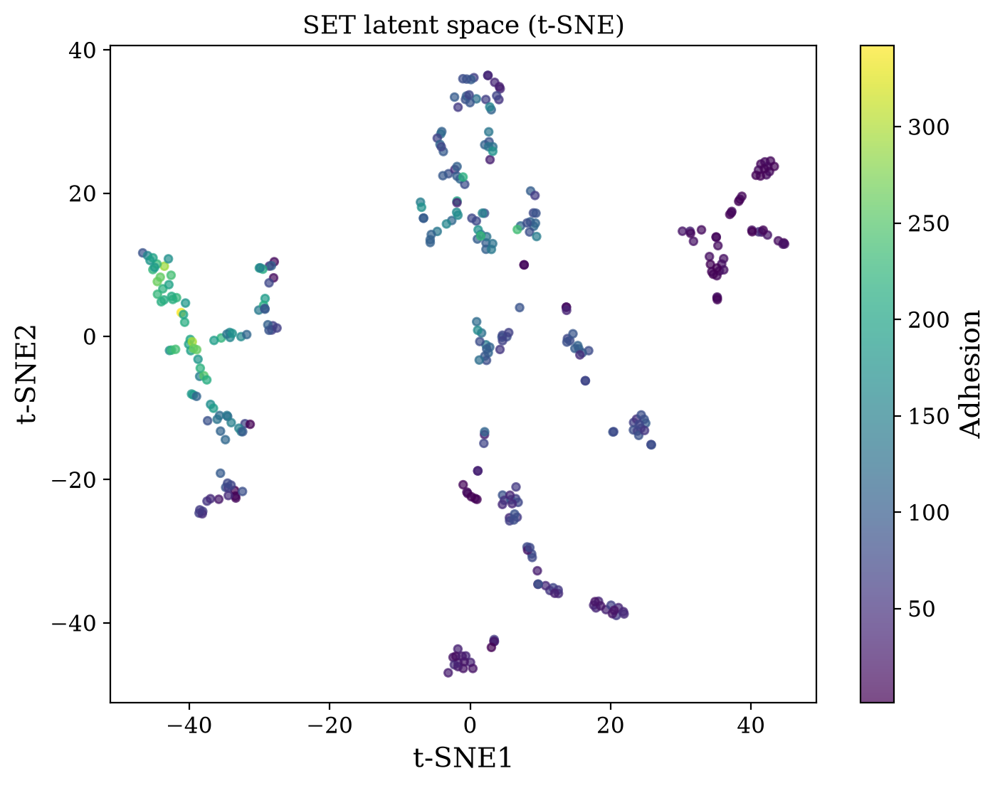

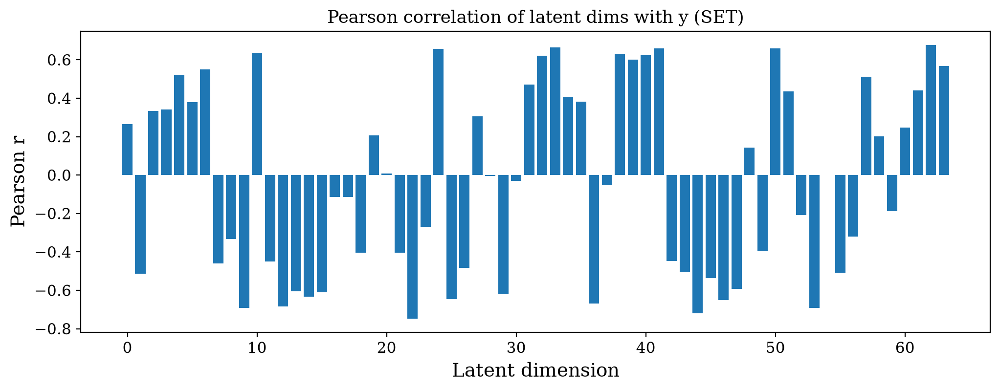

SET Linear R²: -0.396 ± 1.256
SET Ridge R²: 0.419 ± 0.279


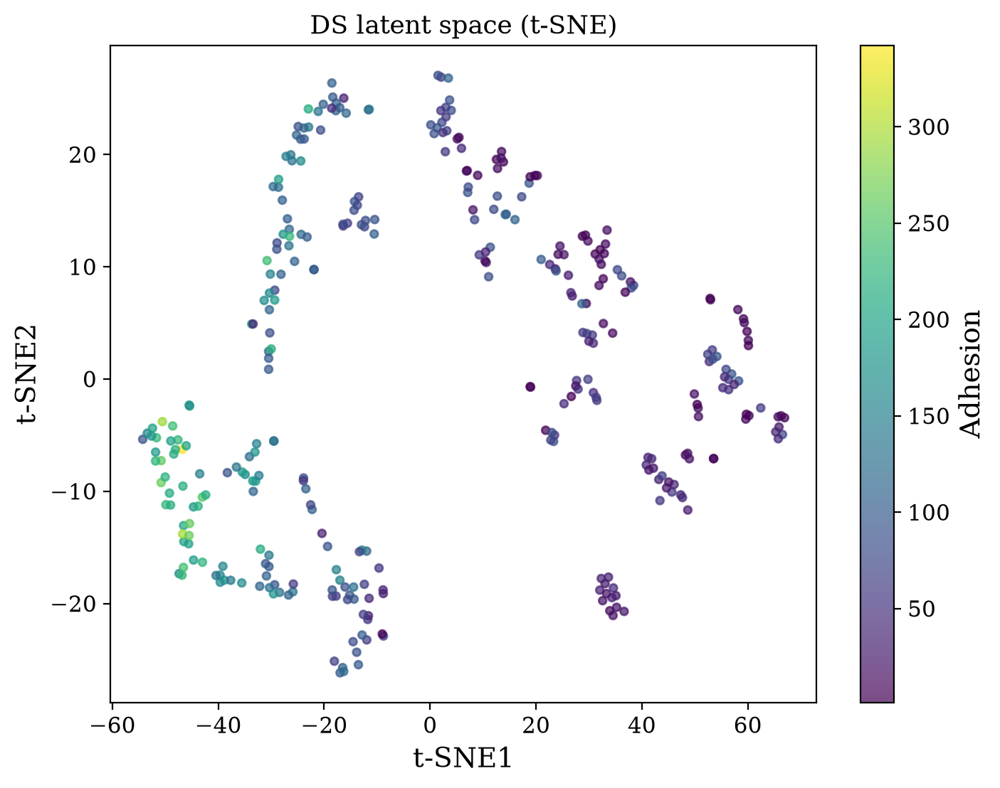

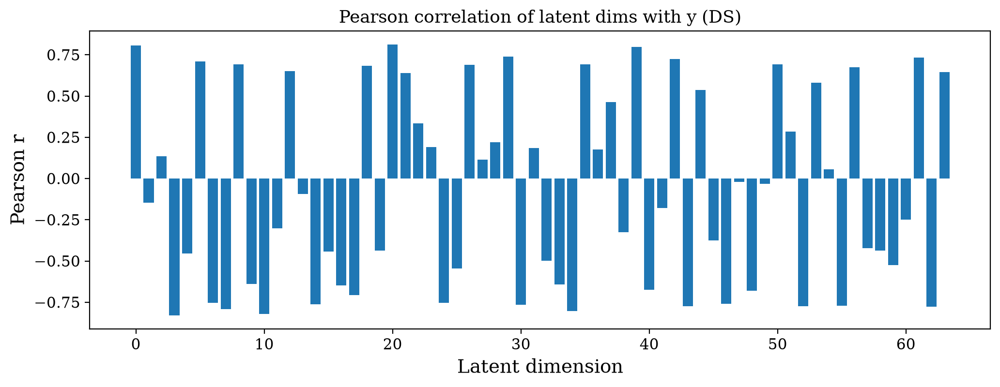

DS Linear R²: -96.242 ± 189.092
DS Ridge R²: 0.361 ± 0.286


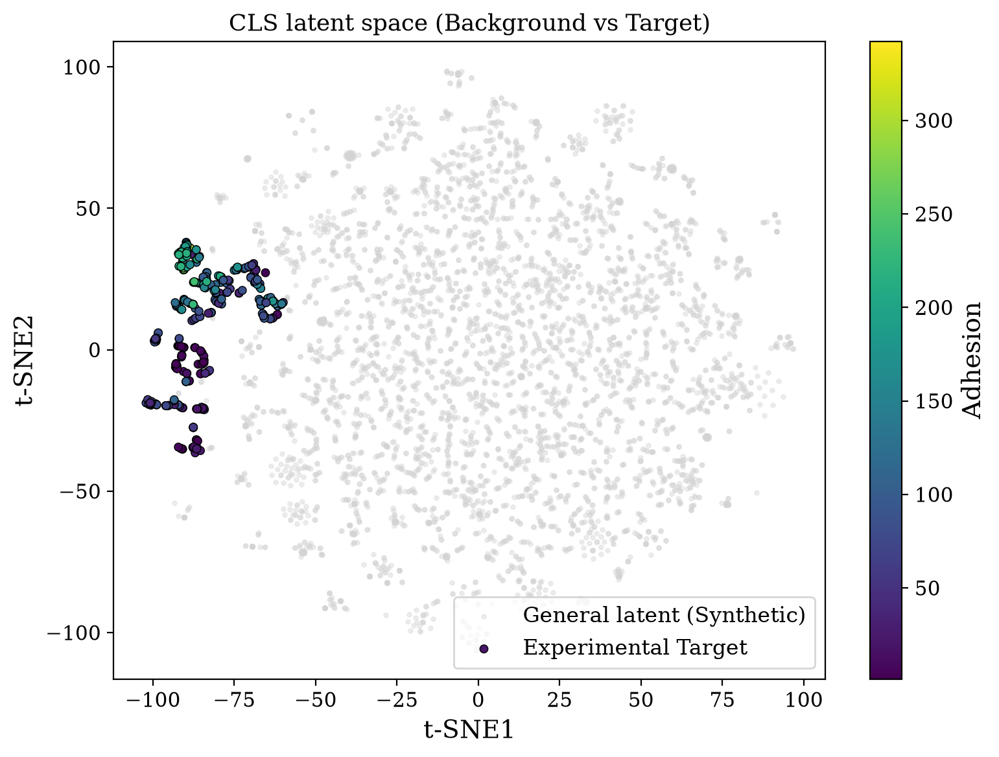

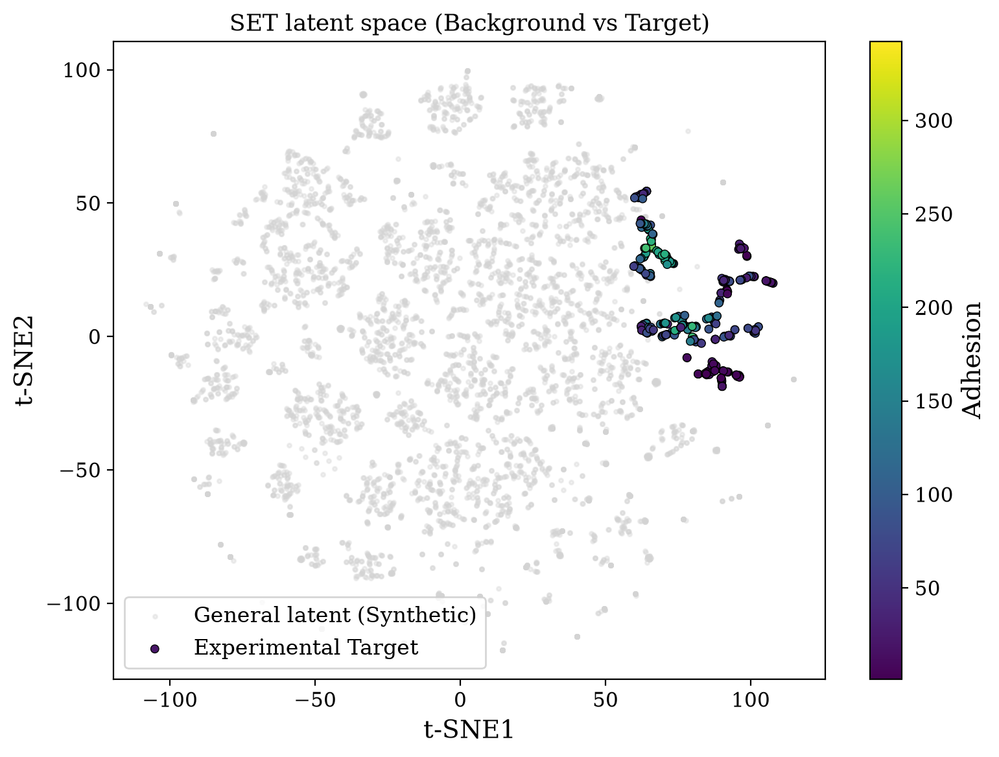

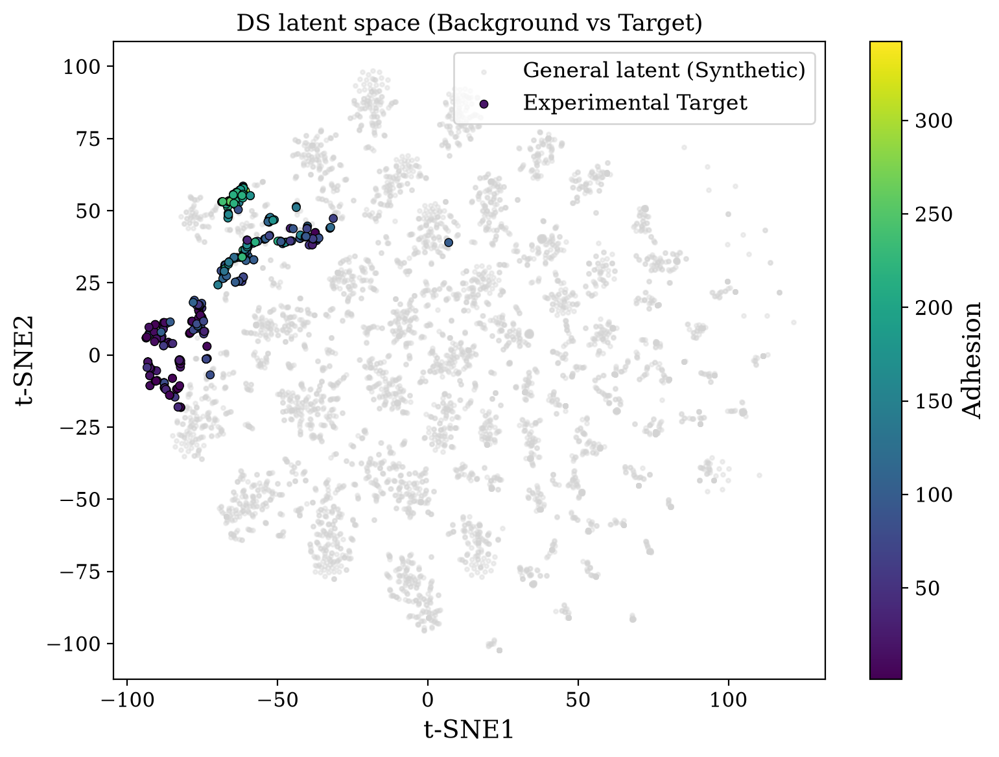

In [42]:
small_ffp, small_auto = [], []
for fracs in valid_comps:
    exact = fracs * 1000
    counts = np.floor(exact).astype(np.int32)
    diff = 1000 - counts.sum()
    if diff > 0:
        rem_indices = np.argsort(exact % 1)[::-1]
        counts[rem_indices[:diff]] += 1
    global_chain = np.repeat(mon_indices, counts)
    np.random.shuffle(global_chain)
    
    small_ffp.append(ffp_arr_64[global_chain])
    small_auto.append(auto_arr_64[global_chain])

small_ffp = torch.tensor(np.array(small_ffp), dtype=torch.float32)
small_auto = torch.tensor(np.array(small_auto), dtype=torch.float32)
labels = adhesion.ravel() if adhesion.ndim > 1 else adhesion

small_loader = DataLoader(
    TensorDataset(small_ffp, small_auto), 
    batch_size=32, shuffle=False, num_workers=0
)
print(f"Generated {len(labels)} experimental samples in memory, labels shape: {labels.shape}")

models = {
    'CLS': load_pretrained_vae('CLS', './data/DL/models/CLS_VAE.pt', device),
    'SET': load_pretrained_vae('SET', './data/DL/models/SET_VAE.pt', device),
    'DS':  load_pretrained_vae('DS',  './data/DL/models/DS_VAE.pt',  device)
}

def get_latent_mu(model, loader):
    latents = []
    model.eval()
    with torch.no_grad():
        for ffp, auto in loader:
            mu, _ = model.encode(ffp.to(device), auto.to(device))
            latents.append(mu.cpu().numpy())
    return np.concatenate(latents)

z_dict = {name: get_latent_mu(model, small_loader) for name, model in models.items()}

def plot_tsne_colored(z, lab, title, perplexity=10):
    safe_perp = min(perplexity, len(z) - 1)
    z_2d = TSNE(n_components=2, perplexity=safe_perp, random_state=42).fit_transform(z)
    
    plt.figure(figsize=(8, 6))
    sc = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=lab, cmap='viridis', s=15, alpha=0.7)
    plt.colorbar(sc, label='Adhesion')
    plt.title(title); plt.xlabel('t-SNE1'); plt.ylabel('t-SNE2')
    plt.show()

def plot_correlations(z, lab, model_name):
    corrs = [pearsonr(z[:, i], lab)[0] for i in range(z.shape[1])]
    plt.figure(figsize=(12, 4))
    plt.bar(range(len(corrs)), corrs)
    plt.title(f'Pearson correlation of latent dims with y ({model_name})')
    plt.xlabel('Latent dimension'); plt.ylabel('Pearson r')
    plt.show()

def evaluate_regression(z, lab, model_name):
    for reg, reg_name in [(LinearRegression(), 'Linear'), (Ridge(alpha=1.0), 'Ridge')]:
        scores = cross_val_score(reg, z, lab, cv=5, scoring='r2')
        print(f"{model_name} {reg_name} R²: {scores.mean():.3f} ± {scores.std():.3f}")

print("\nCross‑validated R² on experimental set:")
for name, z in z_dict.items():
    plot_tsne_colored(z, labels, f'{name} latent space (t-SNE)')
    plot_correlations(z, labels, name)
    evaluate_regression(z, labels, name)

bg_by_model = {'CLS': z_cls, 'SET': z_set, 'DS': z_ds}

for name, z in z_dict.items():
    bg = bg_by_model[name]
    idx = np.random.choice(len(bg), min(5000, len(bg)), replace=False)
    bg = bg[idx]
    z2 = TSNE(n_components=2, perplexity=10, random_state=42).fit_transform(np.vstack([bg, z]))
    b, f = z2[:len(bg)], z2[len(bg):]

    plt.figure(figsize=(8, 6))
    plt.scatter(b[:, 0], b[:, 1], c='lightgrey', s=5, alpha=0.35, label='General latent (Synthetic)')
    plt.scatter(f[:, 0], f[:, 1], c=labels, cmap='viridis', s=20, alpha=1.0,
                edgecolors='black', linewidth=0.5, label='Experimental Target')
    plt.colorbar(label='Adhesion')
    plt.title(f'{name} latent space (Background vs Target)')
    plt.xlabel('t-SNE1'); plt.ylabel('t-SNE2')
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()


=== Table S6: active units and per-dimension KL ===
             Active_syn  SumKL_syn  Top1_syn  Top5_syn  Top10_syn  Dims90_syn Active_exp  SumKL_exp  Dims90_exp
Architecture                                                                                                   
CLS               19/64     16.717     2.493     1.661      1.315          13      17/64     10.645          10
SET               64/64     43.238     2.699     2.406      2.190          26      50/64     26.437          20
DS                64/64     87.793     1.935     1.859      1.815          54      64/64     67.847          52


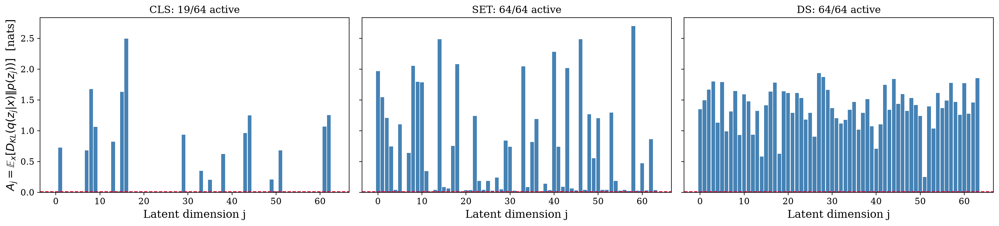

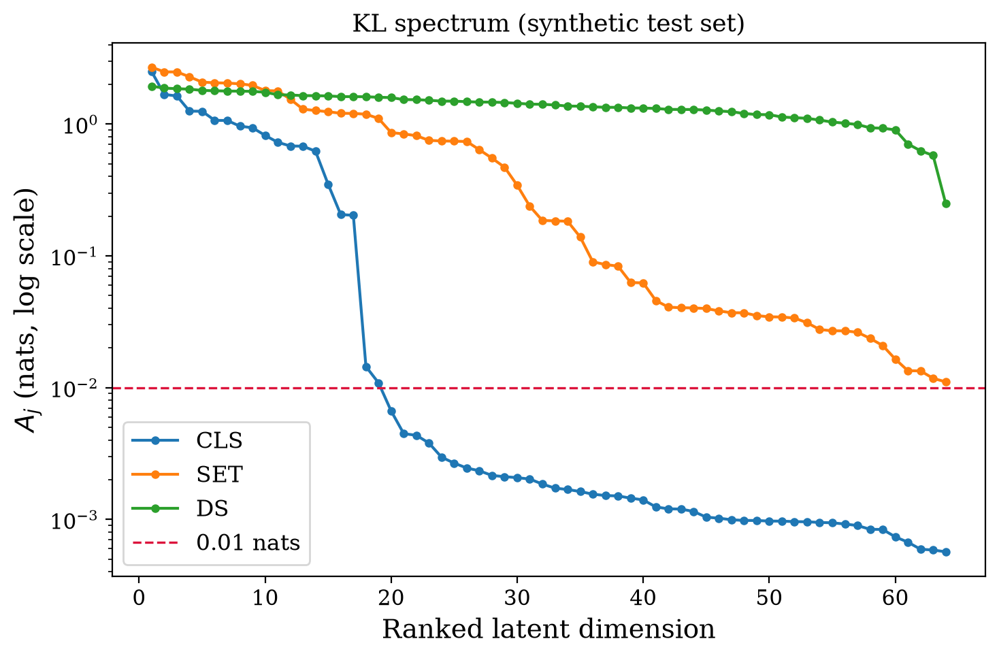

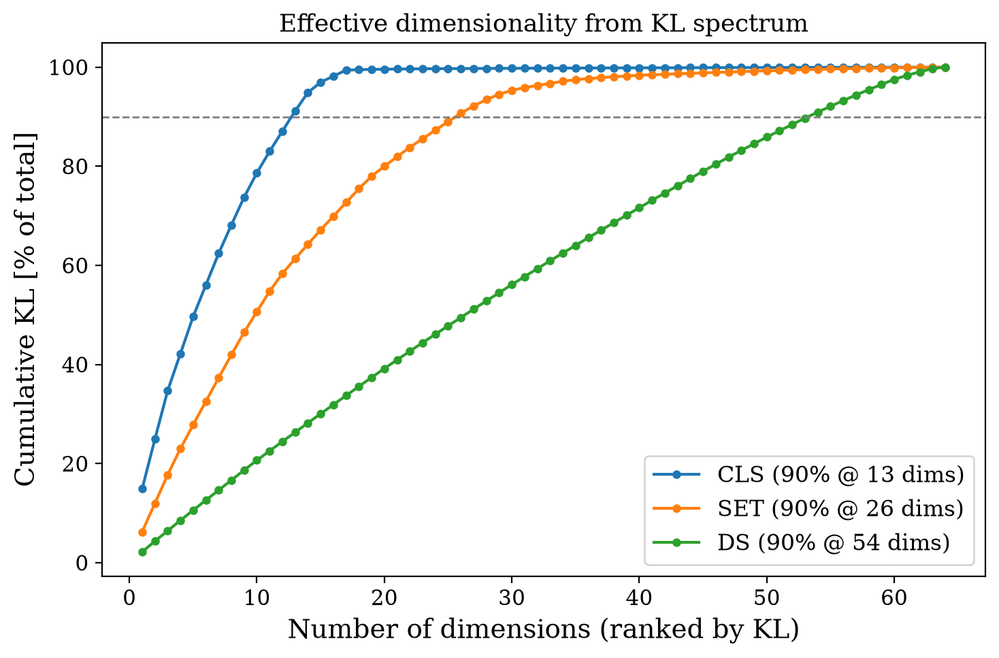

In [43]:
kl_syn, kl_exp = {}, {}

for name, model in models.items():
    mu_s, lv_s = get_latent_stats(model, test_loader)
    kl_syn[name] = analyze_kl(mu_s, lv_s, threshold=0.01)
    mu_e, lv_e = get_latent_stats(model, small_loader)
    kl_exp[name] = analyze_kl(mu_e, lv_e, threshold=0.01)

rows = []
for name in ['CLS', 'SET', 'DS']:
    r, e = kl_syn[name], kl_exp[name]
    rows.append(dict(
        Architecture=name,
        Active_syn=f"{r['active_units']}/64",
        SumKL_syn=round(r['total_kl'], 3),
        Top1_syn=round(r['top1'], 3),
        Top5_syn=round(r['top5'], 3),
        Top10_syn=round(r['top10'], 3),
        Dims90_syn=r['n_to_90'],
        Active_exp=f"{e['active_units']}/64",
        SumKL_exp=round(e['total_kl'], 3),
        Dims90_exp=e['n_to_90'],
    ))
df_kl = pd.DataFrame(rows).set_index('Architecture')
print("\n=== Table S6: active units and per-dimension KL ===")
print(df_kl.to_string())
df_kl.to_csv('./data/DL/kl_summary_table_S6.csv')

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, name in zip(axes, ['CLS', 'SET', 'DS']):
    A = kl_syn[name]['A']
    colors = np.where(A > 0.01, 'steelblue', 'lightgrey')
    ax.bar(np.arange(len(A)), A, color=colors, width=0.85)
    ax.axhline(0.01, color='crimson', ls='--', lw=1.2)
    ax.set_title(f"{name}: {kl_syn[name]['active_units']}/64 active")
    ax.set_xlabel('Latent dimension j')
    if name == 'CLS':
        ax.set_ylabel(r'$A_j = \mathbb{E}_x[D_{KL}(q(z_j|x)\|p(z_j))]$  [nats]')
fig.tight_layout()
fig.savefig('./data/DL/fig_kl_per_dim.pdf', dpi=300, bbox_inches='tight')
fig.savefig('./data/DL/fig_kl_per_dim.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5))
for name in ['CLS', 'SET', 'DS']:
    A_sorted = np.sort(kl_syn[name]['A'])[::-1]
    ax.plot(np.arange(1, len(A_sorted) + 1), A_sorted,
            marker='o', ms=3.5, label=name)
ax.axhline(0.01, color='crimson', ls='--', lw=1.2, label='0.01 nats')
ax.set_yscale('log')
ax.set_xlabel('Ranked latent dimension')
ax.set_ylabel(r'$A_j$ (nats, log scale)')
ax.set_title('KL spectrum (synthetic test set)')
ax.legend()
fig.tight_layout()
fig.savefig('./data/DL/fig_kl_spectrum.pdf', dpi=300, bbox_inches='tight')
fig.savefig('./data/DL/fig_kl_spectrum.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5))
for name in ['CLS', 'SET', 'DS']:
    A_sorted = np.sort(kl_syn[name]['A'])[::-1]
    cum = np.cumsum(A_sorted) / A_sorted.sum() * 100
    ax.plot(np.arange(1, len(cum) + 1), cum, marker='o', ms=3.5,
            label=f"{name} (90% @ {kl_syn[name]['n_to_90']} dims)")
ax.axhline(90, color='grey', ls='--', lw=1)
ax.set_xlabel('Number of dimensions (ranked by KL)')
ax.set_ylabel('Cumulative KL [% of total]')
ax.set_title('Effective dimensionality from KL spectrum')
ax.legend()
fig.tight_layout()
fig.savefig('./data/DL/fig_kl_cumulative.pdf', dpi=300, bbox_inches='tight')
fig.savefig('./data/DL/fig_kl_cumulative.png', dpi=300, bbox_inches='tight')

Common RBF sigma (pooled median heuristic) = 6.403

MMD² with common sigma:
  CLS: MMD²=0.1635  MMD²/σ²=0.0040
  SET: MMD²=0.2781  MMD²/σ²=0.0068
  DS: MMD²=0.1814  MMD²/σ²=0.0044

=== Table S7: latent geometry and OOD generalization ===
              N_syn  N_exp  Isotropy_syn  Isotropy_exp  MMD2_common_sigma  MMD2_over_sigma2  Maha_median  Maha_p95  Maha_max  L2latent_vs_L1comp_Pearson  L2latent_vs_L1comp_Spearman
Architecture                                                                                                                                                                         
CLS            9984    347        15.237        31.178             0.1635            0.0040        17.48     20.91     24.32                       0.898                        0.905
SET            9984    347        11.728        36.703             0.2781            0.0068        25.56     32.97     35.35                       0.609                        0.634
DS             9984    347        

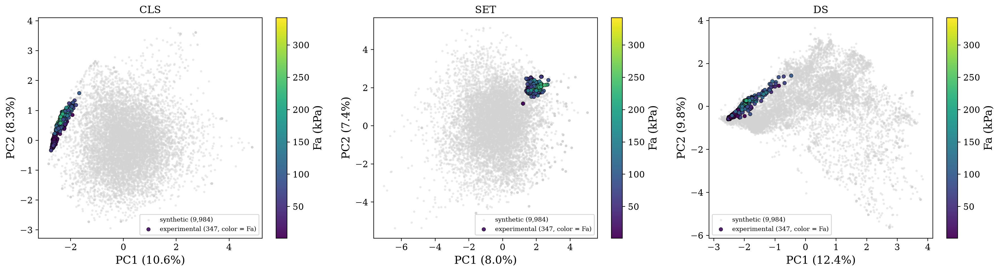

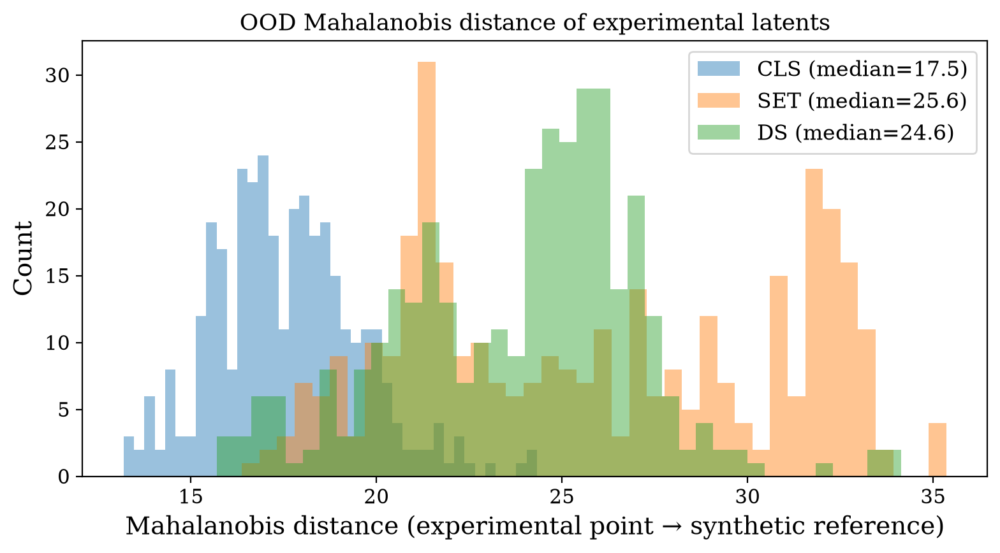

In [49]:
ARCHS      = ['CLS', 'SET', 'DS']
Z_syn      = {'CLS': z_cls, 'SET': z_set, 'DS': z_ds}
Z_exp      = {a: z_dict[a] for a in ARCHS}
C_exp      = np.asarray(valid_comps, dtype=np.float64)
MON_NAMES  = ['HEA', 'BA', 'CBEA', 'ATAC', 'PEA', 'AAm']
N_SYN      = len(Z_syn['CLS'])
N_EXP      = len(Z_exp['CLS'])

def isotropy(Z):
    Sigma      = np.cov(Z, rowvar=False)
    d          = np.sqrt(np.diag(Sigma).clip(min=1e-12))
    Sigma_norm = Sigma / np.outer(d, d)
    return float(np.linalg.norm(Sigma_norm - np.eye(len(d)), 'fro'))

iso_syn = {a: isotropy(Z_syn[a]) for a in ARCHS}
iso_exp = {a: isotropy(Z_exp[a]) for a in ARCHS}

def mmd_rbf_common_sigma(X, Y, sigma, max_n=5000, seed=0):
    rng = np.random.default_rng(seed)
    Xf  = X if len(X) <= max_n else X[rng.choice(len(X), max_n, replace=False)]
    Yf  = Y if len(Y) <= max_n else Y[rng.choice(len(Y), max_n, replace=False)]
    K = lambda A, B: np.exp(-cdist(A, B, 'sqeuclidean') / (2 * sigma**2))
    return float(K(Xf, Xf).mean() + K(Yf, Yf).mean() - 2 * K(Xf, Yf).mean())

_pool = np.vstack([Z_syn[a] for a in ARCHS] + [Z_exp[a] for a in ARCHS])
_sq   = cdist(_pool, _pool, 'sqeuclidean')
SIGMA_COMMON = float(np.sqrt(np.median(_sq[_sq > 0])))
mmd_val = {a: mmd_rbf_common_sigma(Z_syn[a], Z_exp[a], SIGMA_COMMON) for a in ARCHS}
mmd_sigma_common = SIGMA_COMMON
print(f"Common RBF sigma (pooled median heuristic) = {SIGMA_COMMON:.3f}")
mmd_norm = {a: mmd_val[a] / SIGMA_COMMON**2 for a in ARCHS}
print("\nMMD² with common sigma:")
for a in ARCHS:
    print(f"  {a}: MMD²={mmd_val[a]:.4f}  MMD²/σ²={mmd_norm[a]:.4f}")
    
def mahalanobis_per_sample(X_ref, X_test):
    cov = LedoitWolf().fit(X_ref)
    return cov.mahalanobis(X_test)

maha = {a: mahalanobis_per_sample(Z_syn[a], Z_exp[a]) for a in ARCHS}

def ridge_per_monomer(Z, C, n_splits=5, seed=42):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    alphas = np.logspace(-3, 3, 13)
    r2 = []
    for j in range(C.shape[1]):
        pred = cross_val_predict(RidgeCV(alphas=alphas), Z, C[:, j], cv=kf)
        r2.append(float(r2_score(C[:, j], pred)))
    return np.array(r2)

ridge_r2 = {a: ridge_per_monomer(Z_exp[a], C_exp) for a in ARCHS}

def latent_vs_comp(Z, C, n_pairs=10_000, seed=0):
    rng = np.random.default_rng(seed)
    n   = len(Z)
    i   = rng.integers(0, n, n_pairs)
    j   = rng.integers(0, n, n_pairs)
    m   = i != j
    i, j = i[m], j[m]
    d_lat  = np.linalg.norm(Z[i] - Z[j], axis=1)
    d_comp = np.abs(C[i] - C[j]).sum(axis=1)                          # L1
    return float(pearsonr(d_lat, d_comp)[0]), float(spearmanr(d_lat, d_comp)[0])

lat_vs_comp = {a: latent_vs_comp(Z_exp[a], C_exp) for a in ARCHS}

def linear_cka(X, Y):
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    num = np.linalg.norm(X.T @ Y, 'fro') ** 2
    den = np.linalg.norm(X.T @ X, 'fro') * np.linalg.norm(Y.T @ Y, 'fro')
    return float(num / max(den, 1e-12))

cka_syn = pd.DataFrame(np.eye(3), index=ARCHS, columns=ARCHS)
cka_exp = pd.DataFrame(np.eye(3), index=ARCHS, columns=ARCHS)
for i, a in enumerate(ARCHS):
    for j, b in enumerate(ARCHS):
        if i < j:
            cka_syn.loc[a, b] = cka_syn.loc[b, a] = linear_cka(Z_syn[a], Z_syn[b])
            cka_exp.loc[a, b] = cka_exp.loc[b, a] = linear_cka(Z_exp[a], Z_exp[b])

rows_s7 = []
for a in ARCHS:
    rows_s7.append(dict(
        Architecture=a,
        Isotropy_syn=round(iso_syn[a], 3),
        Isotropy_exp=round(iso_exp[a], 3),
        MMD2_common_sigma=round(mmd_val[a], 4),
        MMD2_over_sigma2=round(mmd_norm[a], 4),
        Maha_median=round(float(np.median(maha[a])), 2),
        Maha_p95=round(float(np.percentile(maha[a], 95)), 2),
        Maha_max=round(float(maha[a].max()), 2),
        L2latent_vs_L1comp_Pearson=round(lat_vs_comp[a][0], 3),
        L2latent_vs_L1comp_Spearman=round(lat_vs_comp[a][1], 3),
    ))
df_s7 = pd.DataFrame(rows_s7).set_index('Architecture')
df_s7.insert(0, 'N_syn', N_SYN)
df_s7.insert(1, 'N_exp', N_EXP)
print("\n=== Table S7: latent geometry and OOD generalization ===")
print(df_s7.to_string())
df_s7.to_csv('./data/DL/table_S7_generalization.csv')

print(f"\n=== CKA between architectures (synthetic, N={N_SYN:,}) ===")
print(cka_syn.round(3).to_string())
print(f"\n=== CKA between architectures (experimental, N={N_EXP}) ===")
print(cka_exp.round(3).to_string())
cka_syn.to_csv('./data/DL/table_S7_cka_synthetic.csv')
cka_exp.to_csv('./data/DL/table_S7_cka_experimental.csv')

df_s8 = pd.DataFrame(ridge_r2, index=MON_NAMES).T
df_s8.columns = [f"R2_{m}" for m in df_s8.columns]
df_s8['R2_mean'] = df_s8.mean(axis=1)
print("\n=== Table S8: ridge(latent → composition), per-monomer CV R² ===")
print(df_s8.round(3).to_string())
df_s8.to_csv('./data/DL/table_S8_ridge_permonomer.csv')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, a in zip(axes, ARCHS):
    Zc = np.vstack([Z_syn[a], Z_exp[a]])
    p  = PCA(n_components=2, random_state=42).fit(Zc)
    S  = p.transform(Z_syn[a])
    E  = p.transform(Z_exp[a])
    ax.scatter(S[:, 0], S[:, 1], c='lightgrey', s=4, alpha=0.35,
               label=f'synthetic ({len(S):,})')
    sc = ax.scatter(E[:, 0], E[:, 1], c=adhesion, cmap='viridis',
                    s=22, alpha=0.95, edgecolors='black', linewidths=0.4,
                    label=f'experimental ({len(E)}, color = Fa)')
    ax.set_title(a)
    ax.set_xlabel(f"PC1 ({p.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({p.explained_variance_ratio_[1]*100:.1f}%)")
    ax.legend(fontsize=8, loc='best')
    plt.colorbar(sc, ax=ax, label='Fa (kPa)')
fig.tight_layout()
fig.savefig('./data/DL/fig_S_pca_overlay.pdf', dpi=600, bbox_inches='tight')
fig.savefig('./data/DL/fig_S_pca_overlay.png', dpi=600, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for a in ARCHS:
    ax.hist(maha[a], bins=40, alpha=0.45,
            label=f"{a} (median={np.median(maha[a]):.1f})")
ax.set_xlabel('Mahalanobis distance (experimental point → synthetic reference)')
ax.set_ylabel('Count')
ax.set_title('OOD Mahalanobis distance of experimental latents')
ax.legend()
fig.tight_layout()
fig.savefig('./data/DL/fig_S_mahalanobis.pdf', dpi=600, bbox_inches='tight')
plt.show()

## Full all MLP pipeline

In [38]:
def read_sheet(path, cols):
    return pd.read_excel(path, sheet_name=0, header=None, skiprows=1) \
             .iloc[:, :len(cols)].set_axis(cols, axis=1)

def parse_std(s):
    s = str(s).replace(',', '.').strip()
    m = re.search(r'([\d.]+)\s*±\s*([\d.]+)', s)
    if m: return float(m.group(1)), float(m.group(2))
    try: return float(s), float(s) * 0.07
    except: return np.nan, np.nan

def load_and_prepare(data_dir='data'):
    c6 = ['Round','ML','Rank','No.','ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm','Fa_max','Fa_ave','d','Q']
    c5 = ['No.','ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm','Fa_max','Fa_ave','d','Q','G','Tanδ','k']
    cc = ['ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm']

    df = pd.concat([
        read_sheet(f'{data_dir}/41586_2025_9269_MOESM5_ESM.xlsx', c5),
        read_sheet(f'{data_dir}/41586_2025_9269_MOESM6_ESM.xlsx', c6)
    ], ignore_index=True)[cc + ['Fa_max','Fa_ave','Q','G','Tanδ','k']]

    for c in cc + ['Fa_max']:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')

    df = df.dropna(subset=cc)
    df = df[~df[cc].round(4).duplicated()].reset_index(drop=True)
    df[cc] = df[cc].div(df[cc].sum(axis=1), axis=0)

    p = df['Fa_ave'].apply(parse_std)
    df['Fa_mean'] = p.apply(lambda x: x[0]); df['Fa_std'] = p.apply(lambda x: x[1])
    mask = df['Fa_mean'].isna() & df['Fa_max'].notna()
    df.loc[mask,'Fa_mean'] = df.loc[mask,'Fa_max']
    df.loc[mask,'Fa_std']  = df.loc[mask,'Fa_mean']*0.05
    df = df[df['Fa_mean'] > 0].copy()

    q = df['Q'].apply(parse_std)
    df['Q_mean'] = q.apply(lambda x: x[0])

    for c in ['G','Tanδ','k']:
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.').str.extract(r'([\d.]+)')[0], errors='coerce')

    return df.reset_index(drop=True), cc

def split_data(df, val_size=0.15, test_size=0.10, seed=42, n_bins=10):
    bins = pd.qcut(df['Fa_mean'], q=n_bins, labels=False, duplicates='drop')
    tr, te = train_test_split(df, test_size=test_size, stratify=bins, random_state=seed)
    tr, va = train_test_split(tr, test_size=val_size / (1 - test_size),
                              stratify=bins.loc[tr.index], random_state=seed)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

def get_latent_for_composition(fracs, vae, mon_indices, features, device):
    exact = fracs * 1000
    counts = np.floor(exact).astype(np.int32)
    counts[np.argsort(exact % 1)[::-1][:1000 - counts.sum()]] += 1
    chain = np.repeat(mon_indices, counts)
    np.random.shuffle(chain)
    with torch.no_grad():
        auto = torch.from_numpy(features['autocorr'][0][chain]).float().unsqueeze(0).to(device)
        cffp = torch.from_numpy(features['cffp_256'][0][chain]).float().unsqueeze(0).to(device)
        mu, _ = vae.encode(cffp, auto)
    return mu.squeeze(0).cpu().numpy()

def augment_and_create_tensors(df, latent_col, seed=42, n_aug=30):
    rng = np.random.default_rng(seed)
    z = np.repeat(np.stack(df[latent_col].values), n_aug, axis=0)
    m = np.repeat(df['Fa_mean'].values, n_aug)
    s = np.repeat(np.maximum(df['Fa_std'].values, 0.01), n_aug)
    y = np.clip(rng.normal(m, s), 0, None).astype(np.float32)
    return z.astype(np.float32), y

def generate_pairs(df, latent_col='latent', target_col='Fa_mean'):
    pairs = []
    n = len(df)
    for i in range(n):
        for j in range(i+1, n):
            fa_i = df.iloc[i][target_col]
            fa_j = df.iloc[j][target_col]
            pairs.append({
                'z_A': df.iloc[i][latent_col],
                'z_B': df.iloc[j][latent_col],
                'label': 1.0 if fa_i > fa_j else 0.0
            })
    return pd.DataFrame(pairs)

### Models

In [39]:
class MLP(nn.Module):
    def __init__(self, latent_dim=64, hidden_dim=256, dropout=0.15):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Mish(),
            nn.Dropout(dropout)
        )
        self.res_block1 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Mish(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim)
        )
        self.act1 = nn.Mish()
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 4), # 256 -> 64
            nn.LayerNorm(hidden_dim // 4),
            nn.Mish(),
            nn.Dropout(dropout / 2),
            nn.Linear(hidden_dim // 4, 1)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='linear')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        with torch.no_grad():
            self.head[-1].bias.data.fill_(100.0)

    def forward(self, z):
        if z.ndim == 3: 
            z = z.mean(dim=1)
        h = self.input_layer(z)
        h = self.act1(h + self.res_block1(h))
        return self.head(h).squeeze(-1)

In [40]:
class MLPNLL(nn.Module):
    def __init__(self, input_dim=64, hidden_dim=256, dropout=0.25):
        super().__init__()
        self.input_block = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Mish(),
            nn.Dropout(dropout)
        )
        self.res_block = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Mish(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim)
        )
        self.res_act = nn.Mish()
        self.mu_branch = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.Mish(),
            nn.Dropout(dropout / 2),
            nn.Linear(hidden_dim // 2, 1)
        )
        
        self.var_branch = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.Mish(),
            nn.Dropout(dropout / 2),
            nn.Linear(hidden_dim // 2, 1)
        )
        
        self._init_weights()
        
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='linear')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        with torch.no_grad():
            self.mu_branch[-1].bias.data.fill_(100.0)
            self.var_branch[-1].bias.data.fill_(np.log(100.0))
            
    def forward(self, z):
        h = self.input_block(z)
        h = self.res_act(h + self.res_block(h))        
        mu = self.mu_branch(h).squeeze(-1)
        log_var = self.var_branch(h).squeeze(-1)
        log_var = torch.clamp(log_var, min=-3.0, max=8.0)
        return mu, log_var

In [41]:
TARGETS = ['Fa_mean','Q_mean','G','Tanδ','k']
class MTMLP(nn.Module):
    def __init__(s, D=64, hidden=256, dropout=0.15):
        super().__init__()
        s.tower = nn.Sequential(
            nn.Linear(D,hidden), nn.LayerNorm(hidden), nn.Mish(), nn.Dropout(dropout),
            nn.Linear(hidden,hidden), nn.LayerNorm(hidden), nn.Mish(), nn.Dropout(dropout),
            nn.Linear(hidden,hidden//2), nn.LayerNorm(hidden//2), nn.Mish())
        s.heads = nn.ModuleList([nn.Linear(hidden//2, 1) for _ in TARGETS])
        s.log_sigma = nn.Parameter(torch.zeros(len(TARGETS)))
    def forward(s, z):
        h = s.tower(z)
        return torch.cat([head(h) for head in s.heads], -1)

In [42]:
class PSMLP(nn.Module):
    def __init__(self, D=64, hidden=128, dropout=0.2):
        super().__init__()
        self.tower = nn.Sequential(
            nn.Linear(D, hidden), nn.LayerNorm(hidden), nn.Mish(), nn.Dropout(dropout),
            nn.Linear(hidden, D), nn.LayerNorm(D),      nn.Mish(), nn.Dropout(dropout))
        self.head = nn.Sequential(
            nn.Linear(2 * D, hidden), nn.Mish(), nn.Dropout(dropout),
            nn.Linear(hidden, 32), nn.Mish(), nn.Linear(32, 1))

    def _phi(s, hA, hB):
        d = hA - hB
        z = torch.cat([d, torch.abs(d)], dim=-1)
        return s.head(z).squeeze(dim=-1).view(-1)

    def forward(s, xA, xB):
        hA, hB = s.tower(xA), s.tower(xB)
        return s._phi(hA, hB)    

In [43]:
class APSMLP(nn.Module):
    def __init__(self, D=64, hidden=128, dropout=0.2):
        super().__init__()
        self.tower = nn.Sequential(
            nn.Linear(D, hidden), nn.LayerNorm(hidden), nn.Mish(), nn.Dropout(dropout),
            nn.Linear(hidden, D), nn.LayerNorm(D),      nn.Mish(), nn.Dropout(dropout))
        self.head = nn.Sequential(
            nn.Linear(2 * D, hidden), nn.Mish(), nn.Dropout(dropout),
            nn.Linear(hidden, 32), nn.Mish(), nn.Linear(32, 1))

    def _phi(s, hA, hB):
        d = hA - hB
        z = torch.cat([d, torch.abs(d)], dim=-1)
        return s.head(z).squeeze(dim=-1).view(-1)

    def forward(s, xA, xB):
        hA, hB = s.tower(xA), s.tower(xB)
        return 0.5 * (s._phi(hA, hB) - s._phi(hB, hA))

In [44]:
class ResBlock(nn.Module):
    def __init__(s, h, dp):
        super().__init__()
        s.f = nn.Sequential(
            nn.Linear(h, h), nn.LayerNorm(h), nn.Mish(), nn.Dropout(dp),
            nn.Linear(h, h), nn.LayerNorm(h))
    def forward(s, x): return x + s.f(x)

class DSMLP(nn.Module):
    def __init__(s, D=64, hidden=256, n_blocks=3, dropout=0.1):
        super().__init__()
        s.stem = nn.Sequential(
            nn.Linear(D, hidden), nn.LayerNorm(hidden), nn.Mish(), nn.Dropout(dropout))
        s.blocks = nn.ModuleList([ResBlock(hidden, dropout) for _ in range(n_blocks)])
        s.head = nn.Sequential(
            nn.Linear(hidden, hidden // 2), nn.LayerNorm(hidden // 2), nn.Mish(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1))
        s._init()

    def _init(s):
        for m in s.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='linear')
                if m.bias is not None: nn.init.zeros_(m.bias)

    def score(s, x):
        h = s.stem(x)
        for b in s.blocks: h = b(h)
        return s.head(h).squeeze(dim=-1).view(-1)

    def forward(s, a, b):
        return s.score(a) - s.score(b)

### train 

In [45]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mon_cols = ['ΦHEA','ΦBA','ΦCBEA','ΦATAC','ΦPEA','ΦAAm']
vae_configs = {
    'CLS': './data/DL/models/CLS_VAE.pt',
    'SET': './data/DL/models/SET_VAE.pt',
    'DS':  './data/DL/models/DS_VAE.pt',
}

df_unique, comp_cols = load_and_prepare()
print(f": {len(df_unique)}")

col_to_mon = {'ΦHEA': 'HEA', 'ΦBA': 'BA', 'ΦCBEA': 'CBEA', 'ΦATAC': 'ATAC', 'ΦPEA': 'PEA', 'ΦAAm': 'AAm'}
name_to_idx = {name: i for i, name in enumerate(val_df.index)}
mon_indices = np.array([name_to_idx[col_to_mon[col]] for col in mon_cols], dtype=np.int32)
features_source = {
    'autocorr': (autocorr_2d_arrays, np.float32),
    'cffp_256': (cffp_arrays3, np.uint16)
}

# mon_indices features_source 
for name, ckpt in vae_configs.items():
    vae = load_pretrained_vae(name, ckpt, device)
    vae.eval()
    latents = []
    for _, row in df_unique.iterrows():
        fracs = row[comp_cols].values.astype(np.float64)
        fracs = fracs / fracs.sum()  
        z = get_latent_for_composition(fracs, vae, mon_indices, features_source, device)
        latents.append(z)
    df_unique[f'latent_{name}'] = latents
    del vae
    torch.cuda.empty_cache()

: 347


In [46]:
df_unique

,ΦHEA,ΦBA,ΦCBEA,ΦATAC,ΦPEA,ΦAAm,Fa_max,Fa_ave,Q,G,Tanδ,k,Fa_mean,Fa_std,Q_mean,latent_CLS,latent_SET,latent_DS
0,0.518703,0.199302,0.094768,0.187226,0.000000,0.0,22.36,19.89±1.76,2.52±0.09,5.599,0.0105,NaN,19.89,1.76,2.52,"[0.020263236, 0.048983227, -0.027838768, 0.020...","[-0.4628757, 1.5568049, -0.33505833, -0.082964...","[-0.54193795, 0.3036069, 0.08646231, -0.045761..."
1,0.421787,0.406214,0.171999,0.000000,0.000000,0.0,12.57,11.06±1.94,0.24±0.00,19.219,0.1573,0.116592,11.06,1.94,0.24,"[0.044939112, -0.16772483, -0.014564825, -0.01...","[-0.4473518, 1.3148257, -0.4154814, -0.084978,...","[-0.4310109, 0.300677, 0.20096204, -0.12514761..."
2,0.536864,0.108375,0.184067,0.170693,0.000000,0.0,10.93,10.13±0.79,2.91±0.15,4.555,NaN,0.014942,10.13,0.79,2.91,"[0.025795486, 0.064618126, -0.023865389, 0.030...","[-0.42345357, 1.5265163, -0.36958712, -0.05511...","[-0.5916213, 0.28751257, 0.13995764, 0.0049285..."
3,0.216356,0.199474,0.088142,0.174303,0.321725,0.0,126.82,109.57±12.43,1.19±0.06,7.078,0.1480,0.130907,109.57,12.43,1.19,"[0.04477204, 0.27787688, -0.025000712, 0.01489...","[-0.107868716, 1.1489226, -0.3513933, 0.177362...","[-0.38774896, 0.22340399, 0.22411303, -0.17111..."
4,0.119821,0.410078,0.191813,0.187167,0.091121,0.0,109.27,94.89±10.59,1.10±0.03,7.136,0.1024,0.095809,94.89,10.59,1.10,"[0.051472183, -0.05081575, -0.02593032, 0.0019...","[-0.39012444, 1.4083424, -0.3937551, 0.0024575...","[-0.14225112, 0.16644423, 0.18156801, -0.27962..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,0.000000,0.640000,0.000000,0.070000,0.290000,0.0,235.47,219.32±19.58,0.38±0.03,NaN,NaN,NaN,219.32,19.58,0.38,"[0.07511522, 0.015001874, -0.01119121, -0.0311...","[-0.106912926, 0.66550744, -0.10369334, 0.1424...","[0.15037169, 0.2095639, 0.23292367, -0.6355592..."
343,0.000000,0.600000,0.000000,0.070000,0.330000,0.0,225.39,198.48±21.60,0.50±0.02,NaN,NaN,NaN,198.48,21.60,0.50,"[0.073967844, 0.052984428, -0.012421077, -0.02...","[-0.07654688, 0.66001135, -0.10130023, 0.16792...","[0.14027782, 0.19747299, 0.24943003, -0.636571..."
344,0.000000,0.606000,0.000000,0.081000,0.313000,0.0,229.75,216.26±12.41,0.58±0.02,NaN,NaN,NaN,216.26,12.41,0.58,"[0.07259323, 0.058124732, -0.0116672795, -0.02...","[-0.13021116, 0.67533505, -0.064332075, 0.1610...","[0.14285089, 0.19777557, 0.23415989, -0.630145..."
345,0.000000,0.666000,0.000000,0.081000,0.253000,0.0,232.07,215.24±17.31,0.64±0.00,NaN,NaN,NaN,215.24,17.31,0.64,"[0.06940679, -0.012056727, -0.014076123, -0.03...","[-0.18141371, 0.69381845, -0.06950752, 0.11997...","[0.15694822, 0.21526508, 0.21141681, -0.628624..."


In [47]:
df_train, df_val, df_test = split_data(df_unique)

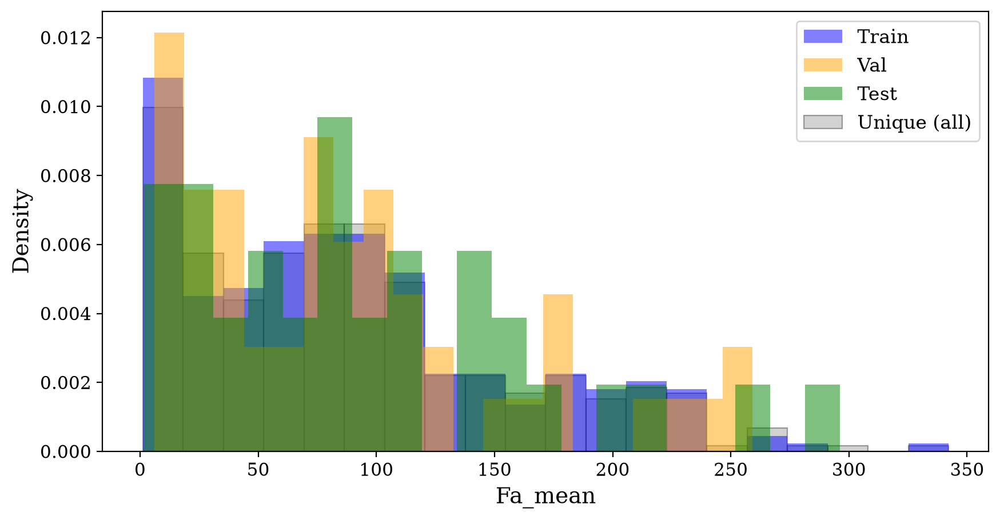

In [48]:
plt.figure(figsize=(10, 5))
plt.hist(df_train['Fa_mean'], bins=20, alpha=0.5, label='Train', color='blue',   density=True)
plt.hist(df_val['Fa_mean'],   bins=20, alpha=0.5, label='Val',   color='orange', density=True)
plt.hist(df_test['Fa_mean'],  bins=20, alpha=0.5, label='Test',  color='green',  density=True)
plt.hist(df_unique['Fa_mean'], bins=20, alpha=0.35, label='Unique (all)', color='grey', density=True, edgecolor='black', linewidth=0.8, zorder=0)
plt.xlabel('Fa_mean')
plt.ylabel('Density')
plt.legend()
plt.show()

In [49]:
def _reg_loaders(z_tr, y_tr, z_va, y_va, bs=64):
    tr = TensorDataset(torch.from_numpy(z_tr), torch.from_numpy(y_tr))
    va = TensorDataset(torch.from_numpy(z_va), torch.from_numpy(y_va))
    return (DataLoader(tr, batch_size=bs,  shuffle=True,  num_workers=4, pin_memory=True, drop_last=True),
            DataLoader(va, batch_size=256, shuffle=False, num_workers=4, pin_memory=True))

def _mt_loaders(df_tr, df_va, lc, bs=64):
    def prep(df):
        z = np.stack(df[lc].values).astype(np.float32)
        Y = df[TARGETS].values.astype(np.float32)
        M = (~np.isnan(Y)).astype(np.float32)
        return z, np.nan_to_num(Y), M
    def ds(df):
        z,Y,M = prep(df)
        return TensorDataset(torch.from_numpy(z), torch.from_numpy(Y), torch.from_numpy(M))
    return (DataLoader(ds(df_tr), batch_size=bs, shuffle=True,  drop_last=True, num_workers=4, pin_memory=True),
            DataLoader(ds(df_va), batch_size=256, shuffle=False, num_workers=4, pin_memory=True))

def _pw_loaders(df_tr, df_va, latent_col, bs=64):
    def ds(df):
        p = generate_pairs(df, latent_col)
        return TensorDataset(
            torch.tensor(np.stack(p['z_A'].values), dtype=torch.float32),
            torch.tensor(np.stack(p['z_B'].values), dtype=torch.float32),
            torch.tensor(p['label'].values,          dtype=torch.float32))
    return (DataLoader(ds(df_tr), batch_size=bs,  shuffle=True,  num_workers=4, pin_memory=True, drop_last=True),
            DataLoader(ds(df_va), batch_size=256, shuffle=False, num_workers=4, pin_memory=True))

def cycle_loss(model, Z, n=1024):
    i = torch.randint(0, len(Z), (3,n), device=Z.device)
    A,B,C = Z[i[0]], Z[i[1]], Z[i[2]]
    ab,bc,ca = model(A,B), model(B,C), model(C,A)
    return (torch.relu(ab)*torch.relu(bc)*torch.relu(ca)).mean()

def trans_loss(model, Z, y, n=1024, m=0.1):
    i = torch.randint(0, len(Z), (3,n), device=Z.device)
    mask = (y[i[0]]>y[i[1]]) & (y[i[1]]>y[i[2]])
    if mask.sum() < 16: return torch.tensor(0., device=Z.device)
    A,B,C = Z[i[0]][mask], Z[i[1]][mask], Z[i[2]][mask]
    return torch.relu(m - model(A,C) + model(A,B)).mean()

def _pw(m, b, d, Z=None, y=None, β=0.3, γ=0.1):
    a, c, t = (x.to(d) for x in b)
    l = nn.functional.binary_cross_entropy_with_logits(m(a,c), t)
    if Z is not None:
        l = l + β*cycle_loss(m, Z) + γ*trans_loss(m, Z, y)
    return l, t, torch.sigmoid(m(a,c))

def _reg_eval(model, ckpt, z, y, task="nll", bs=256):
    dl = DataLoader(TensorDataset(torch.from_numpy(z), torch.from_numpy(y)),
                    batch_size=bs, shuffle=False, num_workers=4, pin_memory=True)
    p, t = predict(model, dl, device, task=task, ckpt=ckpt)
    return float(np.mean((p - t) ** 2))

def _mt(m, b, d):
    z, y, mk = (t.to(d) for t in b)
    p = m(z)
    mse = ((p - y)**2 * mk).sum(0) / mk.sum(0).clamp(min=1)
    l = (torch.exp(-m.log_sigma) * mse + m.log_sigma).mean()
    return l, y[:, :2], p[:, :2]   

def _mtm_eval(model, ckpt, df, lc, D):
    m = MTMLP(D).to(device)
    m.load_state_dict(torch.load(ckpt, map_location=device)["model"]); m.eval()
    Z = torch.from_numpy(np.stack(df[lc].values).astype(np.float32)).to(device)
    with torch.inference_mode(): P = m(Z).cpu().numpy()
    Y = df[TARGETS].values.astype(np.float32)
    j = TARGETS.index('Fa_mean')
    mk = ~np.isnan(Y[:, j])
    return float(np.mean((P[mk,j]-Y[mk,j])**2))

def _pw_eval(model, ckpt, df, latent_col, bs=256):
    p = generate_pairs(df, latent_col)
    dl = DataLoader(
        TensorDataset(
            torch.tensor(np.stack(p['z_A'].values), dtype=torch.float32),
            torch.tensor(np.stack(p['z_B'].values), dtype=torch.float32),
            torch.tensor(p['label'].values,          dtype=torch.float32)),
        batch_size=bs, shuffle=False, num_workers=4, pin_memory=True)
    preds, targets = predict(model, dl, device, task="bce", ckpt=ckpt)
    return float(roc_auc_score(targets, preds))


def _apw_eval(model, ckpt, df, latent_col, bs=256):
    p = generate_pairs(df, latent_col)
    dl = DataLoader(
        TensorDataset(
            torch.tensor(np.stack(p['z_A'].values), dtype=torch.float32),
            torch.tensor(np.stack(p['z_B'].values), dtype=torch.float32),
            torch.tensor(p['label'].values,          dtype=torch.float32)),
        batch_size=bs, shuffle=False, num_workers=4, pin_memory=True)
    preds, targets = predict(model, dl, device, task="pairwise", ckpt=ckpt)
    return float(roc_auc_score(targets, preds))
@dataclass
class Cfg:
    name: str; task: str="nll"; epochs: int=200; lr: float=1e-3; wd: float=1e-5; patience: int=25
    min_delta: float=1e-5; clip: float=1.0; accum: int=1; amp: bool=True; compile: bool=False
    ema: float=0.999; warmup: float=0.05; sched: str="plateau"; hist_every: int=5
    ckpt: Path=Path("./data/DL/models"); logs: Path=Path("runs"); seed: int=42
def _nll(m,b,d): z,y=(t.to(d) for t in b); mu,lv=m(z); return nn.functional.gaussian_nll_loss(mu,y,lv.exp()),y,mu
def _mse(m,b,d): z,y=(t.to(d) for t in b); p=m(z); return nn.functional.mse_loss(p,y),y,p
def _bce(m,b,d): a,c,y=(t.to(d) for t in b); l=m(a,c); return nn.functional.binary_cross_entropy_with_logits(l,y),y,torch.sigmoid(l)
R=lambda t,p:{"mse":float(np.mean((p-t)**2))}
C=lambda t,p:{"auc":roc_auc_score(t,p),"acc":accuracy_score(t,(p>.5).astype(np.float32))}
S   = {"nll":_nll, "mse":_mse, "pairwise":_pw, "mt":_mt, "bce":_bce}
M   = {"nll":R, "mse":R, "pairwise":C, "bce":C,
       "mt": lambda t, p: {
           "mse_Fa":  float(np.mean((p[:,0]-t[:,0])**2)),
           "mse_Q":   float(np.mean((p[:,1]-t[:,1])**2)),
           "mse_FaQ": float(np.mean((p[:,0]-t[:,0])**2) + np.mean((p[:,1]-t[:,1])**2)),
       }}
MON = {"nll":("val_mse",-1), "mse":("val_mse",-1),
       "pairwise":("val_auc",1), "mt":("val_mse_FaQ",-1), "bce":("val_auc",1)}
def train(model, tr, va, cfg: Cfg, device):
    random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
    torch.cuda.manual_seed_all(cfg.seed); torch.backends.cudnn.benchmark=True; cfg.ckpt.mkdir(parents=True,exist_ok=True)
    cb=cfg.ckpt/f"{cfg.name}_best.pt"
    if cfg.compile and hasattr(torch,"compile"): model.forward = torch.compile(model.forward, mode="max-autotune")
    opt=AdamW(model.parameters(),lr=cfg.lr,weight_decay=cfg.wd); spe=len(tr)
    mkey,sign=MON[cfg.task]; best=-sign*math.inf
    if cfg.sched=="cosine":
        T,W_=max(1,cfg.epochs*spe),max(1,int(cfg.warmup*cfg.epochs*spe))
        sch=LambdaLR(opt,lambda s:s/W_ if s<W_ else .5*(1+math.cos(math.pi*(s-W_)/max(1,T-W_)))); sm="step"
    else:
        sch=ReduceLROnPlateau(opt,mode=("min" if sign<0 else "max"), 
                              factor=.5,patience=15,min_lr=1e-6); sm="epoch"
    amp=cfg.amp and device.type=="cuda"; sc=GradScaler("cuda",enabled=amp); ac=lambda:autocast("cuda",enabled=amp)
    ema={k:v.detach().clone() for k,v in model.state_dict().items() if v.dtype.is_floating_point} if cfg.ema else None
    bad=0
    W=SummaryWriter(str(cfg.logs/f"{cfg.name}_{cfg.task}")); W.add_text("cfg",json.dumps({k:str(v) for k,v in cfg.__dict__.items()}))
    step,mfn=S[cfg.task],M[cfg.task]; itr,iva=1.0 / (len(tr) * tr.batch_size),1/len(va.dataset)
    pbar=tqdm(range(1,cfg.epochs+1),desc=f"[{cfg.name}]",unit="ep",dynamic_ncols=False,leave=True)
    for ep in range(1,cfg.epochs+1):
        model.train(); run=torch.zeros((),device=device); opt.zero_grad(set_to_none=True)
        for i,b in enumerate(tr):
            with ac(): l,y,_=step(model,b,device)
            loss=l/cfg.accum
            sc.scale(loss).backward()
            run+=l.detach()*y.size(0) 
            is_last = (i + 1 == len(tr))
            if (i+1)%cfg.accum==0 or is_last:
                sc.unscale_(opt)
                if torch.isfinite(torch.nn.utils.clip_grad_norm_(model.parameters(),cfg.clip)): sc.step(opt)
                sc.update(); opt.zero_grad(set_to_none=True)
                if sm=="step": sch.step()
                if ema is not None:
                    for k,v in model.state_dict().items():
                        if k in ema: ema[k].mul_(cfg.ema).add_(v.detach(),alpha=1-cfg.ema)
        trl=(run*itr).item()
        bak={k:v.detach().clone() for k,v in model.state_dict().items()} if ema else None
        if ema: model.load_state_dict({**model.state_dict(),**ema},strict=False)
        model.eval(); run=torch.zeros((),device=device); ps,ts=[],[]
        with torch.inference_mode(),ac():
            for b in va:
                l,y,p=step(model,b,device); run+=l.detach()*y.size(0)
                ps.append(p.float().cpu()); ts.append(y.cpu())
        val=(run*iva).item(); mt={f"val_{k}":v for k,v in mfn(torch.cat(ts).numpy(),torch.cat(ps).numpy()).items()}
        if ema: model.load_state_dict(bak)
        if sm=="epoch": sch.step(mt.get(mkey,val))
        lr=opt.param_groups[0]["lr"]
        post={"tr":f"{trl:.4f}","va":f"{val:.4f}","lr":f"{lr:.1e}","bad":f"{bad}/{cfg.patience}"}
        post.update({k[4:]:f"{v:.4f}" for k,v in mt.items()})
        pbar.set_postfix(post,refresh=False)
        W.add_scalars("Loss",{"train":trl,"val":val},ep); W.add_scalar("LR",lr,ep); W.add_scalar("Loss/gap",trl-val,ep)
        for k,v in mt.items(): W.add_scalar(f"Metrics/{k[4:]}",v,ep)
        if "val_mse" in mt: W.add_scalar("Metrics/rmse",math.sqrt(mt["val_mse"]),ep)
        if cfg.hist_every and (ep%cfg.hist_every==0 or ep==1):
            for n,p in model.named_parameters():
                W.add_histogram(f"W/{n}",p.data,ep)
                if p.grad is not None: W.add_histogram(f"G/{n}",p.grad.detach(),ep)
        mv=mt.get(mkey,val)
        if sign*(mv-best)>cfg.min_delta:
            best,bad=mv,0
            torch.save({"model":model.state_dict(),"ema":ema,"epoch":ep,"best":best,"monitor":mkey,"cfg":cfg.__dict__},cb)
        else: bad+=1
        W.add_scalars("EarlyStop",{"bad":bad,"best":best},ep)
        if bad>=cfg.patience: pbar.set_description(f"[{cfg.name}] stop@{ep} best {mkey}={best:.5f}");break
    pbar.close(); W.close(); return best

@torch.inference_mode()
def predict(model, loader, device, task="nll", ckpt=None):
    if ckpt and Path(ckpt).exists():
        c=torch.load(ckpt,map_location=device); model.load_state_dict(c["model"])
        if c.get("ema"): model.load_state_dict({**model.state_dict(),**c["ema"]},strict=False)
    model.eval().to(device); fn=S[task]; ps,ts=[],[]
    for b in loader:
        _,y,p=fn(model,b,device); ps.append(p.float().cpu()); ts.append(y.cpu())
    return torch.cat(ps).numpy(),torch.cat(ts).numpy()

In [50]:
VAES   = ['CLS', 'SET', 'DS']
COMMON = dict(epochs=10000, lr=1e-4, wd=1e-5, patience=40)
N_AUG  = 30
rows   = []

In [46]:
for vae in VAES:
    lc = f'latent_{vae}'
    print(f"\n{'='*60}\nVAE = {vae}  ({lc})\n{'='*60}")

    z_tr_aug, y_tr_aug = augment_and_create_tensors(df_train, lc, seed=42, n_aug=N_AUG)
    z_va_aug, y_va_aug = augment_and_create_tensors(df_val,   lc, seed=42, n_aug=N_AUG)

    z_tr = np.stack(df_train[lc].values).astype(np.float32); y_tr = df_train['Fa_mean'].values.astype(np.float32)
    z_va = np.stack(df_val[lc].values).astype(np.float32);   y_va = df_val['Fa_mean'].values.astype(np.float32)
    z_te = np.stack(df_test[lc].values).astype(np.float32);  y_te = df_test['Fa_mean'].values.astype(np.float32)
    D = z_tr.shape[1]

    tr_l, va_l = _reg_loaders(z_tr_aug, y_tr_aug, z_va_aug, y_va_aug)
    train(MLPNLL(D).to(device), tr_l, va_l,
                 Cfg(name=f"MLPNLL_{vae}", task="nll", **COMMON), device)
    ck = f"./data/DL/models/MLPNLL_{vae}_best.pt"; m = MLPNLL(D).to(device)
    rows.append(dict(VAE=vae, Model='MLPNLL',
                     Train=_reg_eval(m, ck, z_tr_aug, y_tr_aug, task="nll"),
                     Val  =_reg_eval(m, ck, z_va_aug, y_va_aug, task="nll"),
                     Test =_reg_eval(m, ck, z_te,     y_te,     task="nll")))

    tr_l, va_l = _reg_loaders(z_tr, y_tr, z_va, y_va)
    train(MLP(D).to(device), tr_l, va_l,
                 Cfg(name=f"MLP_{vae}", task="mse", **COMMON), device)
    ck = f"./data/DL/models/MLP_{vae}_best.pt"; m = MLP(D).to(device)
    rows.append(dict(VAE=vae, Model='MLP',
                     Train=_reg_eval(m, ck, z_tr, y_tr, task="mse"),
                     Val  =_reg_eval(m, ck, z_va, y_va, task="mse"),
                     Test =_reg_eval(m, ck, z_te, y_te, task="mse")))
    
    tr_l, va_l = _mt_loaders(df_train, df_val, lc)
    train(MTMLP(D).to(device), tr_l, va_l,
          Cfg(name=f"MTM_{vae}", task="mt", **COMMON), device)
    ck = f"./data/DL/models/MTM_{vae}_best.pt"
    m = MTMLP(D).to(device); m.load_state_dict(torch.load(ck, map_location=device)["model"]); m.eval()
    with torch.inference_mode():
        Zte = torch.from_numpy(np.stack(df_test[lc].values).astype(np.float32)).to(device)
        P = m(Zte).cpu().numpy()
    Yte = df_test[TARGETS].values.astype(np.float32)
    rows.append(dict(VAE=vae, Model='MTM',
         Train=_mtm_eval(m, ck, df_train, lc, D),
         Val  =_mtm_eval(m, ck, df_val,   lc, D),
         Test =_mtm_eval(m, ck, df_test,  lc, D)))
    for j, t in enumerate(TARGETS):
        mk = ~np.isnan(Yte[:, j])
        if mk.sum() < 5: continue
        rows.append(dict(VAE=vae, Model=f'MTM_{t}',
                         MSE=float(np.mean((P[mk,j]-Yte[mk,j])**2)),
                         Spearman=float(spearmanr(P[mk,j], Yte[mk,j]).statistic)))
    torch.cuda.empty_cache()

    tr_l, va_l = _pw_loaders(df_train, df_val, lc)
    train(PSMLP(D).to(device), tr_l, va_l,
          Cfg(name=f"PSMLP_{vae}", task="bce", sched="plateau", **COMMON), device)
    ck = f"./data/DL/models/PSMLP_{vae}_best.pt"
    m = PSMLP(D).to(device)
    rows.append(dict(VAE=vae, Model='PSMLP',
                     Train=_pw_eval(m, ck, df_train, lc),
                     Val  =_pw_eval(m, ck, df_val,   lc),
                     Test =_pw_eval(m, ck, df_test,  lc)))

    torch.cuda.empty_cache()

    
    tr_l, va_l = _pw_loaders(df_train, df_val, lc)
    Z_tr_t = torch.tensor(np.stack(df_train[lc].values), dtype=torch.float32, device=device)
    y_tr_t = torch.tensor(df_train['Fa_mean'].values,    dtype=torch.float32, device=device)
    S["pairwise"] = lambda m, b, d: _pw(m, b, d, Z=Z_tr_t, y=y_tr_t, β=0.3, γ=0.1)
    train(APSMLP().to(device), tr_l, va_l,
                 Cfg(name=f"APSMLP_{vae}", task="pairwise", sched="plateau", **COMMON), device)
    ck = f"./data/DL/models/APSMLP_{vae}_best.pt"; m = APSMLP().to(device)
    rows.append(dict(VAE=vae, Model='APSMLP',
                     Train=_apw_eval(m, ck, df_train, lc),
                     Val  =_apw_eval(m, ck, df_val,   lc),
                     Test =_apw_eval(m, ck, df_test,  lc)))

    torch.cuda.empty_cache()

    tr_l, va_l = _pw_loaders(df_train, df_val, lc)
    train(DSMLP(D).to(device), tr_l, va_l,
          Cfg(name=f"DSMLP_{vae}", task="bce", sched="plateau", **COMMON), device)
    ck = f"./data/DL/models/DSMLP_{vae}_best.pt"
    m = DSMLP(D).to(device)
    rows.append(dict(VAE=vae, Model='DSMLP',
                     Train=_pw_eval(m, ck, df_train, lc),
                     Val  =_pw_eval(m, ck, df_val,   lc),
                     Test =_pw_eval(m, ck, df_test,  lc)))

    torch.cuda.empty_cache()

df_res = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.4f}'.format)
d = df_res.drop_duplicates(['VAE','Model'], keep='first')
main = d[~d.Model.str.startswith('MTM_')]
mt   = d[d.Model.str.startswith('MTM_')]
print(main.pivot(index='VAE', columns='Model',
                 values=['Train','Val','Test']).to_string())
print(mt.pivot(index='VAE', columns='Model',
               values=['MSE','Spearman']).to_string())


VAE = CLS  (latent_CLS)


[MLPNLL_CLS] stop@196 best val_mse=954.71722:   0%| | 0/10000 [03:30<?, ?ep/s, 
[MLP_CLS] stop@2416 best val_mse=1289.92114:   0%| | 0/10000 [10:14<?, ?ep/s, t
[MTM_CLS] stop@3687 best val_mse_FaQ=1052.82617:   0%| | 0/10000 [16:35<?, ?ep/
[PSMLP_CLS] stop@47 best val_auc=0.94625:   0%| | 0/10000 [03:04<?, ?ep/s, tr=0
[APSMLP_CLS] stop@80 best val_auc=0.94987:   0%| | 0/10000 [24:30<?, ?ep/s, tr=
[DSMLP_CLS] stop@45 best val_auc=0.95606:   0%| | 0/10000 [06:04<?, ?ep/s, tr=0



VAE = SET  (latent_SET)


[MLPNLL_SET] stop@171 best val_mse=1010.85370:   0%| | 0/10000 [03:06<?, ?ep/s,
[MLP_SET] stop@3321 best val_mse=968.30902:   0%| | 0/10000 [15:04<?, ?ep/s, tr
[MTM_SET] stop@3437 best val_mse_FaQ=1208.40576:   0%| | 0/10000 [16:18<?, ?ep/
[PSMLP_SET] stop@52 best val_auc=0.93901:   0%| | 0/10000 [03:23<?, ?ep/s, tr=0
[APSMLP_SET] stop@52 best val_auc=0.93958:   0%| | 0/10000 [16:27<?, ?ep/s, tr=
[DSMLP_SET] stop@53 best val_auc=0.94412:   0%| | 0/10000 [07:35<?, ?ep/s, tr=0



VAE = DS  (latent_DS)


[MLPNLL_DS] stop@139 best val_mse=958.91504:   0%| | 0/10000 [02:49<?, ?ep/s, t
[MLP_DS] stop@2491 best val_mse=1188.46997:   0%| | 0/10000 [12:43<?, ?ep/s, tr
[MTM_DS] stop@2956 best val_mse_FaQ=1087.05823:   0%| | 0/10000 [15:45<?, ?ep/s
[PSMLP_DS] stop@58 best val_auc=0.95274:   0%| | 0/10000 [04:24<?, ?ep/s, tr=0.
[APSMLP_DS] stop@53 best val_auc=0.95763:   0%| | 0/10000 [16:31<?, ?ep/s, tr=0
[DSMLP_DS] stop@47 best val_auc=0.95462:   0%| | 0/10000 [06:53<?, ?ep/s, tr=0.


       Train                                             Val                                               Test                                            
Model APSMLP  DSMLP      MLP   MLPNLL      MTM  PSMLP APSMLP  DSMLP       MLP    MLPNLL       MTM  PSMLP APSMLP  DSMLP       MLP    MLPNLL       MTM  PSMLP
VAE                                                                                                                                                        
CLS   0.9812 0.9733 809.4245 488.2800 154.1926 0.9670 0.9499 0.9560 1290.6208  954.6517 1055.0557 0.9462 0.9813 0.9806 1324.1733  563.8239  839.2505 0.9782
DS    0.9705 0.9733 901.3220 687.2891 378.4912 0.9745 0.9577 0.9546 1189.8901  959.0218 1139.0757 0.9528 0.9694 0.9582 1456.1448 1013.8782 1116.3777 0.9413
SET   0.9716 0.9814 335.8666 491.8328 203.6507 0.9715 0.9396 0.9441  969.3034 1011.2194 1209.9315 0.9390 0.9688 0.9620 1196.3646  864.8531 1017.0569 0.9719
              MSE                                       Spearman

In [51]:
def load_model(path, cls, device=None, prefer_ema=True, **overrides):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ckpt, dict) and any(k in ckpt for k in ("model", "ema", "state_dict")):
        order = ("ema", "model", "state_dict") if prefer_ema else ("model", "ema", "state_dict")
        sd = next((ckpt[k] for k in order if ckpt.get(k) is not None), None)
        if sd is None:
            raise KeyError(f"no model/ema/state_dict in {path}")
        cfg = ckpt.get("cfg", {}) or {}
    else:
        sd, cfg = ckpt, {}
    for p in ("module.", "_orig_mod."):
        if all(k.startswith(p) for k in sd):
            sd = {k[len(p):]: v for k, v in sd.items()}
    params = set(inspect.signature(cls.__init__).parameters) - {"self"}
    kwargs = {k: v for k, v in cfg.items() if k in params}
    kwargs.update(overrides)
    model = cls(**kwargs)
    model.load_state_dict(sd, strict=True)
    if device is not None:
        model = model.to(device)
    return model.eval()

## Latent Optimizer

In [48]:
def get_real_latents(vae, h5_path='./data/DL/small_poly_datasets.h5', device=None, batch_size=64):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    vae.eval()
    
    all_mu = []
    with h5py.File(h5_path, 'r') as f:
        total = f['cffp_256'].shape[0]
        for start in range(0, total, batch_size):
            end = min(start + batch_size, total)
            ffp = torch.from_numpy(f['cffp_256'][start:end]).float().to(device)
            auto = torch.from_numpy(f['autocorr'][start:end]).float().to(device)
            with torch.no_grad():
                mu, _ = vae.encode(ffp, auto)
            all_mu.append(mu.cpu().numpy())
            del ffp, auto, mu
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    mu_all = np.concatenate(all_mu, axis=0)
    return mu_all.mean(axis=0), mu_all

In [49]:
KAPPA, ALPHA   = 1.64, 0.5
LR, LAMBDA0    = 0.03, 1e-4
N_STEPS, N_REST = 1000, 100
DELTA_TOL      = 0.05
SAVE = Path('./data/DL/opt_continuous'); SAVE.mkdir(parents=True, exist_ok=True)

def s_mlp(m, z):        return m(z).reshape(-1)
def s_nll(m, z, k=KAPPA):
    mu, lv = m(z);      return (mu + k * torch.exp(0.5 * lv)).reshape(-1)
def s_mtm(m, z):        return m(z)[:, 0].reshape(-1)
SCORE = {'MLP': s_mlp, 'MLPNLL': s_nll, 'MTMLP': s_mtm}

def reg_l2(z, zm, lam, m):
    return lam * (z - zm).pow(2).mean()

def reg_l2v(z, zm, lam, m):
    _, lv = m(z.unsqueeze(0))
    return lam * ((z - zm).pow(2).mean() + ALPHA * torch.exp(lv).mean())

REG = {'MLP': reg_l2, 'MTMLP': reg_l2, 'MLPNLL': reg_l2v}

class LatentOptimizer:
    def __init__(self, model, kind, emp_latents, seed=SEED):
        self.m = model.eval()
        for p in self.m.parameters(): p.requires_grad_(False)
        self.kind = kind
        self.L    = emp_latents
        self.zm   = emp_latents.mean(0)
        self.zs   = emp_latents.std(0)
        self.rng  = np.random.default_rng(seed)

    def _one(self):
        z0 = self.L[self.rng.integers(len(self.L))]
        eps = torch.randn_like(self.zs) * 0.05 * self.zs
        z   = (z0 + eps).clone().requires_grad_(True)
        opt = optim.Adam([z], lr=LR)
        tz, ts = [], []
        for s in range(N_STEPS):
            opt.zero_grad()
            sc  = SCORE[self.kind](self.m, z.unsqueeze(0)).squeeze()
            lam = LAMBDA0 * max(0.0, 1.0 - s / N_STEPS)
            (-sc + REG[self.kind](z, self.zm, lam, self.m)).backward()
            opt.step()
            tz.append(z.detach().cpu().numpy().copy())
            ts.append(float(sc.detach().cpu()))
        with torch.no_grad():
            sc = float(SCORE[self.kind](self.m, z.unsqueeze(0)).squeeze().cpu())
        return dict(z=z.detach().cpu().numpy(), s=sc,
                    traj_z=np.stack(tz), traj_s=np.array(ts))

    def run(self, n=N_REST, tag=''):
        runs = [self._one() for _ in tqdm(range(n), desc=tag, leave=False)]
        return max(runs, key=lambda r: r['s']), runs

@torch.no_grad()
def decode_to_phi(z_star, vae, mono_feat, tau=1.0):
    vae.eval()
    z = torch.as_tensor(z_star, dtype=torch.float32, device=device).reshape(1, -1)
    rf, ra = vae.decode(z)
    F  = torch.cat([rf, ra], -1).squeeze(0)                # (1000, 472)
    M  = mono_feat / (mono_feat.norm(dim=1, keepdim=True) + 1e-8)
    Fn = F         / (F.norm(dim=1, keepdim=True) + 1e-8)
    d  = (Fn.unsqueeze(1) - M.unsqueeze(0)).norm(dim=-1)    # (1000, 64)
    md = d.min(dim=1).values
    sa = torch.median(md).clamp(min=1e-4)
    P  = torch.softmax(-d.pow(2) / (tau * sa), dim=1)
    return P.mean(0).cpu().numpy(), float(md.mean().cpu())


def invert(z_star, s_star, vae, model, kind):
    phi, d_min = decode_to_phi(z_star, vae, mono_feat_tensor)
    z_p = get_latent_for_composition(phi, vae, mon_indices_64,
                                     features_source_64, device)
    with torch.no_grad():
        s_p = float(SCORE[kind](
            model,
            torch.as_tensor(z_p, dtype=torch.float32, device=device).reshape(1, -1),
        ).squeeze().cpu())
    return dict(phi=phi, z_p=z_p, s_p=s_p,
                delta=abs(s_p - s_star) / (abs(s_star) + 1e-8),
                d_min=d_min)

In [50]:
VAES = ['CLS', 'SET', 'DS']
REGS = {'MLP':    (MLP,    'MLP'), 'MLPNLL': (MLPNLL, 'MLPNLL'), 'MTMLP':  (MTMLP,  'MTM')}
summary, results = [], {}
for v in VAES:
    vae = load_pretrained_vae(v, f'./data/DL/models/{v}_VAE.pt', device)
    _, emp = get_real_latents(vae, './data/DL/small_poly_datasets.h5', device)
    emp = torch.as_tensor(emp, dtype=torch.float32, device=device)

    for r, (cls, fname) in REGS.items():
        tag   = f'{v}_{r}'
        model = load_model(f'./data/DL/models/{fname}_{v}_best.pt', cls, device=device)
        best, runs = LatentOptimizer(model, r, emp).run(N_REST, tag)
        inv   = [invert(x['z'], x['s'], vae, model, r) for x in runs]
        delta = np.array([i['delta'] for i in inv])
        dmin  = np.array([i['d_min'] for i in inv])
        s_all = np.array([x['s']     for x in runs])

        summary.append({'VAE': v, 'Reg': r,
                        'best_s':    best['s'],
                        'median_s':  float(np.median(s_all)),
                        'med_delta': float(np.median(delta)),
                        'med_d_min': float(np.median(dmin)),
                        'pass':      int((delta <= DELTA_TOL).sum()),
                        'pass_rate': float((delta <= DELTA_TOL).mean())})

        results[tag] = dict(best=best, runs=runs, inv=inv,
                            delta=delta, d_min=dmin, s=s_all)

        np.savez(SAVE / f'{tag}.npz',
                 z=best['z'], s=best['s'],
                 traj_z=best['traj_z'], traj_s=best['traj_s'],
                 delta=delta, d_min=dmin, s_all=s_all,
                 phi=np.stack([i['phi'] for i in inv]))

        del model; torch.cuda.empty_cache()
    del vae; torch.cuda.empty_cache()


df = pd.DataFrame(summary)
df.to_csv(SAVE / 'summary.csv', index=False)
print(df.to_string(index=False, float_format='%.4f'))

VAE    Reg   best_s  median_s  med_delta  med_d_min  pass  pass_rate
CLS    MLP 167.5035  167.4610     0.1321     0.1742     7     0.0700
CLS MLPNLL 309.7352  309.2171     0.4024     0.1853     0     0.0000
CLS  MTMLP 216.4857  216.4154     0.1384     0.1479     0     0.0000
SET    MLP 195.1614  195.1155     0.4039     0.0789     0     0.0000
SET MLPNLL 305.6938  305.5276     0.5014     0.0518     0     0.0000
SET  MTMLP 209.1153  209.0832     0.9249     0.0818     0     0.0000
 DS    MLP 167.6711  167.6335     0.1601     0.2061     0     0.0000
 DS MLPNLL 280.8070  280.7289     0.5659     0.1812     0     0.0000
 DS  MTMLP 182.8494  182.8347     0.5860     0.1524     0     0.0000


In [51]:
rows = []
for v in VAES:
    for r in REGS:
        tag = f'{v}_{r}'
        res = results[tag]
        for i in range(len(res['s'])):
            rows.append({
                'VAE': v, 'Regressor': r, 'restart': i,
                's_final': res['s'][i],
                'delta_dec': res['delta'][i],
                'd_min': res['d_min'][i],
                'passed': res['delta'][i] <= DELTA_TOL,
            })
tbl_S10 = pd.DataFrame(rows)          # 900
tbl_S10.to_csv(SAVE / 'table_S10.csv', index=False)

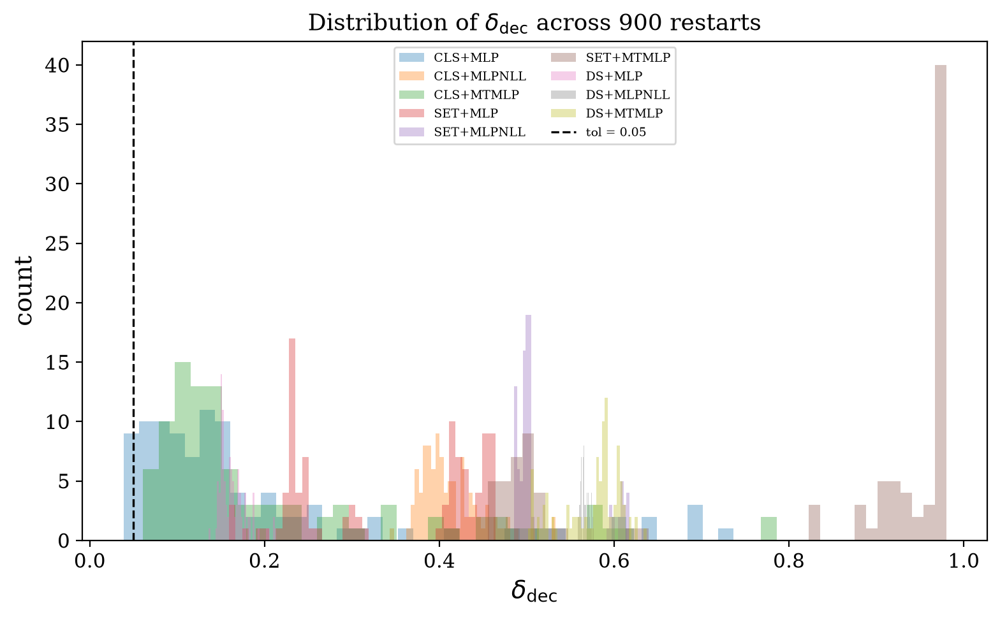

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))
for v in VAES:
    for r in REGS:
        d = results[f'{v}_{r}']['delta']
        ax.hist(d, bins=40, alpha=0.35, label=f'{v}+{r}')
ax.axvline(DELTA_TOL, color='k', ls='--', lw=1.2, label=f'tol = {DELTA_TOL}')
ax.set_xlabel(r'$\delta_{\rm dec}$'); ax.set_ylabel('count')
ax.set_title(r'Distribution of $\delta_{\rm dec}$ across 900 restarts')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(SAVE / 'figure_S1.png', dpi=300)

## Sort descret 

In [50]:
import numpy as np, torch, h5py, pandas as pd
from scipy.stats import kendalltau, spearmanr, rankdata

H5 = globals().get('H5', './data/DL/latent_db_all.h5')
MD = globals().get('MD', './data/DL/models')

_miss = [k for k in ('device','VAES','load_model',
                     'df_test','df_val','df_unique') if k not in globals()]
if _miss: raise SystemExit(f"missing core: {_miss}")

K, bs, KS = 1_000_000, 65536, (10, 100, 1000)
_ALL = [
    ('PSMLP',  'PSMLP',  'PSMLP',  'ps'),
    ('APSMLP', 'APSMLP', 'APSMLP', 'ps'),
    ('DSMLP',  'DSMLP',  'DSMLP',  'ds'),
    ('MTM',    'MTMLP',  'MTM',    'mt'),
    ('MLP',    'MLP',    'MLP',    'reg'),
    ('MLPNLL', 'MLPNLL', 'MLPNLL', 'reg'),
]
_miss_cls = [c for _, c, _, _ in _ALL if c not in globals()]
MODELS = [(d, globals()[c], ck, k) for d, c, ck, k in _ALL if c in globals()]
if _miss_cls: print(f"WARN: skipping models not in namespace: {_miss_cls}")
if not MODELS: raise SystemExit("no model classes available")

def _chunks(n, w=None):
    w = bs if w is None else w
    for s in range(0, n, w):
        yield s, min(s + w, n)

@torch.inference_mode()
def fwd(m, *xs, kind='reg'):
    out = np.empty(len(xs[0]), np.float32)
    for s, e in _chunks(len(xs[0])):
        r = m(*(torch.from_numpy(x[s:e]).to(device) for x in xs))
        if kind == 'mt':
            if r.ndim > 1: r = r[:, 0]
        elif kind == 'reg':
            if isinstance(r, tuple): r = r[0]
            if r.ndim > 1: r = r[:, 0]
        out[s:e] = r.view(-1).cpu().numpy()
    return out

def _check_pair(name, m, kind, X):
    if kind not in ('ps', 'ds') or len(X) < 8: return
    i = np.linspace(0, len(X) - 1, 8, dtype=int)
    r = fwd(m, X[i[:4]], X[i[4:]], kind=kind)
    assert r.shape == (4,), f"{name}: pair-head shape {r.shape}, expected (4,)"
    assert not (r.min() >= 0 and r.max() <= 1 and (r.max() - r.min()) > 0.1), \
        f"{name}: pair-head in [0,1] range {r.min():.3f}..{r.max():.3f}; expected logits"

def gt(m, kind, X, Y):
    if kind in ('ps', 'ds'): return fwd(m, X, Y, kind=kind) > 0
    return fwd(m, X, kind=kind) > fwd(m, Y, kind=kind)
    
def triplet(m, kind, A, B, C):

    if kind in ('reg', 'mt'):
        fa, fb, fc = fwd(m, A, kind=kind), fwd(m, B, kind=kind), fwd(m, C, kind=kind)
        return (fa > fb, fb > fa, fb > fc, fc > fb, fc > fa, fa > fc)
        #       ab       ba       bc       cb       ca       ac
    return (fwd(m, A, B, kind=kind) > 0,   # ab
            fwd(m, B, A, kind=kind) > 0,   # ba
            fwd(m, B, C, kind=kind) > 0,   # bc
            fwd(m, C, B, kind=kind) > 0,   # cb
            fwd(m, C, A, kind=kind) > 0,   # ca  ← was ac
            fwd(m, A, C, kind=kind) > 0)   # ac  ← was ca

def score(m, kind, z, blk=512, mc=None):
    if kind in ('reg', 'mt'): return fwd(m, z, kind=kind)
    N = len(z)
    if mc:
        rng = np.random.default_rng(0)
        J = rng.integers(0, N - 1, (N, mc))
        J += J >= np.arange(N)[:, None]
        s = np.empty(N, np.float32)
        for i, e in _chunks(N, blk):
            s[i:e] = (fwd(m, np.repeat(z[i:e], mc, 0), z[J[i:e].reshape(-1)], kind=kind) > 0) \
                     .reshape(e - i, mc).mean(1)
        return s
    s = np.zeros(N, np.float32)
    for i, e in _chunks(N, blk):
        for j, f in _chunks(N, blk):
            X, Y = np.repeat(z[i:e], f - j, 0), np.tile(z[j:f], (e - i, 1))
            s[i:e] += (fwd(m, X, Y, kind=kind) > 0).reshape(e - i, f - j).sum(1)
    return s

def r_metrics(y, s):
    N = len(y)
    rt, rp = rankdata(-y) - 1, rankdata(-s) - 1
    if np.ptp(rp) > 0 and np.ptp(rt) > 0:
        sp = float(np.corrcoef(rp, rt)[0, 1])
        kt = kendalltau(rp, rt).statistic
    else:
        sp = kt = 0.0
    desc  = sp >= 0
    order = np.argsort(-s, kind='stable') if desc else np.argsort(s, kind='stable')
    y_ord, g = y[order], y - y.min() + 1e-9
    ig = np.sort(g)[::-1]; d = lambda k: 1.0 / np.log2(np.arange(2, k + 2))
    ndcg = {k: float((g[order][:k] * d(k)).sum() / (ig[:k] * d(k)).sum()) for k in KS if k <= N}
    top_y = np.argsort(-y, kind='stable')
    topk = {k: len(set(top_y[:k]) & set(order[:k])) / k for k in KS if k <= N}
    if N >= 10:
        bk = np.array_split(y_ord, 10); bm = np.array([b.mean() for b in bk])
        ht, bv = float(bk[0].mean() - bk[-1].mean()), int((np.diff(bm) < 0).sum())
    else:
        ht, bv = np.nan, np.nan
    adj = int((np.diff(y_ord) < 0).sum()) if N > 1 else 0
    return dict(N=N, desc=bool(desc), sp=sp, kt=kt, inv=(1 - kt) / 2,
                ndcg=ndcg, topk=topk, adj=adj, ht=ht, bv=bv,
                y_head=y_ord[:5].tolist(), y_tail=y_ord[-5:].tolist())

def run_ranking(df, target='Fa_mean'):
    y = df[target].values.astype(np.float32); out = {}
    for v in VAES:
        col = f'latent_{v}'
        if col not in df.columns: continue
        z = np.stack(df[col].values).astype(np.float32)
        print(f"\n[{v}] ranking  N={len(z)}")
        for name, cls, ckpt, kind in MODELS:
            try:
                m = load_model(f"{MD}/{name}_{v}_best.pt", cls, device)
                _check_pair(name, m, kind, z)
                r = r_metrics(y, score(m, kind, z))
                flag = '' if r['desc'] else ' flip'
                print(f"  {name:8s} sp={r['sp']:+.4f}{flag} kt={r['kt']:+.4f} inv%={r['inv']*100:5.2f} "
                      f"adj={r['adj']:3d} bv={r['bv']} ht={r['ht']:+7.2f}  "
                      f"ndcg10={r['ndcg'].get(10,0):.3f} top10={r['topk'].get(10,0):.3f}")
                out[(v, name)] = {k: r[k] for k in ('N','desc','sp','kt','inv','adj','bv','ht')}
                out[(v, name)]['ndcg10'] = r['ndcg'].get(10, np.nan)
                out[(v, name)]['top10']  = r['topk'].get(10, np.nan)
                out[(v, name)]['y_head'] = r['y_head']
                out[(v, name)]['y_tail'] = r['y_tail']
                del m
            except Exception as e:
                print(f"  {name:8s} skip: {e}")
    if not out: print("  ALL SKIPPED")
    return pd.DataFrame(out).T

def triplet(m, kind, A, B, C):
    if kind in ('reg', 'mt'):
        fa, fb, fc = fwd(m, A, kind=kind), fwd(m, B, kind=kind), fwd(m, C, kind=kind)
        return (fa > fb, fb > fa, fb > fc, fc > fb, fc > fa, fa > fc)
        #       ab       ba       bc       cb       ca       ac
    return (fwd(m, A, B, kind=kind) > 0,   # ab
            fwd(m, B, A, kind=kind) > 0,   # ba
            fwd(m, B, C, kind=kind) > 0,   # bc
            fwd(m, C, B, kind=kind) > 0,   # cb
            fwd(m, C, A, kind=kind) > 0,   # ca 
            fwd(m, A, C, kind=kind) > 0)   # ac

def t_metrics(ab, ba, bc, cb, ca, ac):
    n_cov   = int((ab & bc).sum())
    cyc_fwd = (ab & bc & ca).mean()    # A>B ∧ B>C ∧ C>A
    cyc_bwd = (ba & cb & ac).mean()    # B>A ∧ C>B ∧ A>C  (strict, tie-free)
    chain   = (ab & bc & ac).mean()    # A>B ∧ B>C ∧ A>C  (transitive)
    bf      = (~ab & ~ba).mean()       # both false = tie
    cyc     = cyc_fwd + cyc_bwd
    return dict(
        antisym=(ab ^ ba).mean(), bt=(ab & ba).mean(), bf=bf,
        chain=chain, cov=(ab & bc).mean(), n_cov=n_cov,
        trans=(ab & bc & ac).sum() / (n_cov + 1e-12),
        cyc_fwd=cyc_fwd, cyc_bwd=cyc_bwd, cyc=cyc,
        net=1.0 - 2.0 * cyc,
        tau=1.0 - 2.0 * cyc,
    )

def run_triplet():
    with h5py.File(H5, 'r') as f:
        keys = sorted(k for k in f if k.startswith('mu_'))
        n_min = min(len(f[k]) for k in keys)
        rng = np.random.default_rng(0)
        i = rng.integers(0, n_min, (3, K))
        i = i[:, (i[0] != i[1]) & (i[1] != i[2]) & (i[0] != i[2])]
        for key in keys:
            v, mu = key[3:], f[key][:]
            A, B, C = (mu[j] for j in i)
            print(f"\n[{v}] triplet  N={len(mu):,}  d={mu.shape[1]}  T={len(A):,}  "
                  f"(random: cyc≈0.25, net≈0.50)")
            for name, cls, ckpt, kind in MODELS:
                try:
                    m = load_model(f"{MD}/{name}_{v}_best.pt", cls, device)
                    _check_pair(name, m, kind, A)
                    r = t_metrics(*triplet(m, kind, A, B, C))
                    print(f"  {name:8s} antisym={r['antisym']:.4f} (bt={r['bt']:.4f} bf={r['bf']:.4f})  "
                          f"chain={r['chain']:.4f}  trans={r['trans']:.4f}  "
                          f"cyc={r['cyc']:.4f} ({r['cyc_fwd']:.4f}/{r['cyc_bwd']:.4f})  "
                          f"tau={r['tau']:+.4f}  net={r['net']:+.4f}")
                    del m
                except Exception as e:
                    print(f"  {name:8s} skip: {e}")
                    
run_triplet()
print("\n", run_ranking(df_test))
print("\n", run_ranking(pd.concat([df_val, df_test], ignore_index=True)))
print("\n", run_ranking(df_unique))

SystemExit: missing core: ['VAES', 'load_model', 'df_test', 'df_val', 'df_unique']

#### Sort 25m

In [65]:
def _cmp(model, Z, ia, ib, bs, device):
    out = torch.empty(len(ia), dtype=torch.bool)
    for s in range(0, len(ia), bs):
        e = min(s + bs, len(ia))
        x = Z[ia[s:e]].to(device, non_blocking=True)
        y = Z[ib[s:e]].to(device, non_blocking=True)
        with torch.inference_mode():
            out[s:e] = (model(x, y).view(-1) > 0).cpu()
    return out


def quicksort(Z, model, pivot="mid", bs=65536, verbose=False, device=None):
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    N = len(Z)
    if N < 2: return np.arange(N, dtype=np.int64)
    order = torch.arange(N); lo = torch.tensor([0]); hi = torch.tensor([N - 1])
    it = tqdm(desc=f"[qsort/{pivot}]") if verbose else None
    try:
        while lo.numel():
            sz = hi - lo + 1; m = sz >= 2
            if not m.any(): break
            a_lo, a_hi, a_len = lo[m], hi[m], sz[m]
            S, T = a_lo.numel(), int(a_len.sum())
            psid = torch.repeat_interleave(torch.arange(S), a_len)
            cum = torch.cumsum(a_len, 0) - a_len
            pos = a_lo[psid] + torch.arange(T) - cum[psid]
            piv = (((a_lo + a_hi) // 2) if pivot == "mid"
                   else (a_lo + (torch.rand(S) * a_len.float()).long().clamp(max=a_len - 1)))[psid]
            ip = pos == piv
            gt = _cmp(model, Z, order[pos], order[piv], bs, device)
            gt[ip] = False
            w = ~gt & ~ip
            z = torch.zeros(1, dtype=torch.long)
            cg = torch.cat([z, gt.long().cumsum(0)]); cw = torch.cat([z, w.long().cumsum(0)])
            nb = cg[cum + a_len] - cg[cum]; L, NB = a_lo[psid], nb[psid]
            npos = torch.empty(T, dtype=torch.long)
            npos[gt] = L[gt] + cg[1:][gt] - cg[cum][psid][gt] - 1
            npos[w]  = L[w]  + NB[w] + cw[1:][w] - cw[cum][psid][w]
            npos[ip] = L[ip] + NB[ip]
            new_order = order.clone(); new_order.index_copy_(0, npos, order[pos]); order = new_order
            sp = a_lo + nb; ml, mr = nb > 0, a_len - nb - 1 > 0
            lo = torch.cat([a_lo[ml], (sp + 1)[mr], lo[~m]])
            hi = torch.cat([(sp - 1)[ml], a_hi[mr], hi[~m]])
            if it is not None: it.update(1)
    finally:
        if it is not None: it.close()
    return order.numpy()


def score_sort(Z, model, bs=65536, kind="ds", verbose=False, device=None):
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    N = len(Z); pred = np.empty(N, dtype=np.float32)
    it = tqdm(total=N, desc=f"[{kind}]") if verbose else None
    try:
        for s in range(0, N, bs):
            e = min(s + bs, N)
            x = Z[s:e].to(device, non_blocking=True)
            with torch.inference_mode():
                out = model.score(x) if kind == "ds" else model(x)[:, 0]
            pred[s:e] = out.view(-1).cpu().numpy()
            if it is not None: it.update(e - s)
    finally:
        if it is not None: it.close()
    return np.argsort(-pred).astype(np.int64)


def reg_sort(Z, model, bs=65536, mode="mean", beta=1.0, verbose=False, device=None):
    device = device or torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    N = len(Z); pred = np.empty(N, dtype=np.float32)
    it = tqdm(total=N, desc=f"[reg/{mode}]") if verbose else None
    try:
        for s in range(0, N, bs):
            e = min(s + bs, N)
            x = Z[s:e].to(device, non_blocking=True)
            with torch.inference_mode():
                out = model(x)
            if isinstance(out, tuple):
                mean = out[0].view(-1)
                logvar = out[1].view(-1) if len(out) > 1 else None
                if logvar is not None and mode != "mean":
                    std = torch.exp(0.5 * logvar)
                    v = (mean - beta * std) if mode == "lcb" else (mean + beta * std)
                else:
                    v = mean
            else:
                v = out.view(-1)
            pred[s:e] = v.cpu().numpy()
            if it is not None: it.update(e - s)
    finally:
        if it is not None: it.close()
    return np.argsort(-pred).astype(np.int64)


def _ndcg(idx, y, k):
    k = min(k, len(idx))
    g = y[idx[:k]] - y.min() + 1e-6
    d = 1.0 / np.log2(np.arange(2, k + 2))
    ideal = np.sort(y)[::-1][:k] - y.min() + 1e-6
    return float((g * d).sum() / (ideal * d).sum())


def _kendall_sampled(a, b, n=500_000, rng=None):
    N = len(a)
    rng = rng or np.random.default_rng(0)
    i = rng.integers(0, N, n); j = rng.integers(0, N, n)
    k = i != j
    return float((np.sign(a[i[k]] - a[j[k]]) * np.sign(b[i[k]] - b[j[k]])).mean())


def eval_vs_target(idx, y):
    r = np.empty(len(idx), dtype=np.int64); r[idx] = np.arange(len(idx)) + 1
    t = rankdata(-y)
    return dict(kendall=float(_kendall_sampled(r, t)),
                spearman=float(spearmanr(r, t).statistic),
                ndcg10=_ndcg(idx, y, 10),
                ndcg100=_ndcg(idx, y, 100),
                ndcg1000=_ndcg(idx, y, 1000))


def cross_agreement(a, b):
    N = len(a)
    ra = np.empty(N, np.int32); ra[a] = np.arange(N)
    rb = np.empty(N, np.int32); rb[b] = np.arange(N)
    return dict(kendall=_kendall_sampled(ra, rb),
                spearman=float(spearmanr(ra, rb).statistic),
                top100=len(set(a[:100]) & set(b[:100])) / 100)


METHODS = [
    ("ps_qmid",     "ps",  lambda Z, m, bs, v, d: quicksort(Z, m, "mid",    bs, v, d)),
    ("ps_qrand",    "ps",  lambda Z, m, bs, v, d: quicksort(Z, m, "random", bs, v, d)),
    ("aps_qmid",    "aps", lambda Z, m, bs, v, d: quicksort(Z, m, "mid",    bs, v, d)),
    ("aps_qrand",   "aps", lambda Z, m, bs, v, d: quicksort(Z, m, "random", bs, v, d)),
    ("ds_qmid",     "ds",  lambda Z, m, bs, v, d: quicksort(Z, m, "mid",    bs, v, d)),
    ("ds_qrand",    "ds",  lambda Z, m, bs, v, d: quicksort(Z, m, "random", bs, v, d)),
    ("ds_fast",     "ds",  lambda Z, m, bs, v, d: score_sort(Z, m, bs, "ds", v, d)),
    ("reg_mlp",     "mlp", lambda Z, m, bs, v, d: reg_sort(Z, m, bs, "mean", 1.0, v, d)),
    ("reg_nll",     "nll", lambda Z, m, bs, v, d: reg_sort(Z, m, bs, "mean", 1.0, v, d)),
    ("reg_nll_lcb", "nll", lambda Z, m, bs, v, d: reg_sort(Z, m, bs, "lcb",  1.0, v, d)),
    ("mtm_fa",      "mt",  lambda Z, m, bs, v, d: score_sort(Z, m, bs, "mt", v, d)),
]


def run_all_and_save(h5_path, models, device, y_key="Fa_mean",
                     bs=262144, overwrite=True, verbose=True):
    idx_all = {}
    with h5py.File(h5_path, "r+") as f:
        for k in [k for k in f if k.startswith("mu_")]:
            vae = k[3:]
            if vae not in models: continue
            Z = torch.from_numpy(np.ascontiguousarray(f[k][:], np.float32)).pin_memory()
            grp = f.require_group(f"sorted_indices/{vae}")
            idx_all[vae] = {}
            for name, kind, fn in METHODS:
                if kind not in models[vae]: continue
                if name in grp and not overwrite:
                    idx = grp[name][:]
                else:
                    if verbose: print(f"[{vae}] {name}")
                    idx = fn(Z, models[vae][kind], bs, verbose, device)
                    if name in grp: del grp[name]
                    grp.create_dataset(name, data=idx.astype(np.int32), compression="lzf")
                idx_all[vae][name] = idx
            del Z; gc.collect()
            if device.type == "cuda": torch.cuda.empty_cache()

        if y_key and y_key in f.attrs:
            y = f.attrs[y_key][:]
            rows = [dict(VAE=v, Method=m, **eval_vs_target(idx_all[v][m], y))
                    for v in idx_all for m in idx_all[v]
                    if len(y) == len(idx_all[v][m])]
            if rows:
                print("\n=== vs target ===")
                print(pd.DataFrame(rows).to_string(index=False, float_format="%.4f"))

    print("\n=== cross-method (Kendall, 500k) ===")
    for v, per in idx_all.items():
        n = list(per)
        M = pd.DataFrame(np.eye(len(n)), index=n, columns=n)
        for i, a in enumerate(n):
            for j, b in enumerate(n):
                if i < j:
                    M.iloc[i, j] = M.iloc[j, i] = cross_agreement(per[a], per[b])["kendall"]
        print(f"\n[{v}]")
        print(M.to_string(float_format="%.3f"))

    print("\n=== cross-VAE (per method) ===")
    for name, _, _ in METHODS:
        vs = [v for v in idx_all if name in idx_all[v]]
        for i, a in enumerate(vs):
            for b in vs[i + 1:]:
                m = cross_agreement(idx_all[a][name], idx_all[b][name])
                print(f"[{name}] {a} vs {b}: τ={m['kendall']:+.3f} "
                      f"ρ={m['spearman']:+.3f} top100={m['top100']:.3f}")
    return idx_all

In [66]:
vaes = ["CLS", "SET", "DS"]
models = {
    v: {
        "ps":  load_model(f"./data/DL/models/PSMLP_{v}_best.pt",  PSMLP,  device=device),
        "aps": load_model(f"./data/DL/models/APSMLP_{v}_best.pt", APSMLP, device=device),
        "ds":  load_model(f"./data/DL/models/DSMLP_{v}_best.pt",  DSMLP,  device=device),
        "mlp": load_model(f"./data/DL/models/MLP_{v}_best.pt",    MLP,    device=device),
        "nll": load_model(f"./data/DL/models/MLPNLL_{v}_best.pt", MLPNLL, device=device),
        "mt":  load_model(f"./data/DL/models/MTM_{v}_best.pt",    MTMLP,  device=device),
    }
    for v in vaes
}
res = run_all_and_save("./data/DL/latent_db.h5", models, device, bs=262144, overwrite=True)

[CLS] ps_qmid


[qsort/mid]: 1318it [18:50,  1.17it/s]


[CLS] ps_qrand


[qsort/random]: 1392it [19:36,  1.18it/s]


[CLS] aps_qmid


...

[CLS] mtm_fa


[mt]: 100%|███████████████████| 41517904/41517904 [00:07<00:00, 5910558.24it/s]


[DS] ps_qmid


[qsort/mid]: 46848it [16:59:24,  1.31s/it]


KeyboardInterrupt: 

In [ ]:
import numpy as np, pandas as pd, h5py, torch, gc
from scipy.stats import spearmanr, norm
from sklearn.cluster import KMeans
from sklearn.covariance import EmpiricalCovariance

def _ranks(a):
    r = np.empty(len(a), np.int32); r[a] = np.arange(len(a), dtype=np.int32); return r

def _kendall(a, b, n=500_000, rng=None):
    rng = rng or np.random.default_rng(0); N = len(a)
    i, j = rng.integers(0, N, n), rng.integers(0, N, n); k = i != j
    return float((np.sign(a[i[k]] - a[j[k]]) * np.sign(b[i[k]] - b[j[k]])).mean())

def _rbo(a, b, p=0.9, k=10000):
    k = min(k, len(a), len(b))
    sa, sb, ov, ws, w = set(), set(), 0.0, 0.0, 1.0
    for i in range(k):
        sa.add(a[i]); sb.add(b[i]); ov += len(sa & sb) / (i + 1); ws += w; w *= p
    return (1 - p) * ov / ws if ws > 0 else 0.0

def _enrich(a, b, N, ks=(10, 100, 1000, 10000)):
    return {f"top{k}": (len(set(a[:k]) & set(b[:k])) / k) / (k / N)
            for k in ks if k <= len(a) and k <= len(b)}

def _pairwise(scores, N, n=500_000):
    names = list(scores); idx = {n_: np.argsort(-scores[n_]) for n_ in names}
    rng = np.random.default_rng(0); rows = []
    for i, a in enumerate(names):
        for b in names[i+1:]:
            ra, rb = _ranks(idx[a]), _ranks(idx[b])
            r = dict(a=a, b=b, kendall=_kendall(ra, rb, n, rng),
                     spearman=float(spearmanr(ra, rb).statistic),
                     rbo90=_rbo(idx[a], idx[b], p=0.90, k=10000),
                     rbo95=_rbo(idx[a], idx[b], p=0.95, k=10000))
            r.update(_enrich(idx[a], idx[b], N)); rows.append(r)
    return pd.DataFrame(rows)

@torch.inference_mode()
def _infer(models_v, Z, device, bs=262144):
    N = len(Z); out = {n: np.empty(N, np.float32) for n in models_v if n != 'pairwise'}
    for name, m in models_v.items():
        if name == 'pairwise': continue
        for s in range(0, N, bs):
            e = min(s + bs, N); x = Z[s:e].to(device, non_blocking=True)
            if name == 'nll':
                mu, lv = m(x); out[name][s:e] = mu.view(-1).cpu().numpy()
                out.setdefault('nll_sigma', np.empty(N, np.float32))[s:e] = torch.exp(0.5 * lv).view(-1).cpu().numpy()
            elif name == 'mt':
                y = m(x)
                for j, t in enumerate(['fa','Q','G','TanD','k']):
                    out.setdefault(f'mt_{t}', np.empty(N, np.float32))[s:e] = y[:, j].cpu().numpy()
                out[name][s:e] = y[:, 0].cpu().numpy()
            elif name == 'ds': out[name][s:e] = m.score(x).cpu().numpy()
            else: out[name][s:e] = m(x).view(-1).cpu().numpy()
    if 'nll' in out:
        mu, sig = out['nll'], out['nll_sigma']
        out['ucb'], out['lcb'] = mu + sig, mu - sig
        z = (mu - mu.max()) / (sig + 1e-8)
        out['ei'] = sig * (z * norm.cdf(z) + norm.pdf(z))
        out['ts'] = mu + sig * np.random.default_rng(0).standard_normal(N).astype(np.float32)
    return out

def _ood(Z_tr, Z_te):
    return EmpiricalCovariance().fit(Z_tr).mahalanobis(Z_te).astype(np.float32)

def _select(scores, Z, pool, N=10):
    df = pd.DataFrame({'idx': pool})
    for k, v in scores.items():
        if k.endswith('_sigma'): continue
        df[k] = v[pool]
    df['n_agree'] = sum((scores[k] >= np.quantile(scores[k], 0.99))[pool]
                        for k in scores if not k.endswith('_sigma'))
    df['cluster'] = KMeans(min(N * 2, len(pool)), n_init=10, random_state=0).fit_predict(Z[pool])
    df = df.sort_values('ucb', ascending=False)
    keep, seen = [], set()
    for _, r in df.iterrows():
        if r['cluster'] in seen: continue
        keep.append(r); seen.add(r['cluster'])
        if len(keep) >= N: break
    return pd.DataFrame(keep), df

def run(H5, MD, Ztr, device, TOP_K=25, N=10):
    res = {}
    CKPT = [('mlp', MLP, 'MLP'), ('nll', MLPNLL, 'MLPNLL'),
            ('ds', DSMLP, 'DSMLP'), ('mt', MTMLP, 'MTM')]
    with h5py.File(H5, "r") as f:
        for vae in f["sorted_indices"].keys():
            Zc = torch.from_numpy(f[f"mu_{vae}"][:].astype(np.float32)).pin_memory()
            M = {n: load_model(f"{MD}/{cls_name}_{vae}_best.pt", cls, device=device)
                 for n, cls, cls_name in CKPT}
            sc = _infer(M, Zc, device)
            if vae in Ztr: sc['ood'] = _ood(Ztr[vae], f[f"mu_{vae}"][:])
            pw = _pairwise(sc, len(Zc))
            pool = sorted(set().union(*[np.argsort(-sc[k])[:TOP_K]
                                        for k in sc if not k.endswith('_sigma')]))
            final, df = _select(sc, f[f"mu_{vae}"][:], pool, N)
            res[vae] = dict(pairwise=pw, pool=df, final=final)
            print(f"\n[{vae}] {len(final)}/{len(pool)}")
            print(final[['idx','ucb','n_agree','cluster']].to_string(index=False))
            del M, Zc, sc; gc.collect()
            if device.type == 'cuda': torch.cuda.empty_cache()
    return res

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VAES = ["CLS", "SET", "DS"]
Ztr = {v: np.stack(df_train[f'latent_{v}'].values).astype(np.float32) for v in VAES}
res = run("./data/DL/latent_db.h5", "./data/DL/models", Ztr, device, TOP_K=25, N=10)

In [ ]:
for vae in ['CLS','DS','SET']:
    print(f"\n{'═'*70}\n{vae} — pairwise\n{'═'*70}")
    pw = res[vae]['pairwise']
    cols = [c for c in ['a','b','kendall','spearman','rbo90','rbo95',
                        'top10','top100','top1000','top10000'] if c in pw.columns]
    print(pw[cols].to_string(index=False, float_format="%.3f"))

for vae in ['CLS','DS','SET']:
    df = res[vae]['pool']
    print(f"\n[{vae}] pool={len(df)}  ucb=[{df.ucb.min():.1f}, {df.ucb.max():.1f}]")
    print(f"  n_agree: {df.n_agree.value_counts().sort_index().to_dict()}")
    print(f"  clusters: {df.cluster.nunique()}")

for vae in ['CLS','DS','SET']:
    print(f"\n{'═'*70}\n{vae} — final\n{'═'*70}")
    final = res[vae]['final']
    cols = ['idx','ucb','lcb','ei','nll','nll_sigma','ds','mt','mt_Q','mt_G',
            'mt_TanD','mt_k','ood','n_agree','cluster']
    cols = [c for c in cols if c in final.columns]
    print(final[cols].to_string(index=False, float_format="%.2f"))

def decode(row, names, eps=1e-6):
    nz = np.where(row > eps)[0]
    order = nz[np.argsort(-row[nz])]
    return " / ".join(f"{names[i]}:{row[i]:.2f}" for i in order)

with h5py.File("./data/DL/latent_db.h5", "r") as f:
    names = [n.decode() if isinstance(n, bytes) else n for n in f.attrs["monomer_names"]]
    for vae in ['CLS','DS','SET']:
        print(f"\n{'═'*70}\n{vae} — compositions\n{'═'*70}")
        idxs = np.asarray(res[vae]['final']['idx'].values, dtype=np.int64)
        fracs = f["fractions"][:][idxs]
        for idx, row in zip(idxs, fracs):
            ucb = res[vae]['final'].loc[res[vae]['final']['idx']==idx, 'ucb'].values[0]
            n   = res[vae]['final'].loc[res[vae]['final']['idx']==idx, 'n_agree'].values[0]
            print(f"{int(idx):>10}  UCB={ucb:.1f}  n={int(n)}")
            print(f"           {decode(row, names)}")

## Figures

In [56]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
import torch, torch.nn.functional as F

FIG = Path("figs"); FIG.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 9.5,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
})

ARCH_COLORS = {"CLS": "#0072B2", "SET": "#D55E00", "DS": "#009E73"}
ARCHS       = ["CLS", "SET", "DS"]
GREY_INACT  = "#CCCCCC"
GREY_EDGE   = "#222222"
GREY_GRID   = "#CCCCCC"

def style_axes(ax, grid_axis="y", alpha=0.6):
    ax.grid(False)
    ax.grid(axis=grid_axis, color=GREY_GRID, lw=0.3, alpha=alpha)
    ax.set_axisbelow(True)

In [ ]:
from pathlib import Path
from collections import defaultdict
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

HIST_KEYS = ["train_loss", "val_loss", "val_ffp", "val_auto", "val_kl",
             "val_geom", "val_geom_ffp", "val_geom_auto", "beta", "lr"]

TAG_CANDIDATES = {
    "train_loss":    ["Metrics/train_loss", "train_loss", "Loss/Total/Train"],
    "val_loss":      ["Metrics/val_loss",   "val_loss",   "Loss/Total/Val"],
    "val_ffp":       ["Metrics/val_ffp",    "val_ffp"],
    "val_auto":      ["Metrics/val_auto",   "val_auto"],
    "val_kl":        ["Metrics/val_kl",     "val_kl"],
    "val_geom":      ["Metrics/val_geom",   "val_geom"],
    "val_geom_ffp":  ["Metrics/val_geom_ffp",   "val_geom_ffp"],
    "val_geom_auto": ["Metrics/val_geom_auto",  "val_geom_auto"],
    "beta":          ["Metrics/beta",       "beta"],
    "lr":            ["Metrics/lr",         "lr"],
}

def load_histories(root="runs", verbose=True):
    root = Path(root)
    out = {}
    event_dirs = set()
    if root.exists():
        for p in root.rglob("events.out.tfevents.*"):
            event_dirs.add(p.parent)

    if verbose:
        print(f"Found {len(event_dirs)} event dir(s) under {root.resolve()}")
        for d in sorted(event_dirs):
            n_ev = len(list(d.glob("events.out.tfevents.*")))
            print(f"  {d.relative_to(root)}   ({n_ev} event file(s))")

    for name in ["CLS", "SET", "DS"]:
        model_dirs = [d for d in event_dirs
                      if name.lower() in str(d.relative_to(root)).lower()]
        merged = defaultdict(list)
        for d in model_dirs:
            try:
                ea = EventAccumulator(str(d), size_guidance={"scalars": 0})
                ea.Reload()
                for tag in ea.Tags().get("scalars", []):
                    for e in ea.Scalars(tag):
                        merged[tag].append((e.step, e.value))
            except Exception as exc:
                if verbose:
                    print(f"  [warn] could not read {d}: {exc}")
        h = {}
        for key in HIST_KEYS:
            for cand in TAG_CANDIDATES[key]:
                if cand in merged:
                    rows = sorted(merged[cand])
                    dedup = {}
                    for step, val in rows:
                        dedup[step] = val
                    h[key] = [dedup[s] for s in sorted(dedup)]
                    break

        out[name] = h

        if verbose:
            n_ep    = len(h.get("val_loss", []))
            missing = [k for k in HIST_KEYS if k not in h]
            status  = "OK" if n_ep > 0 else "MISSING"
            best    = min(h["val_loss"]) if n_ep else float("nan")
            last    = h["val_loss"][-1] if n_ep else float("nan")
            print(f"\n[{name}]  dirs={len(model_dirs)}  "
                  f"epochs={n_ep}  val_loss={status}  "
                  f"best={best:.4f}  last={last:.4f}")
            if missing:
                print(f"  missing keys: {missing}")

    return out


histories = load_histories("runs")

Found 108 event dir(s) under /home/art/Documents/GitHub/hydrogels/ML/runs
  APSMLP_CLS_pairwise   (4 event file(s))
  APSMLP_CLS_pairwise/EarlyStop_bad   (4 event file(s))
  APSMLP_CLS_pairwise/EarlyStop_best   (4 event file(s))
  APSMLP_CLS_pairwise/Loss_train   (4 event file(s))
  APSMLP_CLS_pairwise/Loss_val   (4 event file(s))
  APSMLP_DS_pairwise   (3 event file(s))
  APSMLP_DS_pairwise/EarlyStop_bad   (3 event file(s))
  APSMLP_DS_pairwise/EarlyStop_best   (3 event file(s))
  APSMLP_DS_pairwise/Loss_train   (3 event file(s))
  APSMLP_DS_pairwise/Loss_val   (3 event file(s))
  APSMLP_SET_pairwise   (3 event file(s))
  APSMLP_SET_pairwise/EarlyStop_bad   (3 event file(s))
  APSMLP_SET_pairwise/EarlyStop_best   (3 event file(s))
  APSMLP_SET_pairwise/Loss_train   (3 event file(s))
  APSMLP_SET_pairwise/Loss_val   (3 event file(s))
  CLS_VAE   (5 event file(s))
  CLS_VAE/Loss_Auto_Component_Train   (1 event file(s))
  CLS_VAE/Loss_Auto_Component_Validation   (1 event file(s))
  CLS_V

In [74]:
for v in ("z_cls", "z_set", "z_ds"):
    if v in globals():
        del globals()[v]
gc.collect()

test_ds = PolymerStreamDataset(
    ffp=ffp_arr_64,
    auto=auto_arr_64,
    samples_per_epoch=25_000,
    seq_len=1000,
    seed=999,
    batch_size=64,
)
test_ds.set_epoch(1)

test_loader = DataLoader(
    test_ds,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

N_SYN_EFF = sum(b[0].size(0) for b in test_loader)
print(f"Synthetic test set effective size: N = {N_SYN_EFF:,} "
      f"(requested 25,000; floor to multiple of nw×bs = 4×64 = 256)")

model_cls = load_pretrained_vae('CLS', './data/DL/models/CLS_VAE.pt', device)
model_set = load_pretrained_vae('SET', './data/DL/models/SET_VAE.pt', device)
model_ds  = load_pretrained_vae('DS',  './data/DL/models/DS_VAE.pt',  device)

z_cls = get_latent_mu(model_cls, test_loader)
z_set = get_latent_mu(model_set, test_loader)
z_ds  = get_latent_mu(model_ds,  test_loader)

print(f"z_cls: {z_cls.shape}   z_set: {z_set.shape}   z_ds: {z_ds.shape}")
assert z_cls.shape[0] == N_SYN_EFF, "count mismatch — check test_loader"

del model_cls, model_set, model_ds
torch.cuda.empty_cache(); gc.collect()

Synthetic test set effective size: N = 24,832 (requested 25,000; floor to multiple of nw×bs = 4×64 = 256)
z_cls: (24832, 64)   z_set: (24832, 64)   z_ds: (24832, 64)


10

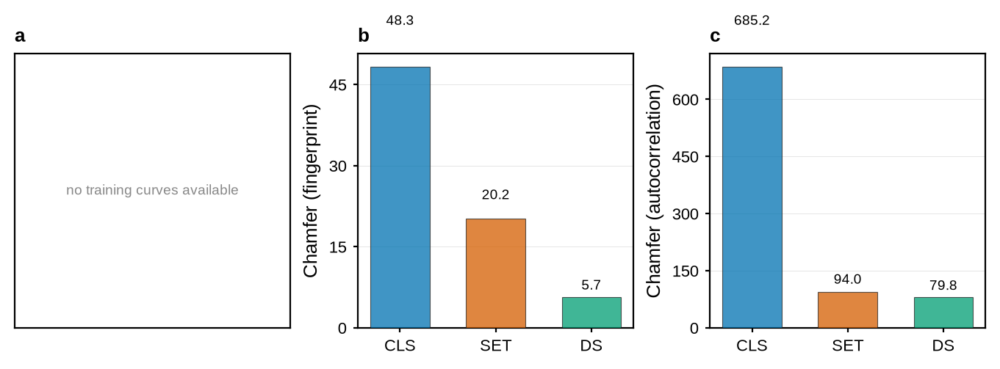

In [75]:
fig, ax = plt.subplots(1, 3, figsize=(6.69, 2.4), constrained_layout=True)

curves_ok = all(len(histories.get(n, {}).get("val_loss", [])) > 0 for n in ARCHS)
if curves_ok:
    for name in ARCHS:
        v  = histories[name]["val_loss"]
        ep = np.arange(1, len(v) + 1)
        ax[0].plot(ep, v, color=ARCH_COLORS[name],
                   lw=1.2, marker="o", ms=3.0, label=name)
    ax[0].set_yscale("log")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Validation loss")
    ax[0].legend(frameon=False, handlelength=1.0)
    style_axes(ax[0])
else:
    ax[0].text(0.5, 0.5, "no training curves available",
               ha="center", va="center", transform=ax[0].transAxes,
               fontsize=7, color="#888888")
    ax[0].set_xticks([]); ax[0].set_yticks([])
ax[0].set_title("a", loc="left", fontweight="bold")

for p, key, ylab in [(1, "ch_ffp",  "Chamfer (fingerprint)"),
                     (2, "ch_auto", "Chamfer (autocorrelation)")]:
    vals = [recon[a][key] for a in ARCHS]
    cols = [ARCH_COLORS[a] for a in ARCHS]
    bars = ax[p].bar(np.arange(3), vals, color=cols,
                     edgecolor=GREY_EDGE, linewidth=0.4, alpha=0.75,
                     zorder=3, width=0.62)
    for b, v in zip(bars, vals):
        ax[p].text(b.get_x() + b.get_width()/2, v * 1.15, f"{v:.1f}",
                   ha="center", va="bottom", fontsize=7, zorder=5)
    ax[p].set_xticks(np.arange(3)); ax[p].set_xticklabels(ARCHS)
    ax[p].set_ylabel(ylab)
    ax[p].yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax[p].set_title(chr(97+p), loc="left", fontweight="bold")
    style_axes(ax[p])

plt.savefig(FIG / "figure_reconstruction.pdf")
plt.savefig(FIG / "figure_4.png", dpi=600)

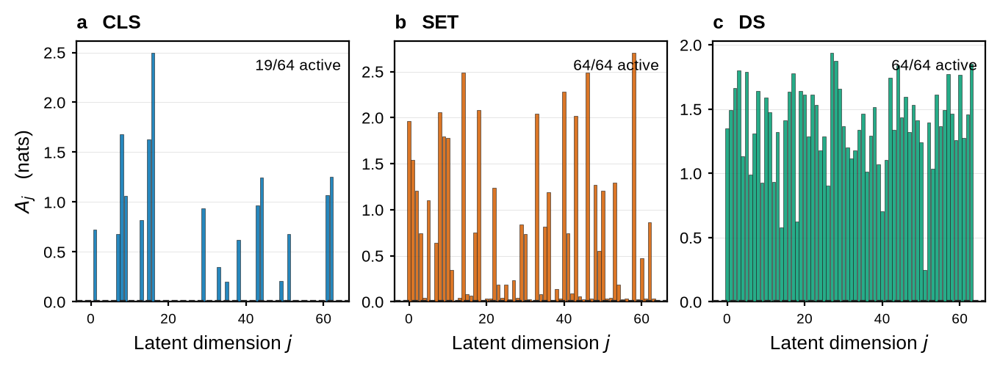

In [76]:
fig, ax = plt.subplots(1, 3, figsize=(6.69, 2.4), constrained_layout=True)

for i, name in enumerate(ARCHS):
    A = kl_syn[name]["A"]
    n = kl_syn[name]["active_units"]
    cols = [ARCH_COLORS[name] if a > 0.01 else GREY_INACT for a in A]
    ax[i].bar(np.arange(64), A, color=cols,
              edgecolor=GREY_EDGE, linewidth=0.25, width=0.88,
              alpha=0.85, zorder=3)
    ax[i].axhline(0.01, color=GREY_EDGE, ls="--", lw=0.8, zorder=4)
    ax[i].set_xlabel("Latent dimension $j$")
    if i == 0:
        ax[i].set_ylabel(r"$A_j$   (nats)")
    ax[i].text(0.97, 0.93, f"{n}/64 active", transform=ax[i].transAxes,
               ha="right", va="top", fontsize=7.5)
    ax[i].set_title(f"{chr(97+i)}   {name}", loc="left", fontweight="bold")
    ax[i].tick_params(axis="x", labelsize=7)
    style_axes(ax[i])

plt.savefig(FIG / "figure_kl_per_dim.pdf")
plt.savefig(FIG / "figure_5.png", dpi=600)

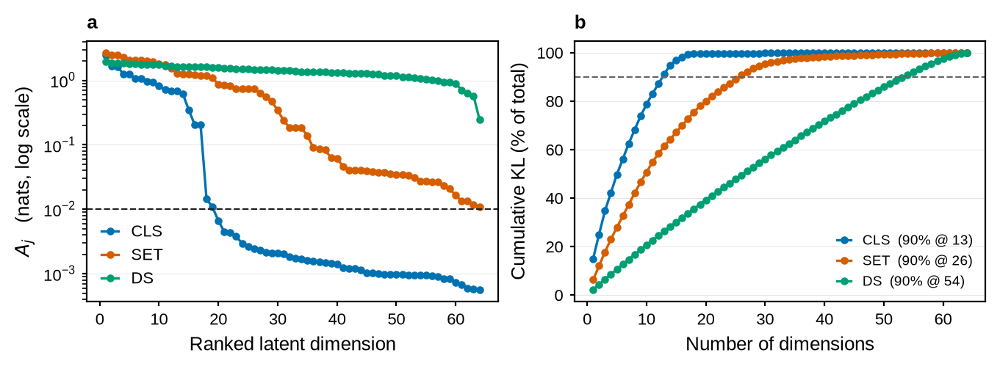

In [77]:
fig, ax = plt.subplots(1, 2, figsize=(6.69, 2.4), constrained_layout=True)

for name in ARCHS:
    A_sorted = np.sort(kl_syn[name]["A"])[::-1]
    ranks = np.arange(1, len(A_sorted) + 1)

    ax[0].plot(ranks, A_sorted, color=ARCH_COLORS[name],
               lw=1.2, marker="o", ms=2.8, label=name)
    cum = np.cumsum(A_sorted) / A_sorted.sum() * 100
    ax[1].plot(ranks, cum, color=ARCH_COLORS[name],
               lw=1.2, marker="o", ms=2.8,
               label=f"{name}  (90% @ {kl_syn[name]['n_to_90']})")

ax[0].axhline(0.01, color=GREY_EDGE, ls="--", lw=0.8)
ax[0].set_yscale("log")
ax[0].set_xlabel("Ranked latent dimension")
ax[0].set_ylabel(r"$A_j$   (nats, log scale)")
ax[0].legend(frameon=False, handlelength=1.0)
ax[0].set_title("a", loc="left", fontweight="bold")
style_axes(ax[0])

ax[1].axhline(90, color="#666666", ls="--", lw=0.8)
ax[1].set_xlabel("Number of dimensions")
ax[1].set_ylabel("Cumulative KL (% of total)")
ax[1].legend(frameon=False, handlelength=1.0, fontsize=7)
ax[1].set_title("b", loc="left", fontweight="bold")
style_axes(ax[1])

plt.savefig(FIG / "figure_kl_spectrum.pdf")
plt.savefig(FIG / "figure_6.png", dpi=600)

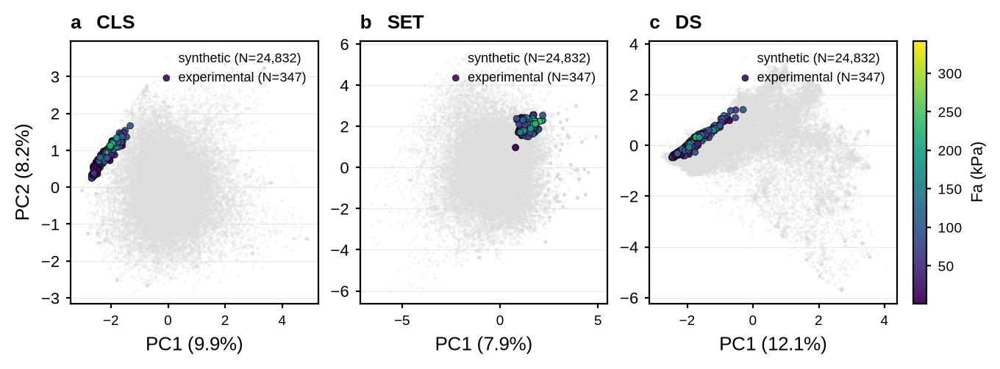

In [78]:
Z_SYN = {"CLS": z_cls, "SET": z_set, "DS": z_ds}

fig, ax = plt.subplots(1, 3, figsize=(6.69, 2.4), constrained_layout=True)

for i, name in enumerate(ARCHS):
    z_syn = Z_SYN[name]
    z_exp = z_dict[name]

    Zc  = np.vstack([z_syn, z_exp])
    pca = PCA(n_components=2, random_state=42).fit(Zc)

    S_syn = pca.transform(z_syn)
    S_exp = pca.transform(z_exp)

    ax[i].scatter(S_syn[:, 0], S_syn[:, 1], c="#DDDDDD", s=2, alpha=0.30,
                  edgecolors="none", label=f"synthetic (N={len(S_syn):,})")
    sc = ax[i].scatter(S_exp[:, 0], S_exp[:, 1], c=adhesion, cmap="viridis",
                       s=10, alpha=0.95, edgecolors="black", linewidths=0.25,
                       label=f"experimental (N={len(S_exp)})")

    ax[i].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    if i == 0:
        ax[i].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    ax[i].set_title(f"{chr(97+i)}   {name}", loc="left", fontweight="bold")
    ax[i].legend(frameon=False, loc="upper right", fontsize=6.5,
                 handlelength=1.0, handletextpad=0.4)
    ax[i].tick_params(axis="x", labelsize=7)
    style_axes(ax[i])

cbar = fig.colorbar(sc, ax=ax, orientation="vertical", fraction=0.02, pad=0.02)
cbar.set_label("Fa (kPa)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

plt.savefig(FIG / "figure_pca_overlay.pdf")
plt.savefig(FIG / "figure_7.png", dpi=600)

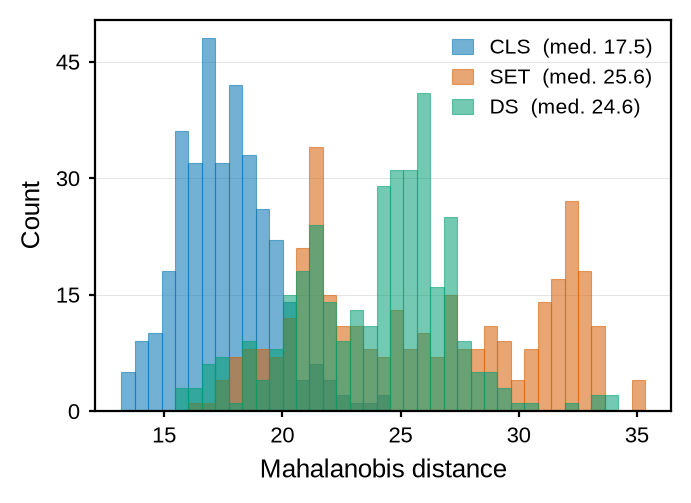

In [79]:
fig, ax = plt.subplots(figsize=(3.34, 2.4), constrained_layout=True)

bins = np.linspace(min(maha[a].min() for a in ARCHS),
                   max(maha[a].max() for a in ARCHS), 40)
for name in ARCHS:
    ax.hist(maha[name], bins=bins, alpha=0.55,
            color=ARCH_COLORS[name], edgecolor=ARCH_COLORS[name], linewidth=0.4,
            label=f"{name}  (med. {np.median(maha[name]):.1f})")

ax.set_xlabel("Mahalanobis distance")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.legend(frameon=False, fontsize=7.5, loc="upper right", handlelength=1.0)
ax.set_title("", loc="left", fontweight="bold")
style_axes(ax)

plt.savefig(FIG / "figure_mahalanobis.pdf")
plt.savefig(FIG / "figure_8.png", dpi=600)

In [ ]:
import numpy as np
from scipy.spatial.distance import cdist
from sklearn.covariance import LedoitWolf
from tqdm.auto import tqdm

Z_SYN = {"CLS": z_cls, "SET": z_set, "DS": z_ds}
Z_EXP = {a: z_dict[a] for a in ARCHS}

def isotropy(Z):
    Sigma = np.cov(Z, rowvar=False)
    d = np.sqrt(np.diag(Sigma).clip(min=1e-12))
    Sigma_norm = Sigma / np.outer(d, d)
    return float(np.linalg.norm(Sigma_norm - np.eye(len(d)), "fro"))

def _mmd(Xf, Yf, sigma):
    K = lambda A, B: np.exp(-cdist(A, B, "sqeuclidean") / (2 * sigma**2))
    return float(K(Xf, Xf).mean() + K(Yf, Yf).mean() - 2 * K(Xf, Yf).mean())

def mmd_rbf_common_sigma(X, Y, sigma, max_n=5000, seed=0):
    rng = np.random.default_rng(seed)
    Xf = X if len(X) <= max_n else X[rng.choice(len(X), max_n, replace=False)]
    Yf = Y if len(Y) <= max_n else Y[rng.choice(len(Y), max_n, replace=False)]
    return _mmd(Xf, Yf, sigma)

_pool = np.vstack([Z_SYN[a] for a in ARCHS] + [Z_EXP[a] for a in ARCHS])
_sq   = cdist(_pool, _pool, "sqeuclidean")
SIGMA_COMMON = float(np.sqrt(np.median(_sq[_sq > 0])))
print(f"common RBF σ = {SIGMA_COMMON:.3f}")

_lw = {a: LedoitWolf().fit(Z_SYN[a]) for a in ARCHS}
maha = {a: _lw[a].mahalanobis(Z_EXP[a]) for a in ARCHS}

N_BOOT = 500
ALPHA  = 0.05
SEED   = 42

def _summary(vals, point):
    lo, hi = np.quantile(vals, [ALPHA / 2, 1 - ALPHA / 2])
    return dict(point=float(point), lo=float(lo), hi=float(hi),
                boot=np.asarray(vals))

def boot_1sample(X, stat_fn, n_boot, seed=SEED, desc=""):
    rng   = np.random.default_rng(seed)
    point = float(stat_fn(X))
    vals  = np.empty(n_boot)
    for b in tqdm(range(n_boot), desc=desc, leave=False):
        idx = rng.integers(0, len(X), len(X))
        vals[b] = float(stat_fn(X[idx]))
    return _summary(vals, point)

def boot_maha_fixed_cov(Z_ref, Z_query, n_boot, seed=SEED, desc=""):
    rng   = np.random.default_rng(seed)
    lw    = LedoitWolf().fit(Z_ref)
    point = float(np.median(lw.mahalanobis(Z_query)))
    vals  = np.empty(n_boot)
    for b in tqdm(range(n_boot), desc=desc, leave=False):
        idx = rng.integers(0, len(Z_query), len(Z_query))
        vals[b] = float(np.median(lw.mahalanobis(Z_query[idx])))
    return _summary(vals, point)

def boot_mmd(X, Y, sigma, n_boot, max_n=5000, seed=SEED, desc=""):
    rng   = np.random.default_rng(seed)
    Xf0   = X if len(X) <= max_n else X[rng.choice(len(X), max_n, replace=False)]
    Yf0   = Y if len(Y) <= max_n else Y[rng.choice(len(Y), max_n, replace=False)]
    point = _mmd(Xf0, Yf0, sigma)
    vals  = np.empty(n_boot)
    for b in tqdm(range(n_boot), desc=desc, leave=False):
        xb = Xf0[rng.integers(0, len(Xf0), len(Xf0))]
        yb = Yf0[rng.integers(0, len(Yf0), len(Yf0))]
        vals[b] = _mmd(xb, yb, sigma)
    return _summary(vals, point)

iso_boot, mmd_boot, maha_boot = {}, {}, {}
for a in ARCHS:
    iso_boot[(a, "syn")] = boot_1sample(Z_SYN[a], isotropy, N_BOOT, desc=f"iso syn {a}")
    iso_boot[(a, "exp")] = boot_1sample(Z_EXP[a], isotropy, N_BOOT, desc=f"iso exp {a}")
    mmd_boot[a]          = boot_mmd(Z_SYN[a], Z_EXP[a], SIGMA_COMMON,
                                    N_BOOT, desc=f"mmd {a}")
    maha_boot[a]         = boot_maha_fixed_cov(Z_SYN[a], Z_EXP[a], N_BOOT,
                                               desc=f"maha {a}")

import pandas as pd
rows = []
for a in ARCHS:
    r = lambda s, p=2: (f"{s['point']:.{p}f} "
                        f"[{s['lo']:.{p}f}, {s['hi']:.{p}f}]")
    rows.append(dict(
        Architecture            = a,
        Isotropy_syn            = r(iso_boot[(a,"syn")]),
        Isotropy_exp            = r(iso_boot[(a,"exp")]),
        MMD2_common_sigma       = r(mmd_boot[a], 4),
        Mahalanobis_median      = r(maha_boot[a], 1),
    ))
df_ci = pd.DataFrame(rows).set_index("Architecture")
print("\n=== Table S7 (95% bootstrap CI, B=500) ===")
print(df_ci.to_string())
df_ci.to_csv("./data/DL/table_S7_with_CI.csv")

fig, ax = plt.subplots(1, 4, figsize=(6.69, 2.2), constrained_layout=True)

specs = [
    ("Isotropy (syn)", [iso_boot[(a, "syn")] for a in ARCHS]),
    ("Isotropy (exp)", [iso_boot[(a, "exp")] for a in ARCHS]),
    ("MMD$^2$",        [mmd_boot[a]          for a in ARCHS]),
    ("Mahalanobis",    [maha_boot[a]         for a in ARCHS]),
]

for p, (title, boots) in enumerate(specs):
    data = [b["boot"] for b in boots]
    parts = ax[p].violinplot(data, positions=[1, 2, 3], widths=0.75,
                             showextrema=False, showmedians=False)
    for pc, name in zip(parts["bodies"], ARCHS):
        pc.set_facecolor(ARCH_COLORS[name])
        pc.set_edgecolor(GREY_EDGE)
        pc.set_alpha(0.75)
        pc.set_linewidth(0.4)
    for k, (b, name) in enumerate(zip(boots, ARCHS)):
        ax[p].scatter(k + 1, b["point"], c="black", s=10, zorder=5,
                      edgecolors="white", linewidths=0.4)
    ax[p].set_xticks([1, 2, 3]); ax[p].set_xticklabels(ARCHS)
    ax[p].set_title(f"{chr(97+p)}   {title}", loc="left", fontweight="bold")
    ax[p].tick_params(axis="x", labelsize=7.5)
    ax[p].yaxis.set_major_locator(MaxNLocator(nbins=4))
    style_axes(ax[p])

plt.savefig(FIG / "figure_bootstrap.pdf")
plt.savefig(FIG / "figure_9.png", dpi=600)

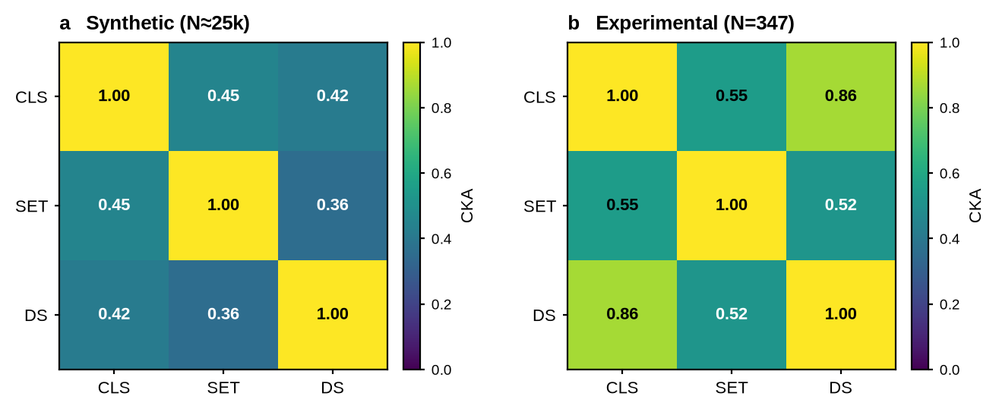

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(6.69, 2.6), constrained_layout=True)

for p, (title, M) in enumerate([("Synthetic (N≈25k)", cka_syn),
                                ("Experimental (N=347)", cka_exp)]):
    im = ax[p].imshow(M.values, cmap="viridis", vmin=0, vmax=1)
    ax[p].set_xticks(np.arange(3)); ax[p].set_xticklabels(ARCHS)
    ax[p].set_yticks(np.arange(3)); ax[p].set_yticklabels(ARCHS)
    for i in range(3):
        for j in range(3):
            v = M.values[i, j]
            ax[p].text(j, i, f"{v:.2f}", ha="center", va="center",
                       fontsize=8, fontweight="bold",
                       color="white" if v < 0.55 else "black")
    ax[p].set_title(f"{chr(97+p)}   {title}", loc="left", fontweight="bold")
    cbar = fig.colorbar(im, ax=ax[p], fraction=0.046, pad=0.04)
    cbar.set_label("CKA", fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    ax[p].grid(False)

plt.savefig(FIG / "figure_cka.pdf")
plt.savefig(FIG / "figure_10.png", dpi=600)